# lso

# Medi-Cal Capitation Project — Steps 1–6

**Step 1** builds a ZCTA-level Social Deprivation Index for California from ACS
5-year data and validates it against the published Robert Graham Center SDI.
**Step 2** builds the CDPS category reference and simulates the eligibility and
claims files that Step 3 will regress on.

This notebook is the **interactive surface** for SDI construction. Data
*acquisition* stays in scripts (slow, cached, run once):

| Script | Produces |
|---|---|
| `src/01_ca_zcta_universe.py` | `data/interim/ca_zcta_universe.csv` |
| `src/02_pull_acs.py` | `data/raw/acs2024_zcta_ca_raw.csv` (needs `CENSUS_API_KEY`) |

Everything downstream of those two files lives here, so thresholds can be
changed and the whole thing re-run in seconds.

**Deliverable:** `data/out/sdi_by_zcta.csv`

## 0. Setup

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import sdi_theme as T
T.apply_theme()

RAW = ROOT / "data" / "raw"
INTERIM = ROOT / "data" / "interim"
OUT = ROOT / "data" / "out"
FIGS = ROOT / "figures"
FIGS.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 60, "display.width", 200)
print("root:", ROOT)

root: /home/garyc/analysis/dhcs


### Configuration

Every analytic choice is here. Change a threshold, restart-and-run-all, and the
diagnostics below update.

In [3]:
ACS_YEAR = 2024          # ACS 5-year end year -> 2020-2024 vintage

# Inclusion thresholds. ACS 5-year estimates at ZCTA level get noisy on small
# bases; DHCS-style analysis suppresses rather than mapping at full confidence.
MIN_POP = 500            # total population
MIN_HOUSEHOLDS = 100     # occupied units
MIN_POV_UNIVERSE = 500   # population for whom poverty status is determined
MAX_GQ_SHARE = 0.50      # group-quarters share of population

# The eight SDI components.
COMPONENTS = [
    "pct_lt_hs", "pct_poverty", "pct_single_parent", "pct_renter",
    "pct_no_vehicle", "pct_unemployed", "pct_crowded", "log_pop_density",
]

LABELS = {
    "pct_lt_hs": "No HS diploma (25+)",
    "pct_poverty": "In poverty",
    "pct_single_parent": "Single-parent families",
    "pct_renter": "Renter-occupied",
    "pct_no_vehicle": "No vehicle",
    "pct_unemployed": "Unemployed",
    "pct_crowded": "Crowded (>1/room)",
    "log_pop_density": "log population density",
}

## 1. California ZCTA universe

ZCTAs are national geographies with no state field, so California membership
comes from the 2020 ZCTA-to-county relationship file: a ZCTA is in CA if any of
its land falls in a state-FIPS-06 county. A handful straddle the NV/AZ/OR line
and are flagged via `ca_land_share`.

In [4]:
geo = pd.read_csv(INTERIM / "ca_zcta_universe.csv", dtype={"zcta": str})

summary = pd.DataFrame({
    "metric": ["ZCTAs with any CA land", "wholly in CA (share >= 0.999)",
               "straddling a state line", "missing gazetteer land area"],
    "n": [len(geo), int((geo.ca_land_share >= 0.999).sum()),
          int((geo.ca_land_share < 0.999).sum()), int(geo.aland_sqmi.isna().sum())],
})
T.style_table(summary.style, caption="CA ZCTA universe", fmt={"n": "{:,.0f}"})

metric,n
ZCTAs with any CA land,"1,808"
wholly in CA (share >= 0.999),"1,802"
straddling a state line,6
missing gazetteer land area,0


In [5]:
straddlers = geo[geo.ca_land_share < 0.999][
    ["zcta", "primary_county_name", "ca_land_share", "aland_sqmi"]
].sort_values("ca_land_share")
T.style_table(straddlers.style, caption="ZCTAs straddling the state line",
              fmt={"ca_land_share": "{:.3f}", "aland_sqmi": "{:,.1f}"})

zcta,primary_county_name,ca_land_share,aland_sqmi
89060,Inyo County,0.019,449.4
89010,Mono County,0.038,384.3
89061,Inyo County,0.044,64.0
89019,San Bernardino County,0.224,499.6
89439,Sierra County,0.257,16.3
97635,Modoc County,0.928,52.2


## 2. ACS source variables

Pulled by `src/02_pull_acs.py`. Since the 2020 geography change the ACS API no
longer accepts a `state:` predicate on ZCTAs, so the script pulls all ~33k
national ZCTAs and inner-joins to the universe above.

In [6]:
acs_path = RAW / f"acs{ACS_YEAR}_zcta_ca_raw.csv"
if not acs_path.exists():
    raise FileNotFoundError(
        f"{acs_path} missing. Run:\n"
        f"  CENSUS_API_KEY=$(cat {ROOT}/.census_api_key) "
        f"python src/02_pull_acs.py --year {ACS_YEAR}"
    )
acs = pd.read_csv(acs_path, dtype={"zcta": str})
df = geo.merge(acs, on="zcta", how="left")
print(f"{len(df)} ZCTAs x {len(acs.columns) - 1} ACS variables")

1808 ZCTAs x 42 ACS variables


In [7]:

dictionary = pd.DataFrame([
    ("Population",            "B01003", "001",              "denominator / size filter"),
    ("Group quarters",        "B26001", "001",              "dorm / barracks / prison filter"),
    ("Education",             "B15003", "002-016 / 001",    "% no regular HS diploma, age 25+"),
    ("Poverty",               "B17001", "002 / 001",        "% below 100% FPL"),
    ("Single-parent families","B11003", "010+016 / 001",    "% families, one parent, own children <18"),
    ("Tenure",                "B25003", "003 / 001",        "% renter-occupied"),
    ("Vehicles",              "B25044", "003+010 / 001",    "% households with no vehicle"),
    ("Employment",            "B23025", "005 / 003",        "% unemployed, civilian labor force"),
    ("Crowding",              "B25014", "005-007+011-013 / 001", "% units >1 occupant per room"),
    ("Land area",             "Gazetteer", "ALAND_SQMI",    "density denominator"),
], columns=["Concept", "Table", "Lines", "Derived measure"])
T.style_table(dictionary.style, caption=f"ACS {ACS_YEAR-4}-{ACS_YEAR} 5-year source variables")\
    .set_properties(**{"text-align": "left"})

Concept,Table,Lines,Derived measure
Population,B01003,001,denominator / size filter
Group quarters,B26001,001,dorm / barracks / prison filter
Education,B15003,002-016 / 001,"% no regular HS diploma, age 25+"
Poverty,B17001,002 / 001,% below 100% FPL
Single-parent families,B11003,010+016 / 001,"% families, one parent, own children <18"
Tenure,B25003,003 / 001,% renter-occupied
Vehicles,B25044,003+010 / 001,% households with no vehicle
Employment,B23025,005 / 003,"% unemployed, civilian labor force"
Crowding,B25014,005-007+011-013 / 001,% units >1 occupant per room
Land area,Gazetteer,ALAND_SQMI,density denominator


## 3. Component construction

Each component is a rate. Denominators are guarded: a zero denominator yields
`NaN` rather than an inf or a divide-by-zero, so a ZCTA with no households drops
out of the composite instead of poisoning it.

In [8]:
def safe_ratio(num, den):
    """num/den as a percentage, NaN where the denominator is zero or missing."""
    return num / den.where(den > 0) * 100

EDU_LT_HS = [f"B15003_{i:03d}E" for i in range(2, 17)]
CROWD = [f"B25014_{i:03d}E" for i in (5, 6, 7, 11, 12, 13)]

df["pop_total"]    = df["B01003_001E"]
df["hh_total"]     = df["B25003_001E"]
df["pov_universe"] = df["B17001_001E"]
df["gq_pop"]       = df["B26001_001E"]

df["pct_lt_hs"]         = safe_ratio(df[EDU_LT_HS].sum(axis=1), df["B15003_001E"])
df["pct_poverty"]       = safe_ratio(df["B17001_002E"], df["B17001_001E"])
df["pct_single_parent"] = safe_ratio(df["B11003_010E"] + df["B11003_016E"], df["B11003_001E"])
df["pct_renter"]        = safe_ratio(df["B25003_003E"], df["B25003_001E"])
df["pct_no_vehicle"]    = safe_ratio(df["B25044_003E"] + df["B25044_010E"], df["B25044_001E"])
df["pct_unemployed"]    = safe_ratio(df["B23025_005E"], df["B23025_003E"])
df["pct_crowded"]       = safe_ratio(df[CROWD].sum(axis=1), df["B25014_001E"])

# Density spans rural desert to dense LA, so z-scoring it raw would let a few
# ZCTAs dominate the composite. Log first.
df["pop_density"]     = df["pop_total"] / df["aland_sqmi"].where(df["aland_sqmi"] > 0)
df["log_pop_density"] = np.log1p(df["pop_density"])

df["gq_share"] = df["gq_pop"] / df["pop_total"].where(df["pop_total"] > 0)
# ACS MOEs are 90% CI half-widths, so CV = (MOE/1.645)/estimate.
df["pop_cv"] = (df["B01003_001M"] / 1.645) / df["pop_total"].where(df["pop_total"] > 0)

df[COMPONENTS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pct_lt_hs,1765.0,13.54,12.62,0.0,4.37,9.77,19.51,82.71
pct_poverty,1740.0,13.52,12.07,0.0,6.78,10.56,17.08,100.00
pct_single_parent,1713.0,11.20,9.52,0.0,5.78,9.99,15.06,100.00
pct_renter,1733.0,38.84,21.89,0.0,23.77,35.83,51.31,100.00
pct_no_vehicle,1733.0,6.22,8.50,0.0,2.17,4.44,7.38,100.00
pct_unemployed,1745.0,7.25,7.54,0.0,4.29,6.03,8.55,100.00
pct_crowded,1733.0,6.76,7.22,0.0,1.76,4.71,9.71,70.45
log_pop_density,1808.0,6.00,2.83,0.0,3.72,6.59,8.55,10.90


## 4. Inclusion screen

Six of the eight components are **household** rates, so a ZCTA that is mostly
dorms, barracks, or prison cells produces rates computed off an unrepresentative
remainder. Without a group-quarters screen, CSU Northridge ranks as the single
most deprived ZCTA in California — 100% "poverty" measured on four households.

In [9]:
df["flag_small_pop"] = df.pop_total.fillna(0) < MIN_POP
df["flag_small_hh"] = (
    (df.hh_total.fillna(0) < MIN_HOUSEHOLDS)
    | (df.pov_universe.fillna(0) < MIN_POV_UNIVERSE)
)
df["flag_group_quarters"] = df.gq_share.fillna(0) > MAX_GQ_SHARE
df["flag_straddles_state"] = df.ca_land_share < 0.999
df["n_components_missing"] = df[COMPONENTS].isna().sum(axis=1)

df["include_analysis"] = (
    ~df.flag_small_pop & ~df.flag_small_hh & ~df.flag_group_quarters
    & (df.n_components_missing == 0)
)

# Cascade: each rule charged only with what it removes that earlier rules did not.
rules = [
    (f"population < {MIN_POP}", df.flag_small_pop),
    (f"households < {MIN_HOUSEHOLDS} or poverty universe < {MIN_POV_UNIVERSE}", df.flag_small_hh),
    (f"group quarters > {MAX_GQ_SHARE:.0%} of population", df.flag_group_quarters),
    ("a component could not be computed", df.n_components_missing > 0),
]
rows, remaining = [], pd.Series(True, index=df.index)
for name, flag in rules:
    dropped = remaining & flag
    remaining = remaining & ~flag
    rows.append({"Screen": name, "Newly excluded": int(dropped.sum()),
                 "Remaining": int(remaining.sum())})
cascade = pd.DataFrame(
    [{"Screen": "all CA ZCTAs", "Newly excluded": 0, "Remaining": len(df)}] + rows
)
T.style_table(cascade.style, caption="Inclusion cascade",
              fmt={"Newly excluded": "{:,.0f}", "Remaining": "{:,.0f}"})\
    .set_properties(subset=["Screen"], **{"text-align": "left"})

Screen,Newly excluded,Remaining
all CA ZCTAs,0,"1,808"
population < 500,273,"1,535"
households < 100 or poverty universe < 500,31,"1,504"
group quarters > 50% of population,7,"1,497"
a component could not be computed,0,"1,497"


In [10]:
pop_kept = df.loc[df.include_analysis, "pop_total"].sum()
pop_all = df.pop_total.sum()
print(f"Analysis set: {int(df.include_analysis.sum()):,} ZCTAs")
print(f"Population covered: {pop_kept/1e6:.1f}M of {pop_all/1e6:.1f}M "
      f"({pop_kept/pop_all:.1%} of the state)")

Analysis set: 1,497 ZCTAs
Population covered: 39.1M of 39.3M (99.5% of the state)


### Figure 1 — why the group-quarters screen exists

Institutional ZCTAs sit in a band of their own: nearly all residents in group
quarters, a handful of households left to carry every household rate.

findfont: Failed to find font weight semibold, now using 700.


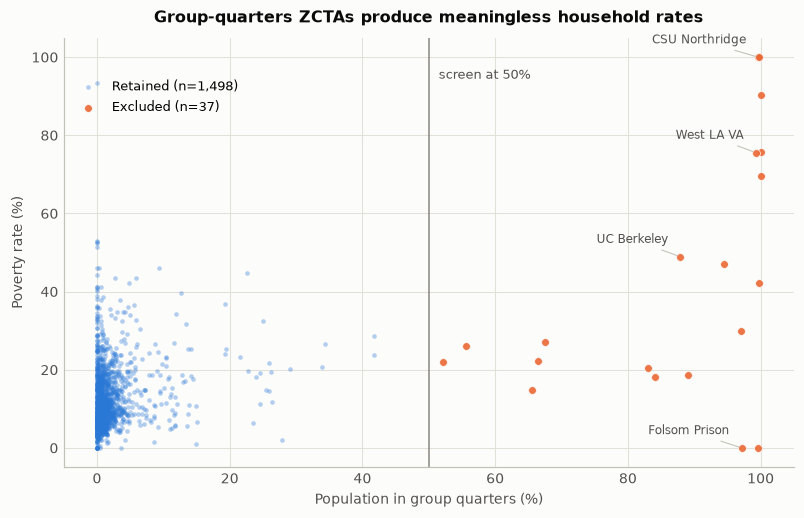

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 4.6))
d = df[df.pop_total.fillna(0) >= MIN_POP].copy()
keep, drop = d[~d.flag_group_quarters], d[d.flag_group_quarters]

ax.scatter(keep.gq_share * 100, keep.pct_poverty, s=9, c=T.BLUE, alpha=.35,
           linewidths=0, label=f"Retained (n={len(keep):,})")
ax.scatter(drop.gq_share * 100, drop.pct_poverty, s=26, c=T.ORANGE, alpha=.9,
           linewidths=.5, edgecolors=T.SURFACE, label=f"Excluded (n={len(drop):,})")
ax.axvline(MAX_GQ_SHARE * 100, color=T.INK_MUTED, lw=1)
ax.text(MAX_GQ_SHARE * 100 + 1.5, 97, f"screen at {MAX_GQ_SHARE:.0%}",
        color=T.INK_SECONDARY, fontsize=8.5, va="top")

# Label only the cases that make the point, not every excluded mark.
for z, name in [("91330", "CSU Northridge"), ("94720", "UC Berkeley"),
                ("90073", "West LA VA"), ("95671", "Folsom Prison")]:
    r = d[d.zcta == z]
    if not r.empty:
        r = r.iloc[0]
        ax.annotate(name, (r.gq_share * 100, r.pct_poverty),
                    xytext=(-8, 9), textcoords="offset points", fontsize=8,
                    color=T.INK_SECONDARY, ha="right",
                    arrowprops=dict(arrowstyle="-", color=T.AXIS, lw=.7))

ax.set_xlabel("Population in group quarters (%)")
ax.set_ylabel("Poverty rate (%)")
ax.set_title("Group-quarters ZCTAs produce meaningless household rates")
ax.legend(loc="upper left", bbox_to_anchor=(0, .93))
fig.savefig(FIGS / "01_group_quarters_screen.png")
plt.show()

### Figure 2 — component distributions (analysis set)

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


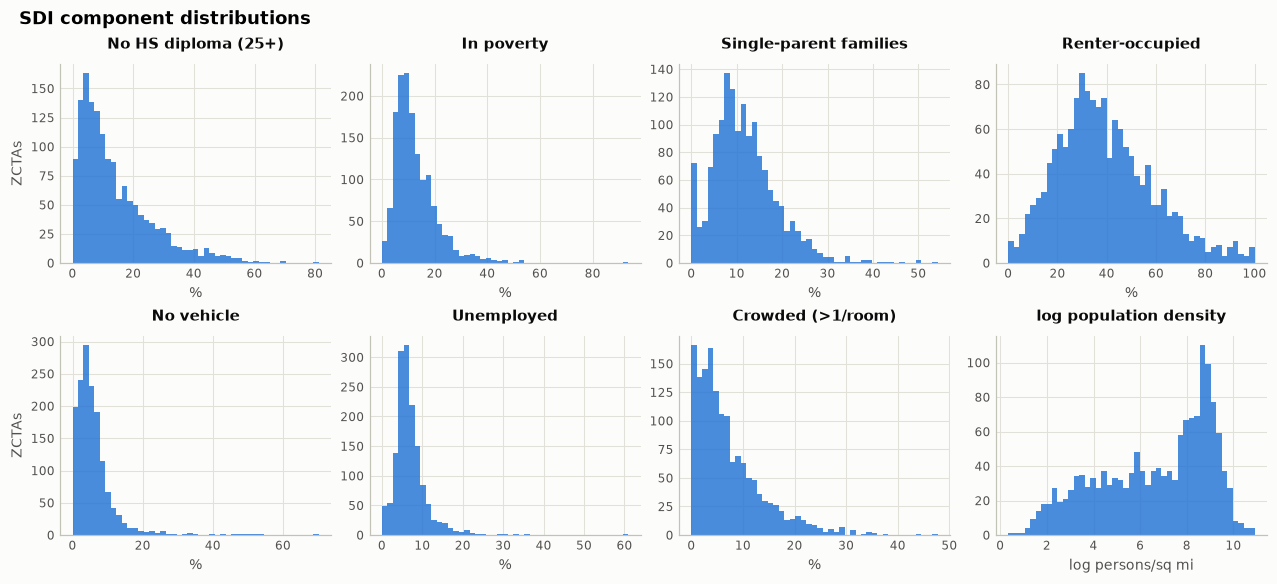

In [12]:
fit = df[df.include_analysis]

fig, axes = plt.subplots(2, 4, figsize=(11.5, 5.2))
for ax, c in zip(axes.ravel(), COMPONENTS):
    ax.hist(fit[c].dropna(), bins=45, color=T.BLUE, alpha=.85)
    ax.set_title(LABELS[c], fontsize=9.5)
    ax.set_xlabel("log persons/sq mi" if c == "log_pop_density" else "%")
    ax.tick_params(labelsize=8)
axes[0, 0].set_ylabel("ZCTAs")
axes[1, 0].set_ylabel("ZCTAs")
fig.suptitle("SDI component distributions", fontsize=11.5, fontweight="semibold", x=.01, ha="left")
fig.savefig(FIGS / "02_component_distributions.png")
plt.show()

### Figure 3 — component correlations

Components should be positively correlated but not redundant. Anything near
r = 1 would mean we are counting the same thing twice.

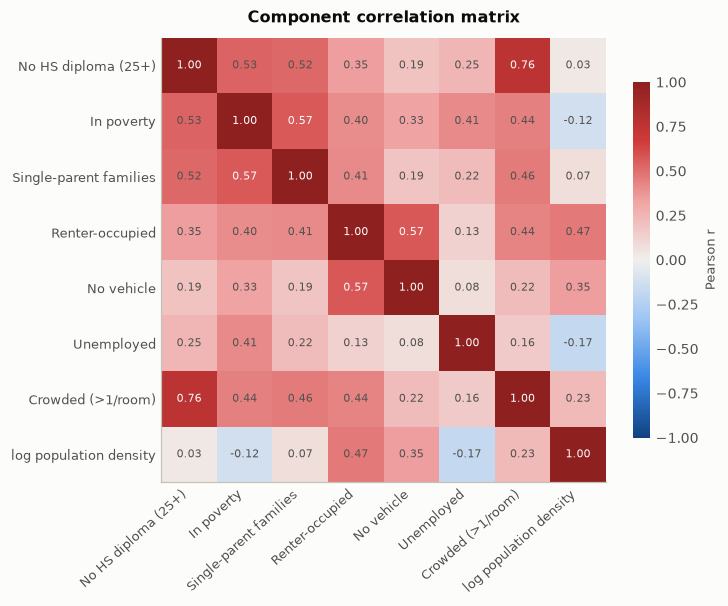

In [13]:
corr = fit[COMPONENTS].corr()
names = [LABELS[c] for c in COMPONENTS]

fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(corr, cmap=T.DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=42, ha="right", fontsize=8.5)
ax.set_yticks(range(len(names)), names, fontsize=8.5)
ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color=T.SURFACE if abs(v) > .55 else T.INK_SECONDARY)
cb = fig.colorbar(im, ax=ax, shrink=.8)
cb.set_label("Pearson r", color=T.INK_SECONDARY, fontsize=8.5)
cb.outline.set_visible(False)
ax.set_title("Component correlation matrix")
fig.savefig(FIGS / "03_component_correlations.png")
plt.show()

## 5. Composite construction

Two methods, as specified:

- **Equal-weight** — unweighted mean of component z-scores (Butler et al. 2013).
- **PCA** — first principal component of the standardized components.

Both are standardized on the analysis set only, then applied to every ZCTA, so
excluded ZCTAs cannot shift the mean or SD.

In [14]:
mu, sd = fit[COMPONENTS].mean(), fit[COMPONENTS].std(ddof=0)
Z = (df[COMPONENTS] - mu) / sd
Z.columns = [f"z_{c}" for c in COMPONENTS]
df = pd.concat([df.drop(columns=Z.columns, errors="ignore"), Z], axis=1)

# (a) equal weight
df["sdi_z_mean"] = Z.mean(axis=1)

# (b) PCA via SVD on the analysis set
Zf = Z.loc[df.include_analysis].to_numpy()
Zc = Zf - Zf.mean(axis=0)
_, S, Vt = np.linalg.svd(Zc, full_matrices=False)
loadings = Vt[0]
# Fix the sign so that higher always means more deprived.
if np.corrcoef(Zc @ loadings, Zc[:, COMPONENTS.index("pct_poverty")])[0, 1] < 0:
    loadings = -loadings
var_explained = S**2 / (S**2).sum()
df["sdi_pca"] = Z.to_numpy() @ loadings

print(f"PC1 explains {var_explained[0]:.1%} of variance (PC2 {var_explained[1]:.1%})")

PC1 explains 41.6% of variance (PC2 20.1%)


### Figure 4 — PC1 loadings and scree

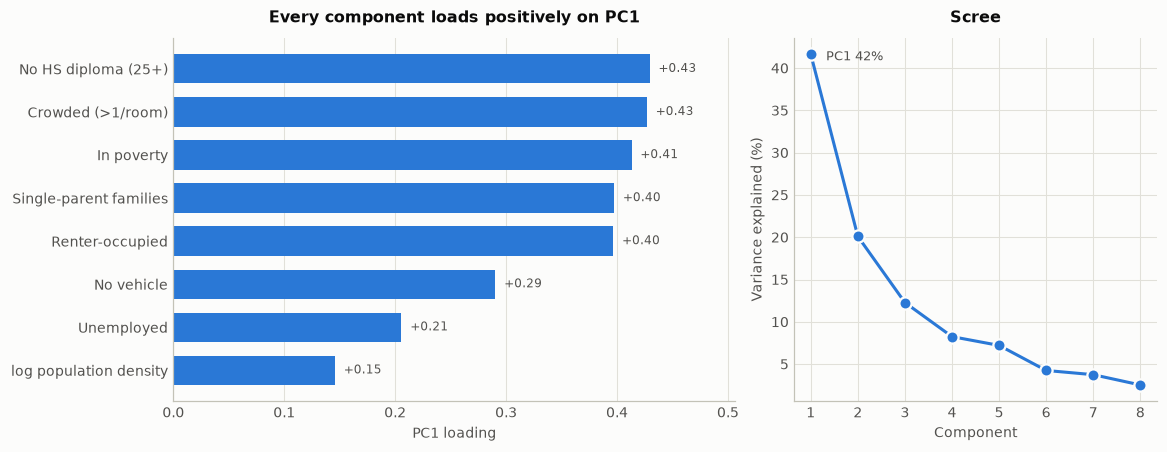

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.0),
                               gridspec_kw={"width_ratios": [1.55, 1]})

order = np.argsort(loadings)
ax1.barh([LABELS[COMPONENTS[i]] for i in order], loadings[order],
         color=T.BLUE, height=.68)
ax1.set_xlabel("PC1 loading")
ax1.set_title("Every component loads positively on PC1")
ax1.grid(axis="y", visible=False)
for i, v in enumerate(loadings[order]):
    ax1.text(v + .008, i, f"{v:+.2f}", va="center", fontsize=8, color=T.INK_SECONDARY)
ax1.set_xlim(0, max(loadings) * 1.18)

ax2.plot(range(1, len(var_explained) + 1), var_explained * 100, marker="o",
         color=T.BLUE, markeredgecolor=T.SURFACE, markeredgewidth=1.5)
ax2.set_xlabel("Component")
ax2.set_ylabel("Variance explained (%)")
ax2.set_title("Scree")
ax2.set_xticks(range(1, len(var_explained) + 1))
ax2.annotate(f"PC1 {var_explained[0]:.0%}", (1, var_explained[0] * 100),
             xytext=(10, -4), textcoords="offset points",
             fontsize=8.5, color=T.INK_SECONDARY)
fig.savefig(FIGS / "04_pca_loadings.png")
plt.show()

Now scale both composites. Three forms are kept: the raw score, a 0–100 min-max
rescale, and a percentile — the percentile is the form the Robert Graham Center
publishes, so it is the one that supports comparison in section 7.

In [16]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min()) * 100

def pctile(s):
    return s.rank(pct=True, na_option="keep") * 100

for base in ("sdi_z_mean", "sdi_pca"):
    s = df[base].where(df.include_analysis)
    df[f"{base}_score"] = minmax(s)
    df[f"{base}_pctile"] = pctile(s)

# Headline SDI = equal-weight, matching the published method.
df["sdi_score"] = df["sdi_z_mean_score"]
df["sdi_pctile"] = df["sdi_z_mean_pctile"]
df["sdi_rank"] = df.sdi_z_mean.where(df.include_analysis).rank(ascending=False, method="min")

agree = df.loc[df.include_analysis, ["sdi_z_mean", "sdi_pca"]].corr().iloc[0, 1]
print(f"Equal-weight vs PCA composite: r = {agree:.4f}")

Equal-weight vs PCA composite: r = 0.9886


### Figure 5 — do the two weighting schemes agree?

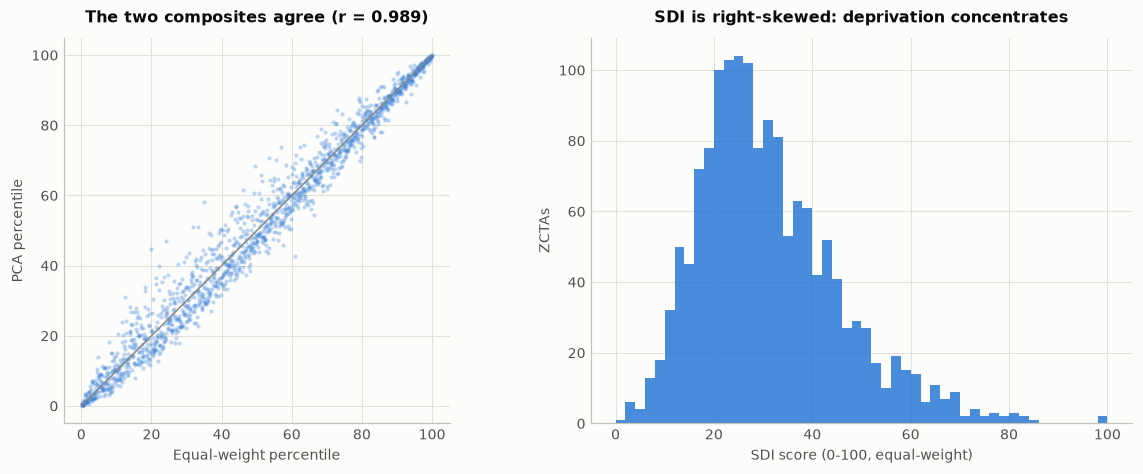

In [17]:
a = df[df.include_analysis]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))

ax1.scatter(a.sdi_z_mean_pctile, a.sdi_pca_pctile, s=7, c=T.BLUE, alpha=.3, linewidths=0)
ax1.plot([0, 100], [0, 100], color=T.INK_MUTED, lw=1)
ax1.set_xlabel("Equal-weight percentile")
ax1.set_ylabel("PCA percentile")
ax1.set_title(f"The two composites agree (r = {agree:.3f})")
ax1.set_aspect("equal")

ax2.hist(a.sdi_score, bins=50, color=T.BLUE, alpha=.85)
ax2.set_xlabel("SDI score (0-100, equal-weight)")
ax2.set_ylabel("ZCTAs")
ax2.set_title("SDI is right-skewed: deprivation concentrates")
fig.savefig(FIGS / "05_composite_agreement.png")
plt.show()

## 6. Results

In [18]:
show = ["zcta", "primary_county_name", "pop_total", "pct_poverty",
        "pct_lt_hs", "pct_crowded", "sdi_score", "sdi_pctile"]
fmt = {"pop_total": "{:,.0f}", "pct_poverty": "{:.1f}", "pct_lt_hs": "{:.1f}",
       "pct_crowded": "{:.1f}", "sdi_score": "{:.1f}", "sdi_pctile": "{:.1f}"}
ranked = a.sort_values("sdi_score", ascending=False)

T.style_table(ranked.head(15)[show].style,
              caption="15 most deprived ZCTAs", fmt=fmt)\
    .set_properties(subset=["primary_county_name"], **{"text-align": "left"})

zcta,primary_county_name,pop_total,pct_poverty,pct_lt_hs,pct_crowded,sdi_score,sdi_pctile
91963,San Diego County,689,93.5,68.8,47.7,100.0,100.0
92327,San Bernardino County,576,53.0,5.1,31.1,99.8,99.9
90057,Los Angeles County,"46,629",27.9,42.6,33.0,85.8,99.9
90021,Los Angeles County,"2,897",46.1,33.7,19.1,83.9,99.8
90007,Los Angeles County,"38,715",39.6,35.5,18.5,82.9,99.7
94108,San Francisco County,"11,305",21.3,25.3,15.6,81.5,99.7
90017,Los Angeles County,"30,172",34.0,27.1,23.8,80.8,99.6
93666,Tulare County,633,41.2,63.6,31.6,80.4,99.5
93701,Fresno County,"9,808",38.5,47.5,23.4,79.0,99.5
93721,Fresno County,"7,225",28.6,31.9,8.9,78.7,99.4


In [19]:
T.style_table(ranked.tail(15)[show].iloc[::-1].style,
              caption="15 least deprived ZCTAs", fmt=fmt)\
    .set_properties(subset=["primary_county_name"], **{"text-align": "left"})

zcta,primary_county_name,pop_total,pct_poverty,pct_lt_hs,pct_crowded,sdi_score,sdi_pctile
93531,Kern County,515,0.0,1.7,0.0,0.0,0.1
93604,Madera County,710,14.8,0.0,0.0,2.7,0.1
96128,Lassen County,656,0.5,4.3,4.8,3.6,0.2
95962,Yuba County,"1,110",1.1,8.1,0.0,3.8,0.3
92678,Orange County,664,8.3,2.1,0.0,3.8,0.3
95251,Calaveras County,701,1.9,0.0,0.0,3.9,0.4
93424,San Luis Obispo County,962,6.5,3.5,0.0,3.9,0.5
95563,Trinity County,577,0.0,0.0,0.0,4.1,0.5
93541,Mono County,970,0.0,0.0,0.0,4.3,0.6
95636,El Dorado County,"1,410",1.6,3.7,4.4,4.5,0.7


### Figure 6 — geographic pattern

A centroid scatter, not a choropleth — this is the preview of what becomes the
ArcGIS map in Step 5. Longitude is stretched by 1/cos(latitude) so California is
not squashed.

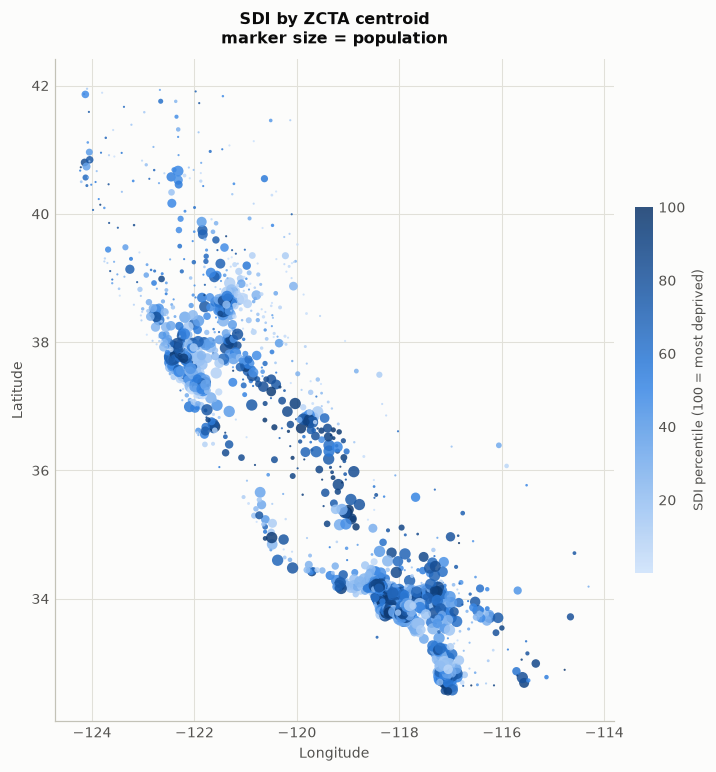

In [20]:
fig, ax = plt.subplots(figsize=(6.4, 8.0))
sc = ax.scatter(a.lon, a.lat, c=a.sdi_pctile, cmap=T.SEQ,
                s=np.clip(a.pop_total / 900, 2, 55),
                alpha=.85, linewidths=0)
cb = fig.colorbar(sc, ax=ax, shrink=.42, pad=.02)
cb.set_label("SDI percentile (100 = most deprived)", color=T.INK_SECONDARY, fontsize=8.5)
cb.outline.set_visible(False)
ax.set_aspect(1 / np.cos(np.radians(37)))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("SDI by ZCTA centroid\nmarker size = population")
fig.savefig(FIGS / "06_sdi_map_preview.png")
plt.show()

### County roll-up (population-weighted)

In [21]:
cty = (a.assign(w=a.pop_total)
        .groupby("primary_county_name")
        .apply(lambda g: pd.Series({
            "ZCTAs": len(g),
            "Population": g.pop_total.sum(),
            "Mean SDI pctile": np.average(g.sdi_pctile, weights=g.w),
            "Poverty %": np.average(g.pct_poverty, weights=g.w),
        }), include_groups=False)
        .sort_values("Mean SDI pctile", ascending=False))

cfmt = {"ZCTAs": "{:,.0f}", "Population": "{:,.0f}",
        "Mean SDI pctile": "{:.1f}", "Poverty %": "{:.1f}"}
top = cty.head(10).reset_index().rename(columns={"primary_county_name": "County"})
T.style_table(top.style, caption="10 most deprived counties (population-weighted)", fmt=cfmt)\
    .set_properties(subset=["County"], **{"text-align": "left"})

County,ZCTAs,Population,Mean SDI pctile,Poverty %
Merced County,17,"287,933",79.9,19.1
Imperial County,12,"173,718",78.7,19.7
San Francisco County,26,"829,981",76.0,11.1
Kings County,7,"151,417",74.9,16.4
Tulare County,29,"503,523",73.2,17.9
Fresno County,45,"987,370",71.3,18.4
Los Angeles County,274,"9,792,260",69.8,13.8
Kern County,35,"903,096",69.7,19.1
Monterey County,25,"427,458",69.1,12.8
Madera County,12,"162,809",67.5,19.0


## 7. Validation against the published Robert Graham Center SDI

The RGC file is ACS 2015–2019; ours is ACS 2020–2024. This is a **face-validity
check** — rank agreement and known-place spot checks — not an identity test.
Four things differ by construction:

1. **Components.** RGC uses 7; we add population density (per the project spec
   and Butler et al. 2013).
2. **Employment.** RGC uses *nonemployed* (not working, 16–64); we use
   *unemployed* (civilian labor force), the narrower measure.
3. **Reference population.** RGC percentiles are national; ours are within
   California. Not the same scale by construction.
4. **Vintage.** Five years apart, spanning the pandemic and the 2020 ZCTA
   boundary redefinition.

In [22]:
rgc = pd.read_csv(RAW / "rgc_sdi_2015_2019_zcta.csv", dtype={"ZCTA5_FIPS": str})
rgc = rgc.rename(columns={"ZCTA5_FIPS": "zcta", "SDI_score": "rgc_sdi"})
v = df.merge(rgc[["zcta", "rgc_sdi", "pct_Poverty_LT100", "pct_Education_LT12years"]],
             on="zcta", how="left")
val = v[v.include_analysis & v.rgc_sdi.notna()].copy()

def spearman(x, y):
    """Pearson on ranks - avoids a scipy dependency."""
    return x.rank().corr(y.rank())

agreement = pd.DataFrame([
    {"Composite": "Equal-weight", "Pearson r": val.sdi_pctile.corr(val.rgc_sdi),
     "Spearman rho": spearman(val.sdi_pctile, val.rgc_sdi)},
    {"Composite": "PCA", "Pearson r": val.sdi_pca_pctile.corr(val.rgc_sdi),
     "Spearman rho": spearman(val.sdi_pca_pctile, val.rgc_sdi)},
])
print(f"Matched to a published RGC score: {len(val):,} of {int(df.include_analysis.sum()):,}")
T.style_table(agreement.style, caption="Rank agreement with published RGC SDI",
              fmt={"Pearson r": "{:.3f}", "Spearman rho": "{:.3f}"})\
    .set_properties(subset=["Composite"], **{"text-align": "left"})

Matched to a published RGC score: 1,492 of 1,497


Composite,Pearson r,Spearman rho
Equal-weight,0.842,0.844
PCA,0.872,0.873


### Figure 7 — constructed vs. published

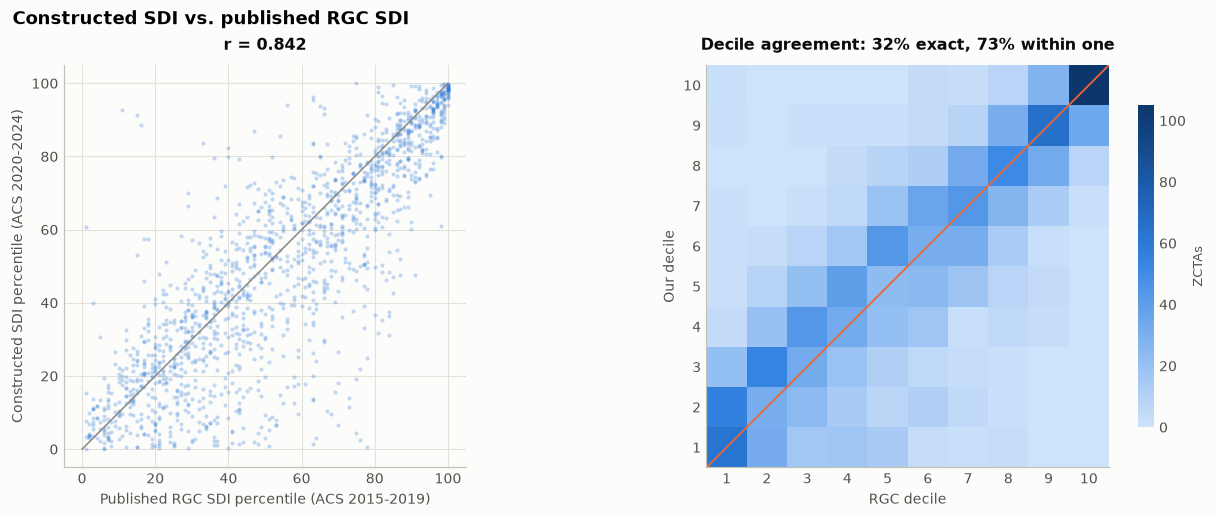

In [23]:

val["decile_ours"] = pd.qcut(val.sdi_pctile, 10, labels=range(1, 11)).astype(int)
val["decile_rgc"] = pd.qcut(val.rgc_sdi.rank(method="first"), 10, labels=range(1, 11)).astype(int)
exact = (val.decile_ours == val.decile_rgc).mean()
within1 = ((val.decile_ours - val.decile_rgc).abs() <= 1).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6),
                               gridspec_kw={"width_ratios": [1, 1.1]})

ax1.scatter(val.rgc_sdi, val.sdi_pctile, s=7, c=T.BLUE, alpha=.28, linewidths=0)
ax1.plot([0, 100], [0, 100], color=T.INK_MUTED, lw=1)
ax1.set_xlabel("Published RGC SDI percentile (ACS 2015-2019)")
ax1.set_ylabel("Constructed SDI percentile (ACS 2020-2024)")
ax1.set_title(f"r = {val.sdi_pctile.corr(val.rgc_sdi):.3f}")
ax1.set_aspect("equal")

ct = pd.crosstab(val.decile_ours, val.decile_rgc)
im = ax2.imshow(ct, cmap=T.SEQ, origin="lower", extent=(.5, 10.5, .5, 10.5))
ax2.plot([.5, 10.5], [.5, 10.5], color=T.ORANGE, lw=1.2)
ax2.set_xlabel("RGC decile")
ax2.set_ylabel("Our decile")
ax2.set_xticks(range(1, 11)); ax2.set_yticks(range(1, 11))
ax2.grid(False)
ax2.set_title(f"Decile agreement: {exact:.0%} exact, {within1:.0%} within one")
cb = fig.colorbar(im, ax=ax2, shrink=.8); cb.set_label("ZCTAs", fontsize=8.5,
                                                       color=T.INK_SECONDARY)
cb.outline.set_visible(False)
fig.suptitle("Constructed SDI vs. published RGC SDI", fontsize=11.5,
             fontweight="semibold", x=.01, ha="left")
fig.savefig(FIGS / "07_validation_vs_rgc.png")
plt.show()

### Known-place spot checks

In [24]:
KNOWN = {
    "93706": "Fresno, southwest",
    "94102": "San Francisco, Tenderloin",
    "90011": "South Los Angeles",
    "90057": "LA, Westlake / MacArthur Park",
    "92231": "Calexico, Imperial County",
    "95202": "Downtown Stockton",
    "94301": "Palo Alto",
    "92657": "Newport Coast",
    "90274": "Palos Verdes Estates",
    "94024": "Los Altos",
    "94027": "Atherton",
}
rows = []
for z, place in KNOWN.items():
    r = v[v.zcta == z]
    if r.empty:
        continue
    r = r.iloc[0]
    rows.append({"ZCTA": z, "Place": place, "Ours": r.sdi_pctile,
                 "RGC": r.rgc_sdi, "Diff": r.sdi_pctile - r.rgc_sdi})
spot = pd.DataFrame(rows).sort_values("Ours", ascending=False)

T.style_table(spot.style, caption="Known-place spot checks (percentile; 100 = most deprived)",
              fmt={"Ours": "{:.0f}", "RGC": "{:.0f}", "Diff": "{:+.0f}"})\
    .set_properties(subset=["Place"], **{"text-align": "left"})\
    .background_gradient(subset=["Diff"], cmap=T.DIV, vmin=-40, vmax=40)

ZCTA,Place,Ours,RGC,Diff
90057,"LA, Westlake / MacArthur Park",100,100,-0
94102,"San Francisco, Tenderloin",99,91,+8
95202,Downtown Stockton,99,100,-1
90011,South Los Angeles,99,100,-1
93706,"Fresno, southwest",98,100,-2
92231,"Calexico, Imperial County",91,90,+1
94301,Palo Alto,48,37,+11
92657,Newport Coast,13,7,+6
90274,Palos Verdes Estates,8,4,+4
94024,Los Altos,8,1,+7


### Figure 8 — where the two indices disagree

The disagreements are not random: they concentrate in small-population ZCTAs,
which is exactly what ACS margins of error predict. This is the small-ZCTA noise
problem the project spec flagged, showing up where it should.

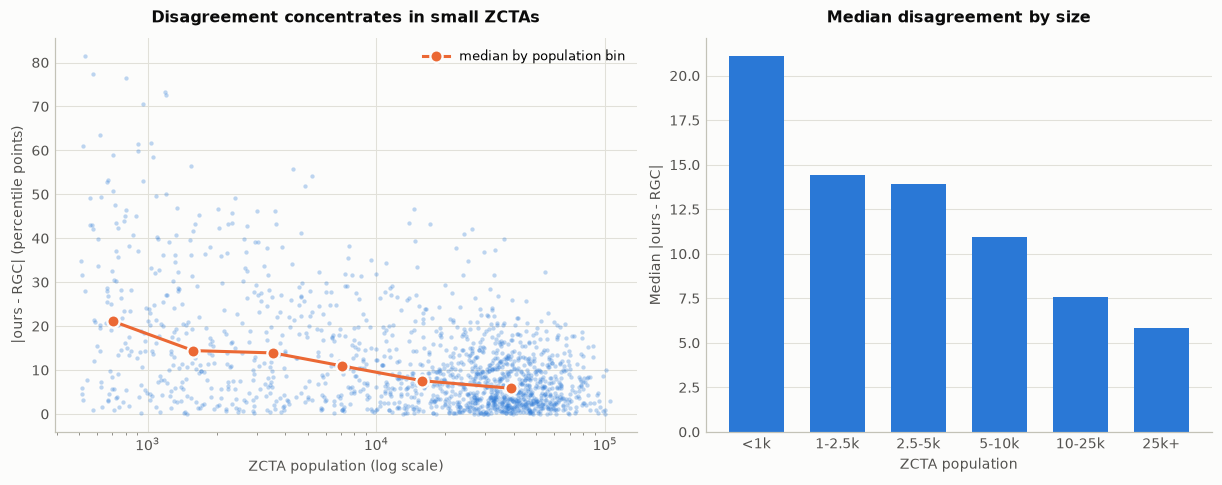

In [25]:
val["gap"] = val.sdi_pctile - val.rgc_sdi

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3),
                               gridspec_kw={"width_ratios": [1.15, 1]})

ax1.scatter(val.pop_total, val.gap.abs(), s=8, c=T.BLUE, alpha=.3, linewidths=0)
ax1.set_xscale("log")
ax1.set_xlabel("ZCTA population (log scale)")
ax1.set_ylabel("|ours - RGC| (percentile points)")
ax1.set_title("Disagreement concentrates in small ZCTAs")

bins = [0, 1000, 2500, 5000, 10000, 25000, np.inf]
names = ["<1k", "1-2.5k", "2.5-5k", "5-10k", "10-25k", "25k+"]
val["popbin"] = pd.cut(val.pop_total, bins, labels=names)
med = val.groupby("popbin", observed=True).gap.apply(lambda s: s.abs().median())
ax1.plot(
    [np.sqrt(max(lo, 500) * (hi if np.isfinite(hi) else 6e4))
     for lo, hi in zip(bins[:-1], bins[1:])],
    med.reindex(names).values, color=T.ORANGE, marker="o",
    markeredgecolor=T.SURFACE, markeredgewidth=1.5, label="median by population bin")
ax1.legend(loc="upper right")

ax2.bar(names, med.reindex(names).values, color=T.BLUE, width=.68)
ax2.set_xlabel("ZCTA population")
ax2.set_ylabel("Median |ours - RGC|")
ax2.set_title("Median disagreement by size")
ax2.grid(axis="x", visible=False)
fig.savefig(FIGS / "08_disagreement_vs_population.png")
plt.show()

In [26]:
big = val.reindex(val.gap.abs().sort_values(ascending=False).index).head(12)
T.style_table(
    big[["zcta", "primary_county_name", "pop_total", "sdi_pctile", "rgc_sdi", "gap"]]
      .rename(columns={"zcta": "ZCTA", "primary_county_name": "County",
                       "pop_total": "Population", "sdi_pctile": "Ours",
                       "rgc_sdi": "RGC", "gap": "Diff"}).style,
    caption="Largest disagreements - note the population column",
    fmt={"Population": "{:,.0f}", "Ours": "{:.0f}", "RGC": "{:.0f}", "Diff": "{:+.0f}"})\
    .set_properties(subset=["County"], **{"text-align": "left"})\
    .background_gradient(subset=["Diff"], cmap=T.DIV, vmin=-90, vmax=90)

ZCTA,County,Population,Ours,RGC,Diff
95537,Humboldt County,532,93,11,+82
95563,Trinity County,577,1,78,-77
95697,Yolo County,800,91,15,+76
93440,Santa Barbara County,"1,185",3,76,-73
91934,San Diego County,"1,200",89,16,+73
95556,Humboldt County,949,4,75,-71
95659,Sutter County,617,6,70,-64
94933,Marin County,"1,033",11,73,-62
95227,San Joaquin County,910,2,63,-61
95543,Del Norte County,523,3,64,-61


## 8. Export

In [27]:
cols = (
    ["zcta", "primary_county_name", "primary_county_fips", "pop_total",
     "hh_total", "pov_universe", "gq_pop", "gq_share", "aland_sqmi", "lat", "lon"]
    + COMPONENTS + ["pop_density"]
    + [f"z_{c}" for c in COMPONENTS]
    + ["sdi_z_mean", "sdi_z_mean_score", "sdi_z_mean_pctile",
       "sdi_pca", "sdi_pca_score", "sdi_pca_pctile",
       "sdi_score", "sdi_pctile", "sdi_rank", "pop_cv",
       "flag_small_pop", "flag_small_hh", "flag_group_quarters",
       "flag_straddles_state", "n_components_missing", "include_analysis"]
)
out = df[cols].sort_values("zcta")
OUT.mkdir(parents=True, exist_ok=True)
out.to_csv(OUT / "sdi_by_zcta.csv", index=False)
print(f"wrote {OUT / 'sdi_by_zcta.csv'}  ({len(out):,} rows x {len(cols)} cols)")
print(f"figures in {FIGS}")

wrote /home/garyc/analysis/dhcs/data/out/sdi_by_zcta.csv  (1,808 rows x 44 cols)
figures in /home/garyc/analysis/dhcs/figures


---

# Step 2 — CDPS reference and simulated eligibility & claims

Builds the diagnosis-classification scaffolding and then the synthetic person-year
and claims data that Step 3 regresses on.

**Configuration decisions for this run**

| Decision | Choice |
|---|---|
| Simulation scale | 250,000 person-years, single year |
| Rate structure | rate region × aid category × age band |
| Crosswalk depth | 19 major categories, 57 CDPS categories with severity tiers |

**On the CDPS categories.** The actual ICD→CDPS crosswalk is license-gated by
UCSD, so the code lists below are a *representative subset*, not the real
crosswalk. What is real: the category codes and severity-tier naming
(`PSYH`/`PSYM`/`PSYML`/`PSYL`, `PULVH`/`PULH`/`PULM`/`PULL`, …), the 19
major-category structure, the hierarchy rule, and the ICD-10 codes themselves.
Sources are the public CDPS 7.0 update summary and usage guidelines in
`data/raw/cdps_*.pdf`.

**The ground truth.** Section 2.4 fixes the parameters we bake in — above all
`B_SDI`, the deprivation→morbidity link. Step 3 tries to recover the category
weights; the SDI relationship is what the whole project is ultimately asking
about, so it is documented explicitly at the point it is created.

## 2.1 CDPS category reference

Severity suffixes follow CDPS convention: `EH` extra-high, `VH` very-high,
`H` high, `M` medium, `ML` medium-low, `L` low, `VL` very-low. Within a major
category the tiers are **hierarchical** — a person qualifying for more than one
keeps only the highest, which is applied in section 2.6.

In [28]:

CDPS_SPEC = [
    # major,            code,     tier, label,                            prev, weight, morb, rx
    ("Cardiovascular",  "CARVH",  1, "Cardiovascular, very high",      0.0016, 26000, 1.5, 1),
    ("Cardiovascular",  "CARM",   2, "Cardiovascular, medium",         0.0120,  7400, 1.2, 1),
    ("Cardiovascular",  "CARL",   3, "Cardiovascular, low",            0.0330,  2300, 1.0, 1),
    ("Cardiovascular",  "CAREL",  4, "Cardiovascular, extra low",      0.0480,   950, 0.8, 0),
    ("Psychiatric",     "PSYH",   1, "Psychiatric, high",              0.0042, 17500, 1.3, 1),
    ("Psychiatric",     "PSYM",   2, "Psychiatric, medium",            0.0180,  7100, 1.1, 1),
    ("Psychiatric",     "PSYML",  3, "Psychiatric, medium low",        0.0290,  3400, 0.9, 1),
    ("Psychiatric",     "PSYL",   4, "Psychiatric, low",               0.0560,  1500, 0.8, 1),
    ("Skeletal",        "SKCM",   1, "Skeletal, medium",               0.0075,  6200, 1.0, 0),
    ("Skeletal",        "SKCL",   2, "Skeletal, low",                  0.0260,  1900, 0.8, 0),
    ("Skeletal",        "SKCVL",  3, "Skeletal, very low",             0.0430,   780, 0.6, 0),
    ("CNS",             "CNSH",   1, "Central nervous system, high",   0.0021, 21000, 1.4, 1),
    ("CNS",             "CNSM",   2, "Central nervous system, medium", 0.0068,  6800, 1.1, 1),
    ("CNS",             "CNSL",   3, "Central nervous system, low",    0.0190,  2100, 0.9, 1),
    ("Pulmonary",       "PULVH",  1, "Pulmonary, very high",           0.0009, 31000, 1.5, 1),
    ("Pulmonary",       "PULH",   2, "Pulmonary, high",                0.0038, 12500, 1.2, 1),
    ("Pulmonary",       "PULM",   3, "Pulmonary, medium",              0.0150,  4300, 1.0, 1),
    ("Pulmonary",       "PULL",   4, "Pulmonary, low",                 0.0620,  1250, 0.7, 1),
    ("Gastrointestinal","GIH",    1, "Gastrointestinal, high",         0.0026, 19000, 1.3, 1),
    ("Gastrointestinal","GIM",    2, "Gastrointestinal, medium",       0.0110,  5600, 1.0, 1),
    ("Gastrointestinal","GIL",    3, "Gastrointestinal, low",          0.0340,  1700, 0.8, 0),
    ("Diabetes",        "DIA1H",  1, "Diabetes type 1, high",          0.0014, 15500, 1.2, 1),
    ("Diabetes",        "DIA1M",  2, "Diabetes type 1, medium",        0.0032,  8200, 1.1, 1),
    ("Diabetes",        "DIA2M",  3, "Diabetes type 2, medium",        0.0190,  4600, 1.0, 1),
    ("Diabetes",        "DIA2L",  4, "Diabetes type 2, low",           0.0310,  2000, 0.9, 1),
    ("Skin",            "SKNH",   1, "Skin, high",                     0.0011, 13000, 1.1, 0),
    ("Skin",            "SKNL",   2, "Skin, low",                      0.0140,  1600, 0.7, 0),
    ("Renal",           "RENEH",  1, "Renal, extra high",              0.0011, 62000, 1.6, 1),
    ("Renal",           "RENM",   2, "Renal, medium",                  0.0058, 11000, 1.3, 1),
    ("Renal",           "RENL",   3, "Renal, low",                     0.0130,  3100, 1.0, 0),
    ("Substance Abuse", "SUBL",   1, "Substance abuse, low",           0.0230,  4200, 1.0, 1),
    ("Substance Abuse", "SUBVL",  2, "Substance abuse, very low",      0.0290,  1400, 0.8, 0),
    ("Cancer",          "CANVH",  1, "Cancer, very high",              0.0008, 47000, 1.5, 1),
    ("Cancer",          "CANH",   2, "Cancer, high",                   0.0016, 24000, 1.3, 1),
    ("Cancer",          "CANM",   3, "Cancer, medium",                 0.0037, 10500, 1.1, 1),
    ("Cancer",          "CANL",   4, "Cancer, low",                    0.0089,  3300, 0.9, 0),
    ("Developmental",   "DDM",    1, "Developmental disability, med",  0.0038,  9800, 1.1, 0),
    ("Developmental",   "DDL",    2, "Developmental disability, low",  0.0092,  2600, 0.9, 0),
    ("Metabolic",       "METH",   1, "Metabolic, high",                0.0013, 16000, 1.2, 1),
    ("Metabolic",       "METM",   2, "Metabolic, medium",              0.0071,  4900, 1.0, 1),
    ("Metabolic",       "METVL",  3, "Metabolic, very low",            0.0250,   850, 0.7, 0),
    ("Pregnancy",       "PRGINC", 1, "Pregnancy, incomplete",          0.0120, 12500, 0.4, 0),
    ("Pregnancy",       "PRGCMP", 2, "Pregnancy, complete",            0.0210,  7800, 0.3, 0),
    ("Eye",             "EYEL",   1, "Eye, low",                       0.0084,  1900, 0.7, 0),
    ("Eye",             "EYEVL",  2, "Eye, very low",                  0.0190,   700, 0.5, 0),
    ("Hematological",   "HEMEH",  1, "Hematological, extra high",      0.0006, 55000, 1.5, 1),
    ("Hematological",   "HEMVH",  2, "Hematological, very high",       0.0013, 23000, 1.3, 1),
    ("Hematological",   "HEMM",   3, "Hematological, medium",          0.0044,  6400, 1.0, 1),
    ("Hematological",   "HEML",   4, "Hematological, low",             0.0110,  2200, 0.8, 0),
    ("Infectious",      "INFVH",  1, "Infectious disease, very high",  0.0015, 33000, 1.4, 1),
    ("Infectious",      "INFH",   2, "Infectious disease, high",       0.0024, 14000, 1.2, 1),
    ("Infectious",      "INFM",   3, "Infectious disease, medium",     0.0061,  4700, 1.0, 1),
    ("Infectious",      "INFL",   4, "Infectious disease, low",        0.0170,  1300, 0.8, 0),
    ("Cerebrovascular", "CERM",   1, "Cerebrovascular, medium",        0.0029,  9200, 1.2, 0),
    ("Cerebrovascular", "CERL",   2, "Cerebrovascular, low",           0.0074,  2700, 1.0, 0),
    ("Genital",         "GENL",   1, "Genital, low",                   0.0096,  2400, 0.8, 0),
    ("Genital",         "GENEL",  2, "Genital, extra low",             0.0180,   820, 0.6, 0),
]
cdps = pd.DataFrame(CDPS_SPEC, columns=[
    "major_category", "cdps_code", "tier", "label",
    "prevalence", "true_weight", "morbidity_sens", "is_rx"])

print(f"{len(cdps)} CDPS categories across {cdps.major_category.nunique()} major groups")
cdps.head(12)

57 CDPS categories across 19 major groups


,major_category,cdps_code,tier,label,prevalence,true_weight,morbidity_sens,is_rx
0,Cardiovascular,CARVH,1,"Cardiovascular, very high",0.0016,26000,1.5,1
1,Cardiovascular,CARM,2,"Cardiovascular, medium",0.0120,7400,1.2,1
2,Cardiovascular,CARL,3,"Cardiovascular, low",0.0330,2300,1.0,1
3,Cardiovascular,CAREL,4,"Cardiovascular, extra low",0.0480,950,0.8,0
4,Psychiatric,PSYH,1,"Psychiatric, high",0.0042,17500,1.3,1
5,Psychiatric,PSYM,2,"Psychiatric, medium",0.0180,7100,1.1,1
6,Psychiatric,PSYML,3,"Psychiatric, medium low",0.0290,3400,0.9,1
7,Psychiatric,PSYL,4,"Psychiatric, low",0.0560,1500,0.8,1
8,Skeletal,SKCM,1,"Skeletal, medium",0.0075,6200,1.0,0
9,Skeletal,SKCL,2,"Skeletal, low",0.0260,1900,0.8,0


### Figure 9 — the category weight hierarchy

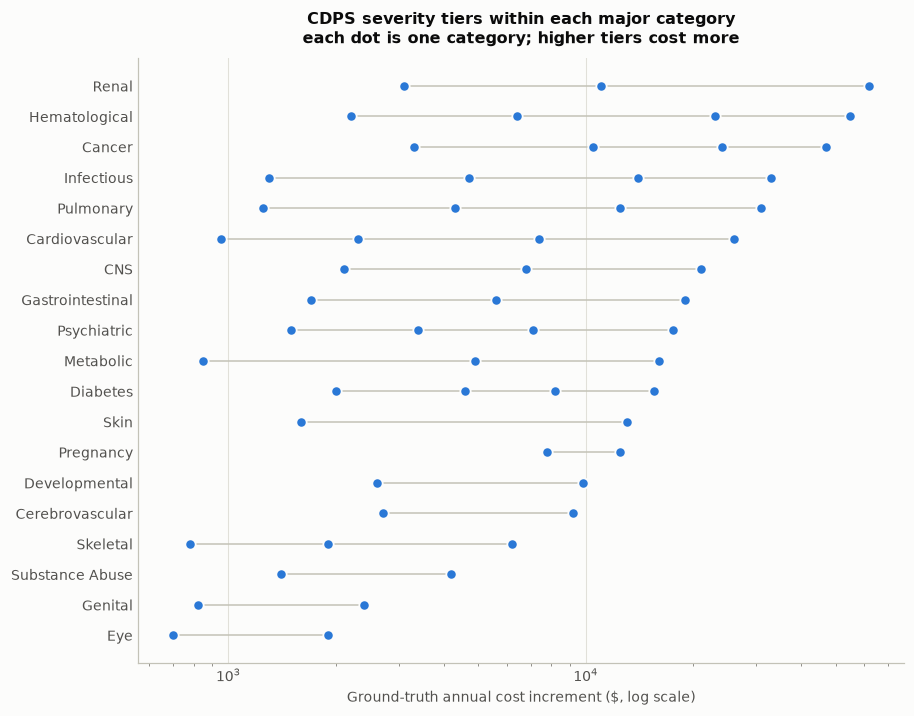

In [29]:
fig, ax = plt.subplots(figsize=(8.2, 6.4))
majors = (cdps.groupby("major_category").true_weight.max()
              .sort_values().index.tolist())
ypos = {m: i for i, m in enumerate(majors)}

for m in majors:
    g = cdps[cdps.major_category == m].sort_values("tier")
    
    ax.plot(g.true_weight, [ypos[m]] * len(g), color=T.AXIS, lw=1, zorder=1)
    ax.scatter(g.true_weight, [ypos[m]] * len(g), s=46, c=T.BLUE,
               zorder=2, linewidths=1.2, edgecolors=T.SURFACE)

ax.set_yticks(range(len(majors)), majors)
ax.set_xscale("log")
ax.set_xlabel("Ground-truth annual cost increment ($, log scale)")
ax.set_title("CDPS severity tiers within each major category\n"
             "each dot is one category; higher tiers cost more")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "09_cdps_weight_hierarchy.png")
plt.show()

## 2.2 ICD-10 crosswalk and Rx classes

Two guards matter here, because Step 3 rebuilds category flags **from the claims
alone**. If one ICD code mapped to two categories, or if a "routine encounter"
code collided with a real category, Step 3 would silently manufacture false
positives. Both are asserted rather than assumed.

In [30]:

ICD = {
"CARVH":["I501","I5021","I5023","I5031","I5041","I420","Z9581","I469"],
"CARM": ["I2510","I255","I480","I4891","I340","I350","I429"],
"CARL": ["I110","I739","I2589","I441","I495"],
"CAREL":["I10","I878","I839"],
"PSYH": ["F200","F209","F250","F259","F3113","F312"],
"PSYM": ["F310","F319","F603","F840","F500","F942"],
"PSYML":["F332","F333","F411","F431","F340"],
"PSYL": ["F329","F339","F419","F418","F5101"],
"SKCM": ["M0579","M0609","M321","M348"],
"SKCL": ["M199","M5416","M5136","M810"],
"SKCVL":["M545","M549","M255","M797"],
"CNSH": ["G8220","G8250","G35","G1221"],
"CNSM": ["G40909","G20","G809"],
"CNSL": ["G43909","G629","G560"],
"PULVH":["E840","E849","Z991","Z930"],
"PULH": ["J841","J703","J681"],
"PULM": ["J449","J440","J441","J189"],
"PULL": ["J453","J454","J45909","J209"],
"GIH":  ["K5000","K5190","K720","K912"],
"GIM":  ["K7030","K7469","K5660"],
"GIL":  ["K219","K589","K649"],
"DIA1H":["E1010","E1011","E1065"],
"DIA1M":["E109","E1029","E1039"],
"DIA2M":["E1122","E1140","E1165","E1129"],
"DIA2L":["E119","E1159","E1169"],
"SKNH": ["L89154","L89894","L512"],
"SKNL": ["L409","L309","L039"],
"RENEH":["N186","Z992","Z940"],
"RENM": ["N184","N183","N185","N310"],
"RENL": ["N189","N130","N319"],
"SUBL": ["F1120","F1420","F1020","F1520"],
"SUBVL":["F1010","F1210","F17200"],
"CANVH":["C7800","C7951","C9200","C349"],
"CANH": ["C259","C220","C787"],
"CANM": ["C509","C61","C189"],
"CANL": ["C4490","C44319","C73","C8100"],
"DDM":  ["F72","F73","F79"],
"DDL":  ["F70","F71","F88"],
"METH": ["E71310","E7400","E7603"],
"METM": ["E271","E220","E890"],
"METVL":["E039","E059","E785","E559"],
"PRGINC":["O0990","O2690","O36819"],
"PRGCMP":["O80","O82","Z370","O3421"],
"EYEL": ["H3500","H409","H3320"],
"EYEVL":["H259","H524","H109"],
"HEMEH":["D66","D67","D68311"],
"HEMVH":["D601","D6109","D5700"],
"HEMM": ["D559","D571","D709"],
"HEML": ["D509","D649","D759","D65"],
"INFVH":["B20","A481","B59"],
"INFH": ["A419","A150","B182"],
"INFM": ["A047","B1920","A409"],
"INFL": ["B029","B159","N390","B349"],
"CERM": ["I639","I619","I609"],
"CERL": ["I6930","I6523","G459"],
"GENL": ["N809","N920","N8320"],
"GENEL":["N760","N946","N393"],
}

# Routine / preventive encounters that map to no CDPS category.
NON_CDPS = ["Z0000","Z0001","Z1231","Z23","J069","R519","Z7689",
            "H6690","K0889","S0101XA","R0789","Z013","Z0289"]

# --- guards: Step 3 depends on these holding -------------------------------
assert not (set(cdps.cdps_code) - set(ICD)), "a CDPS category has no ICD codes"
pairs = [(c, cat) for cat, lst in ICD.items() for c in lst]
dupes = {c for c, n in pd.Series([c for c, _ in pairs]).value_counts().items() if n > 1}
assert not dupes, f"ICD code maps to multiple categories: {dupes}"
overlap = set(NON_CDPS) & {c for c, _ in pairs}
assert not overlap, f"non-CDPS code collides with a CDPS code: {overlap}"

crosswalk = pd.DataFrame(pairs, columns=["icd_code", "cdps_code"])
print(f"{len(crosswalk)} ICD-10 codes -> {crosswalk.cdps_code.nunique()} categories; "
      f"{len(NON_CDPS)} non-CDPS codes. Guards passed.")

209 ICD-10 codes -> 57 categories; 13 non-CDPS codes. Guards passed.


In [31]:

RX_CLASS = {
"CARVH":"loop diuretic / inotrope", "CARM":"antiarrhythmic", "CARL":"beta blocker",
"PSYH":"antipsychotic, 2nd gen", "PSYM":"mood stabilizer", "PSYML":"SNRI", "PSYL":"SSRI",
"CNSH":"MS disease-modifying", "CNSM":"anticonvulsant", "CNSL":"triptan",
"PULVH":"CFTR modulator", "PULH":"antifibrotic", "PULM":"LAMA/LABA inhaler",
"PULL":"ICS inhaler", "GIH":"biologic, anti-TNF", "GIM":"lactulose / rifaximin",
"DIA1H":"insulin, rapid-acting", "DIA1M":"insulin, long-acting",
"DIA2M":"GLP-1 agonist", "DIA2L":"metformin",
"RENEH":"ESA / phosphate binder", "RENM":"phosphate binder",
"SUBL":"buprenorphine / naltrexone", "CANVH":"chemotherapy, IV",
"CANH":"targeted oncology oral", "CANM":"hormonal oncology",
"METH":"enzyme replacement", "METM":"corticosteroid replacement",
"HEMEH":"factor concentrate", "HEMVH":"immunosuppressant", "HEMM":"hydroxyurea",
"INFVH":"antiretroviral", "INFH":"hep C DAA / anti-TB", "INFM":"IV antibiotic",
}

# Synthetic NDCs in valid 5-4-2 shape. Real NDC assignment would require the FDA
# NDC directory plus a therapeutic-class mapping; these are structurally valid
# but are NOT real products. Flagged in the limitations table at the end.
_rng_ndc = np.random.default_rng(20240115)
NDC = {c: [f"{_rng_ndc.integers(10000,99999)}-{_rng_ndc.integers(1000,9999)}-"
           f"{_rng_ndc.integers(10,99)}" for _ in range(3)] for c in RX_CLASS}

sample = pd.DataFrame([
    {"CDPS": c, "Tier": int(cdps.loc[cdps.cdps_code == c, "tier"].iloc[0]),
     "Example ICD-10": ", ".join(ICD[c][:4]),
     "Rx class": RX_CLASS.get(c, "-")}
    for c in ["CARVH", "PSYH", "PULM", "DIA2L", "RENEH", "CANVH", "INFVH", "HEMEH"]])
T.style_table(sample.style, caption="Crosswalk sample")\
    .set_properties(subset=["Example ICD-10", "Rx class"], **{"text-align": "left"})

CDPS,Tier,Example ICD-10,Rx class
CARVH,1,"I501, I5021, I5023, I5031",loop diuretic / inotrope
PSYH,1,"F200, F209, F250, F259","antipsychotic, 2nd gen"
PULM,3,"J449, J440, J441, J189",LAMA/LABA inhaler
DIA2L,4,"E119, E1159, E1169",metformin
RENEH,1,"N186, Z992, Z940",ESA / phosphate binder
CANVH,1,"C7800, C7951, C9200, C349","chemotherapy, IV"
INFVH,1,"B20, A481, B59",antiretroviral
HEMEH,1,"D66, D67, D68311",factor concentrate


## 2.3 Rate regions and managed-care plans

Medi-Cal sets capitation by rate region, not statewide. This is a simplified
six-region stand-in built from county FIPS — enough to give Step 4 real
geographic rate variation.

In [32]:
REGION_BY_COUNTY = {
 "Los Angeles": ["06037"],
 "Bay Area": ["06001","06013","06041","06075","06081","06085","06097","06055","06095"],
 "Sacramento Valley": ["06067","06061","06113","06101","06115","06057","06017"],
 "Central Valley": ["06019","06029","06031","06039","06047","06077","06099","06107",
                    "06009","06043","06109","06011","06021"],
 "Southern": ["06059","06065","06071","06073","06111","06083","06079","06053"],
 "Rural North & Mountain": ["06007","06103","06089","06015","06023","06005","06093",
                            "06105","06035","06063","06049","06045","06033","06091",
                            "06003","06051","06027","06025","06069","06087"],
}
COUNTY_TO_REGION = {c: r for r, cs in REGION_BY_COUNTY.items() for c in cs}

PLANS_BY_REGION = {
 "Los Angeles": ["LA-HealthNet", "LA-LACare", "LA-Molina", "LA-Anthem"],
 "Bay Area": ["BA-AllianceCC", "BA-SFHP", "BA-SantaClaraFHP"],
 "Sacramento Valley": ["SV-Anthem", "SV-Molina", "SV-KaiserGMC"],
 "Central Valley": ["CV-HealthNet", "CV-KernFHC", "CV-Anthem", "CV-CalViva"],
 "Southern": ["SO-IEHP", "SO-CalOptima", "SO-Molina", "SO-CommunityHP"],
 "Rural North & Mountain": ["RN-PartnershipHP", "RN-Anthem"],
}

pool = df[df.include_analysis].copy()

pool["rate_region"] = pool.primary_county_fips.astype(str).str.zfill(5).map(COUNTY_TO_REGION)
unmapped = pool[pool.rate_region.isna()]
assert unmapped.empty, f"unmapped counties: {unmapped.primary_county_name.unique()}"


region_tbl = (pool.groupby("rate_region")
                  .agg(ZCTAs=("zcta", "size"), Population=("pop_total", "sum"),
                       **{"Mean SDI pctile": ("sdi_pctile", "mean")})
                  .assign(Plans=lambda d: [len(PLANS_BY_REGION[r]) for r in d.index])
                  .sort_values("Population", ascending=False).reset_index()
                  .rename(columns={"rate_region": "Rate region"}))
T.style_table(region_tbl.style, caption="Simplified Medi-Cal rate regions",
              fmt={"ZCTAs": "{:,.0f}", "Population": "{:,.0f}",
                   "Mean SDI pctile": "{:.1f}", "Plans": "{:.0f}"})\
    .set_properties(subset=["Rate region"], **{"text-align": "left"})

Rate region,ZCTAs,Population,Mean SDI pctile,Plans
Southern,414,"13,045,642",47.4,4
Los Angeles,274,"9,792,260",64.2,4
Bay Area,263,"7,601,248",43.8,3
Central Valley,230,"4,478,171",59.8,4
Sacramento Valley,130,"2,707,665",38.5,3
Rural North & Mountain,186,"1,485,049",40.0,2


## 2.4 Ground-truth simulation parameters

**This is the cell that defines what Step 3 is trying to recover.** Latent
morbidity is a linear index in age, aid category, and — deliberately — the
person's ZCTA SDI. `B_SDI` is the number the whole project is about: it is the
deprivation→health link we bake in here and go looking for later.

`BASE_COST` is set so that aggregate PMPM lands in the real Medi-Cal managed-care
range (~\$400–500) with the category weights used **exactly as written** — hence
`WEIGHT_CAL = 1.0`. It stays in the code as a tuning knob, but nothing is
currently being fudged: the recovered weights in Step 3 should match the
`true_weight` column directly.

In [33]:

SEED = 20260831
N_PERSON_YEARS = 250_000
SIM_YEAR = 2024


B_SDI      = 0.35   # SD of latent morbidity per SD of ZCTA SDI  <-- the target
B_AGE      = 0.45   # per SD of age
B_DISABLED = 1.30   # vs. adult reference
B_CHILD    = -0.55

AID_MIX   = {"disabled": 0.082, "child": 0.541, "adult": 0.377}   # ~1.4M/9.2M/6.4M
BASE_COST = {"disabled": 8450.0, "child": 1800.0, "adult": 3250.0}
AGE_SLOPE = 25.0   # extra annual dollars per year of age above 40 (additive)


WEIGHT_CAL     = 1.00   # category weights used as written (see 2.4)
COST_CV_SHAPE  = 1.4    # gamma shape -> right-skewed cost
DX_CAPTURE     = 0.95   # P(an assigned condition actually appears in claims)
FULL_YEAR_RATE = 0.74   # share enrolled all 12 months

rng = np.random.default_rng(SEED)
cdps["true_weight_cal"] = cdps.true_weight * WEIGHT_CAL

truth = pd.DataFrame([
    ("B_SDI", B_SDI, "latent morbidity SD per SD of ZCTA SDI -- the project's target"),
    ("B_AGE", B_AGE, "latent morbidity SD per SD of age"),
    ("B_DISABLED", B_DISABLED, "disabled vs. adult aid category"),
    ("B_CHILD", B_CHILD, "child vs. adult aid category"),
    ("WEIGHT_CAL", WEIGHT_CAL, "scaling applied to every category weight (1.0 = as written)"),
    ("AGE_SLOPE", AGE_SLOPE, "additive dollars per year of age over 40"),
    ("COST_CV_SHAPE", COST_CV_SHAPE, "gamma shape for cost dispersion"),
    ("DX_CAPTURE", DX_CAPTURE, "probability a condition is observed in claims"),
], columns=["Parameter", "Value", "Meaning"])
T.style_table(truth.style, caption="Ground truth baked into the simulation",
              fmt={"Value": "{:.2f}"})\
    .set_properties(subset=["Parameter", "Meaning"], **{"text-align": "left"})

Parameter,Value,Meaning
B_SDI,0.35,latent morbidity SD per SD of ZCTA SDI -- the project's target
B_AGE,0.45,latent morbidity SD per SD of age
B_DISABLED,1.30,disabled vs. adult aid category
B_CHILD,-0.55,child vs. adult aid category
WEIGHT_CAL,1.00,scaling applied to every category weight (1.0 = as written)
AGE_SLOPE,25.00,additive dollars per year of age over 40
COST_CV_SHAPE,1.40,gamma shape for cost dispersion
DX_CAPTURE,0.95,probability a condition is observed in claims


## 2.5 Eligibility file

One row per person-year. ZCTA is drawn population-weighted from the Step 1
analysis set, so the simulated population is distributed across California the
way the real one is.

In [34]:
N = N_PERSON_YEARS
wts_pop = pool.pop_total.to_numpy(float)
wts_pop = wts_pop / wts_pop.sum()
zi = rng.choice(len(pool), size=N, p=wts_pop)

zcta_v   = pool.zcta.to_numpy()[zi]
region_v = pool.rate_region.to_numpy()[zi]
sdi_v    = pool.sdi_score.to_numpy()[zi]
sdi_z    = (sdi_v - pool.sdi_score.mean()) / pool.sdi_score.std()

aid = rng.choice(list(AID_MIX), size=N, p=list(AID_MIX.values()))
m_child, m_adult, m_dis = aid == "child", aid == "adult", aid == "disabled"

age = np.empty(N, int)
age[m_child] = rng.integers(0, 19, m_child.sum())
age[m_adult] = rng.integers(19, 65, m_adult.sum())
age[m_dis]   = np.clip(rng.normal(45, 16, m_dis.sum()), 0, 64).astype(int)

sex = np.where(rng.random(N) < np.where(m_adult, 0.58, 0.49), "F", "M")

# Partial-year enrollment, with the partial spells starting anywhere in the year.
months = np.where(rng.random(N) < FULL_YEAR_RATE, 12, rng.integers(1, 12, N))
start_month = np.where(months == 12, 1, rng.integers(1, 13 - np.clip(months, 1, 11), N))

plan = np.empty(N, object)
for r, plans in PLANS_BY_REGION.items():
    m = region_v == r
    if m.any():
        plan[m] = rng.choice(plans, m.sum())

# The ground-truth link: deprivation raises latent morbidity.
age_z = (age - age.mean()) / age.std()
morbidity = (B_AGE * age_z + B_DISABLED * m_dis + B_CHILD * m_child
             + B_SDI * sdi_z + rng.normal(0, 1, N))

AGE_BANDS = [-1, 0, 5, 14, 18, 44, 64]
AGE_LABELS = ["<1", "1-5", "6-14", "15-18", "19-44", "45-64"]

eligibility = pd.DataFrame({
    "person_id": np.arange(1, N + 1),
    "year": SIM_YEAR,
    "zcta": zcta_v,
    "rate_region": region_v,
    "age": age,
    "age_band": pd.cut(age, AGE_BANDS, labels=AGE_LABELS),
    "sex": sex,
    "aid_category": aid,
    "months_enrolled": months,
    "start_month": start_month,
    "mco_plan_id": plan,
    "sdi_score": sdi_v,
    "latent_morbidity": morbidity,
})
print(f"{len(eligibility):,} person-years, {eligibility.zcta.nunique():,} ZCTAs, "
      f"{eligibility.mco_plan_id.nunique()} plans")
eligibility.head()

250,000 person-years, 1,496 ZCTAs, 20 plans


,person_id,year,zcta,rate_region,age,age_band,sex,aid_category,months_enrolled,start_month,mco_plan_id,sdi_score,latent_morbidity
0,1,2024,91203,Los Angeles,18,15-18,M,child,12,1,LA-Molina,46.268391,-0.226285
1,2,2024,93722,Central Valley,1,1-5,F,child,1,6,CV-CalViva,40.592434,-1.421457
2,3,2024,95501,Rural North & Mountain,9,6-14,F,child,12,1,RN-PartnershipHP,44.999948,-0.150797
3,4,2024,95148,Bay Area,61,45-64,M,adult,12,1,BA-SantaClaraFHP,23.766512,1.251500
4,5,2024,92782,Southern,3,1-5,F,child,6,5,SO-CommunityHP,23.198576,-2.726495


## 2.6 CDPS assignment and the hierarchy rule

Each category is drawn with probability rising in latent morbidity, then the
**hierarchy** collapses each major category to its highest qualifying tier — the
step that makes this CDPS rather than a generic comorbidity count.

**Intercept calibration.** Using `logit(prevalence)` directly as the intercept
does *not* produce the target prevalence. The logistic curve is convex in the
range where prevalence is low, so averaging it over a spread of latent morbidity
lands well above the base rate — rare categories came out five to ten times too
common. Instead we bisect for the intercept that makes the *realized* mean
probability equal the target, which is what makes `prevalence` in the reference
table mean what it says.

In [35]:
from scipy.special import expit

codes = cdps.cdps_code.to_numpy()
prev  = cdps.prevalence.to_numpy()
sens  = cdps.morbidity_sens.to_numpy()
wcal  = cdps.true_weight_cal.to_numpy(float)

# Pregnancy categories only apply to females of childbearing age, so they are
# calibrated against that subpopulation rather than everyone.
preg_mask = np.array([c.startswith("PRG") for c in codes])
can_be_pregnant = (sex == "F") & (age >= 13) & (age <= 49)

def calibrate_intercept(target, s, m, lo=-30.0, hi=10.0, iters=64):
    """Bisect for the intercept whose mean logistic probability equals target."""
    for _ in range(iters):
        mid = (lo + hi) / 2
        if expit(mid + s * m).mean() > target:
            hi = mid
        else:
            lo = mid
    return (lo + hi) / 2

alpha = np.empty(len(codes))
for k in range(len(codes)):
    m = morbidity[can_be_pregnant] if preg_mask[k] else morbidity
    alpha[k] = calibrate_intercept(prev[k], sens[k], m)

naive = np.log(prev / (1 - prev))
p = expit(alpha[None, :] + sens[None, :] * morbidity[:, None])
p[np.ix_(~can_be_pregnant, np.where(preg_mask)[0])] = 0.0

flags = rng.random((N, len(codes))) < p
pre_hier = flags.sum()

by_major_pre = {m: flags[:, [list(codes).index(c) for c in g.cdps_code]].sum()
                for m, g in cdps.groupby("major_category", sort=False)}

for major, grp in cdps.groupby("major_category", sort=False):
    cols = [list(codes).index(c) for c in grp.sort_values("tier").cdps_code]
    sub = flags[:, cols]
    any_hit, first = sub.any(1), sub.argmax(1)
    sub[:] = False
    sub[any_hit, first[any_hit]] = True
    flags[:, cols] = sub

post_hier = flags.sum()
n_cats = flags.sum(1)
eligibility["n_cdps_categories"] = n_cats

# The hierarchy must leave at most one category per major group.
for major, grp in cdps.groupby("major_category", sort=False):
    cols = [list(codes).index(c) for c in grp.cdps_code]
    assert flags[:, cols].sum(1).max() <= 1, f"hierarchy violated in {major}"

print(f"intercept shift vs. naive logit(p): mean {np.mean(alpha-naive):+.2f}, "
      f"max {np.max(np.abs(alpha-naive)):.2f}")
print(f"assignments before hierarchy: {pre_hier:,}")
print(f"assignments after hierarchy:  {post_hier:,}  "
      f"({(pre_hier-post_hier)/pre_hier:.1%} collapsed)")
print(f"person-years with >=1 category: {(n_cats>0).mean():.1%}; mean {n_cats.mean():.2f}")

intercept shift vs. naive logit(p): mean -0.98, max 2.44
assignments before hierarchy: 188,343
assignments after hierarchy:  177,290  (5.9% collapsed)
person-years with >=1 category: 39.0%; mean 0.71


### Figure 10 — what the hierarchy rule removes

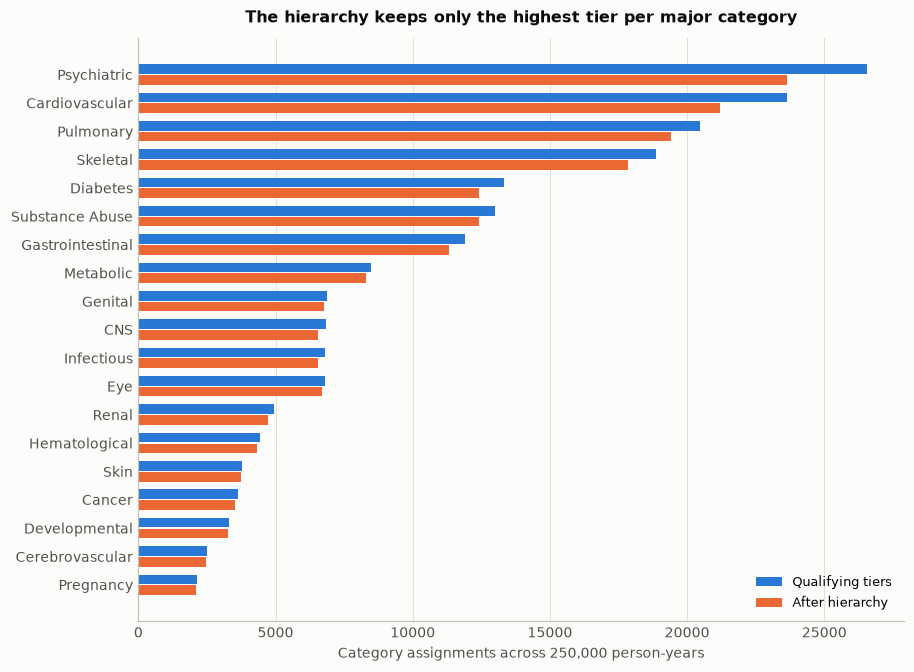

In [36]:
by_major_post = {m: flags[:, [list(codes).index(c) for c in g.cdps_code]].sum()
                 for m, g in cdps.groupby("major_category", sort=False)}
hier = (pd.DataFrame({"pre": by_major_pre, "post": by_major_post})
          .sort_values("pre"))

fig, ax = plt.subplots(figsize=(8.2, 6.0))
y = np.arange(len(hier))
ax.barh(y + .19, hier.pre, height=.34, color=T.BLUE, label="Qualifying tiers")
ax.barh(y - .19, hier.post, height=.34, color=T.ORANGE, label="After hierarchy")
ax.set_yticks(y, hier.index)
ax.set_xlabel("Category assignments across 250,000 person-years")
ax.set_title("The hierarchy keeps only the highest tier per major category")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "10_hierarchy_collapse.png")
plt.show()

### Does the draw reproduce the target prevalences?

With calibrated intercepts, tier-1 categories should land **on** the identity
line. Lower tiers land **below** it — the hierarchy strips them whenever a more
severe tier in the same major category also fires. That split is the check: it
confirms the calibration works and shows exactly how much the hierarchy removes.

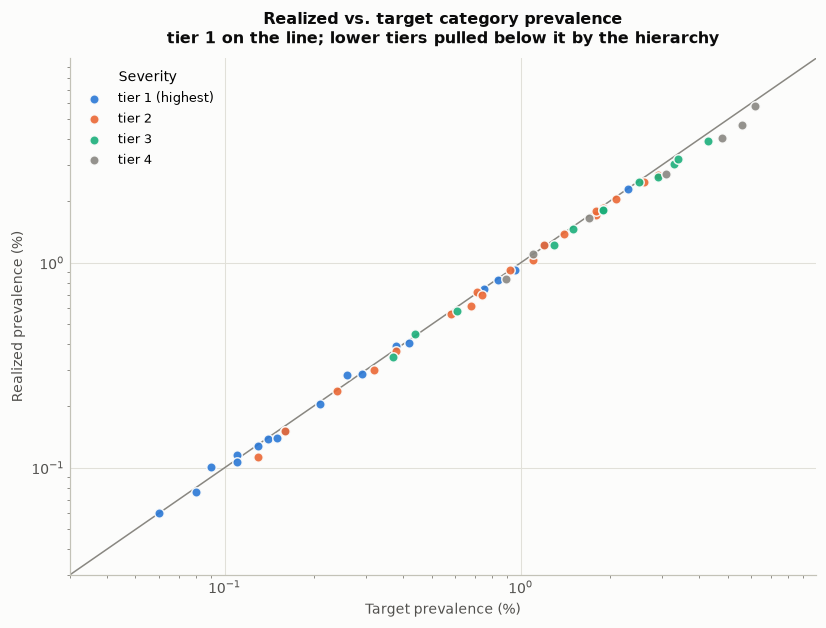

tier-1 calibration error: median 2.9%, max 11.6%
lower tiers retained after hierarchy: 95.1% of target (median)


In [37]:

# Pregnancy categories are only reachable by females 13-49, so their prevalence
# must be measured against that subpopulation, not the whole file.
denom = np.where(preg_mask, can_be_pregnant.sum(), N)
realized = flags.sum(0) / denom
pre_collapse = np.where(preg_mask,
                        p[can_be_pregnant].mean(0), p.mean(0))

prev_tbl = cdps[["major_category", "cdps_code", "tier", "prevalence"]].copy()
prev_tbl["pre_hierarchy"] = pre_collapse
prev_tbl["realized"] = realized

fig, ax = plt.subplots(figsize=(7.4, 5.6))
tier_colors = [T.BLUE, T.ORANGE, T.AQUA, T.INK_MUTED]
for tier, grp in prev_tbl.groupby("tier"):
    ax.scatter(grp.prevalence * 100, grp.realized * 100, s=38, alpha=.9,
               linewidths=1, edgecolors=T.SURFACE, c=tier_colors[min(tier - 1, 3)],
               label=f"tier {tier}" + (" (highest)" if tier == 1 else ""), zorder=3)
lim = [prev_tbl.prevalence.min() * 100 * .5, prev_tbl.prevalence.max() * 100 * 1.6]
ax.plot(lim, lim, color=T.INK_MUTED, lw=1, zorder=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Target prevalence (%)")
ax.set_ylabel("Realized prevalence (%)")
ax.set_title("Realized vs. target category prevalence\n"
             "tier 1 on the line; lower tiers pulled below it by the hierarchy")
ax.legend(title="Severity", loc="upper left")
fig.savefig(FIGS / "11_prevalence_check.png")
plt.show()

t1 = prev_tbl[prev_tbl.tier == 1]
err = (t1.realized / t1.prevalence - 1).abs()
print(f"tier-1 calibration error: median {err.median():.1%}, max {err.max():.1%}")
lower = prev_tbl[prev_tbl.tier > 1]
print(f"lower tiers retained after hierarchy: "
      f"{(lower.realized / lower.prevalence).median():.1%} of target (median)")

## 2.7 Cost model

Cost is generated **additively in dollars** — `base + age + Σ category weights` —
then given gamma noise, following the project spec. Every term is additive on
the dollar scale, including age, so the additive regression in Step 3 is
correctly specified and should recover the weights up to sampling noise and the
diagnoses that claims never captured.

This matters for Step 3's model comparison: because the truth is additive on the
dollar scale, a log-link fit is the *wrong* functional form, and its coefficients
do not translate into dollar weights without marginal effects.

In [38]:
base_v = np.array([BASE_COST[a] for a in aid])

age_add = AGE_SLOPE * np.maximum(age - 40, 0)
# Purely additive in dollars, per the spec: base + age + sum of category weights.
# Keeping age additive (rather than a multiplier on the whole cost) matters --
# a multiplicative loading cannot be represented by the additive regression in
# Step 3, and would show up there as 20-45% inflation on the rare severe
# categories that co-occur with high total cost.
cost_mean = (base_v + age_add + flags @ wcal) * (months / 12)
annual_cost = rng.gamma(COST_CV_SHAPE, cost_mean / COST_CV_SHAPE)

eligibility["expected_annual_cost"] = cost_mean
eligibility["true_annual_cost"] = annual_cost


pmpm = annual_cost.sum() / months.sum()
print(f"mean annual cost ${annual_cost.mean():,.0f}   median ${np.median(annual_cost):,.0f}")
print(f"aggregate PMPM   ${pmpm:,.0f}   (real Medi-Cal managed care is roughly $400-500)")

cost_tbl = (eligibility.groupby("aid_category")
    .apply(lambda g: pd.Series({
        "Person-years": len(g),
        "Share": len(g) / len(eligibility),
        "Mean categories": g.n_cdps_categories.mean(),
        "Mean annual cost": g.true_annual_cost.mean(),
        "PMPM": g.true_annual_cost.sum() / g.months_enrolled.sum(),
    }), include_groups=False)
    .reindex(["child", "adult", "disabled"]).reset_index()
    .rename(columns={"aid_category": "Aid category"}))
T.style_table(cost_tbl.style, caption="Cost by aid category",
              fmt={"Person-years": "{:,.0f}", "Share": "{:.1%}",
                   "Mean categories": "{:.2f}", "Mean annual cost": "${:,.0f}",
                   "PMPM": "${:,.0f}"})\
    .set_properties(subset=["Aid category"], **{"text-align": "left"})

mean annual cost $4,711   median $2,026
aggregate PMPM   $451   (real Medi-Cal managed care is roughly $400-500)


Aid category,Person-years,Share,Mean categories,Mean annual cost,PMPM
child,"134,995",54.0%,0.32,"$2,257",$216
adult,"94,535",37.8%,0.90,"$5,580",$534
disabled,"20,470",8.2%,2.40,"$16,878","$1,620"


## 2.8 Claims file

One row per encounter. Every captured condition contributes at least one claim
carrying a diagnosis code that maps back to its category — that is how Step 3
reconstructs the flags. `DX_CAPTURE` below 1.0 means a small share of conditions
never surface in claims, which is realistic and gives Step 3 something honest to
be imperfect about.

In [39]:
# One diagnosis-bearing claim per captured condition ...
rows_p, rows_c = np.nonzero(flags)
captured = rng.random(len(rows_p)) < DX_CAPTURE
rows_p, rows_c = rows_p[captured], rows_c[captured]

# ... plus routine encounters that carry no CDPS-relevant diagnosis.
n_filler = rng.poisson(1.2 + 0.9 * n_cats) + 1
fill_p = np.repeat(np.arange(N), n_filler)

claim_person = np.concatenate([rows_p, fill_p])
claim_cat = np.concatenate([rows_c, np.full(len(fill_p), -1)])
order = np.argsort(claim_person, kind="stable")
claim_person, claim_cat = claim_person[order], claim_cat[order]
n_claims = len(claim_person)

icd = np.empty(n_claims, object)
ndc = np.full(n_claims, "", object)
is_dx = claim_cat >= 0
for ci, ccode in enumerate(codes):
    m = claim_cat == ci
    if not m.any():
        continue
    icd[m] = rng.choice(ICD[ccode], m.sum())
    if ccode in NDC:
        has_rx = m & (rng.random(n_claims) < 0.55)
        ndc[has_rx] = rng.choice(NDC[ccode], has_rx.sum())
icd[~is_dx] = rng.choice(NON_CDPS, (~is_dx).sum())

# Split the person-year cost across that person's claims.
share = rng.exponential(1.0, n_claims)
share_tot = pd.Series(share).groupby(claim_person).transform("sum").to_numpy()
amount = annual_cost[claim_person] * share / share_tot

# Service dates fall inside the enrollment window.
sm, mo = start_month[claim_person], months[claim_person]
doy = np.clip((sm - 1) * 30.4 + rng.random(n_claims) * mo * 30.4, 0, 364).astype(int)
service_date = pd.to_datetime(f"{SIM_YEAR}-01-01") + pd.to_timedelta(doy, unit="D")

claims = pd.DataFrame({
    "person_id": claim_person + 1,
    "year": SIM_YEAR,
    "service_date": service_date,
    "procedure_code": np.where(
        is_dx, rng.choice(["99213","99214","99285","99223"], n_claims),
               rng.choice(["99213","99391","90471","99203"], n_claims)),
    "icd_code": icd,
    "ndc_code": ndc,
    "amount_paid": np.round(amount, 2),
})

assert abs(claims.amount_paid.sum() - annual_cost.sum()) < 1e4, "claims must sum to cost"
print(f"{len(claims):,} claim rows ({len(claims)/N:.1f} per person-year)")
print(f"  distinct ICD-10 codes: {claims.icd_code.nunique()}")
print(f"  claims carrying an NDC: {(claims.ndc_code != '').sum():,}")
print(f"  total paid: ${claims.amount_paid.sum()/1e6:,.0f}M")
claims.head()

879,160 claim rows (3.5 per person-year)
  distinct ICD-10 codes: 222
  claims carrying an NDC: 47,567
  total paid: $1,178M


,person_id,year,service_date,procedure_code,icd_code,ndc_code,amount_paid
0,1,2024,2024-04-06,99391,R519,,2127.14
1,2,2024,2024-06-10,99213,Z013,,141.54
2,2,2024,2024-06-14,99391,R519,,63.28
3,3,2024,2024-08-28,90471,R519,,1308.19
4,3,2024,2024-06-23,99213,R0789,,268.07


## 2.9 Diagnostics

### Figure 12 — the ground-truth SDI gradient

This is the relationship the project exists to interrogate. It is put in here
deliberately, so "discovering" it later is a validation that the pipeline works,
**not** an empirical finding about California.

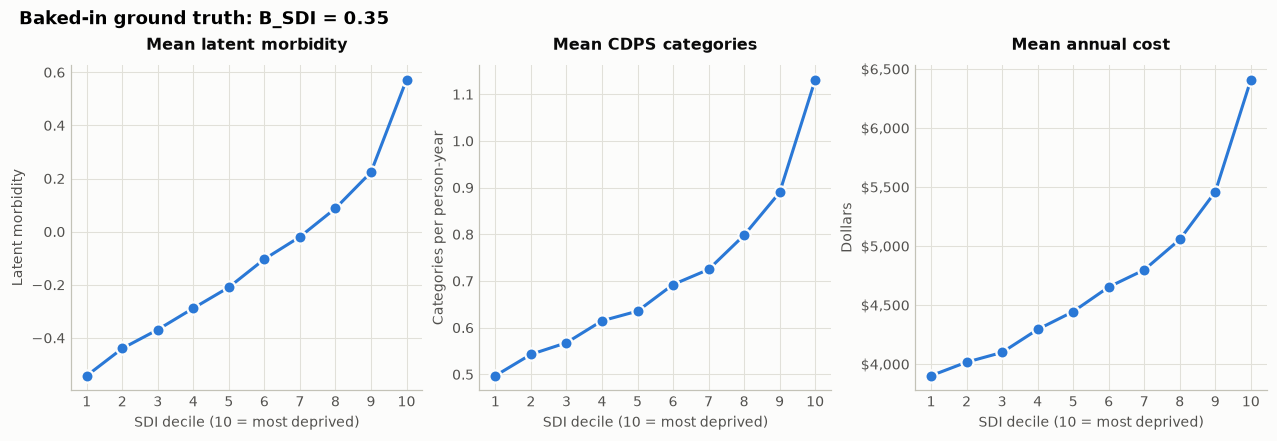

Most-deprived decile costs 1.64x the least-deprived ($3,901 -> $6,407)


In [40]:
eligibility["sdi_decile"] = pd.qcut(eligibility.sdi_score, 10,
                                    labels=range(1, 11)).astype(int)
grad = eligibility.groupby("sdi_decile").agg(
    morbidity=("latent_morbidity", "mean"),
    n_cats=("n_cdps_categories", "mean"),
    cost=("true_annual_cost", "mean"))

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9))
panels = [("morbidity", "Mean latent morbidity", "Latent morbidity"),
          ("n_cats", "Mean CDPS categories", "Categories per person-year"),
          ("cost", "Mean annual cost", "Dollars")]
for ax, (col, title, ylab) in zip(axes, panels):
    ax.plot(grad.index, grad[col], marker="o", color=T.BLUE,
            markeredgecolor=T.SURFACE, markeredgewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel("SDI decile (10 = most deprived)")
    ax.set_ylabel(ylab)
    ax.set_xticks(range(1, 11))
axes[2].yaxis.set_major_formatter(lambda v, p: f"${v:,.0f}")
fig.suptitle(f"Baked-in ground truth: B_SDI = {B_SDI}", fontsize=11.5,
             fontweight="semibold", x=.01, ha="left")
fig.savefig(FIGS / "12_ground_truth_sdi_gradient.png")
plt.show()

lo, hi = grad.cost.iloc[0], grad.cost.iloc[-1]
print(f"Most-deprived decile costs {hi/lo:.2f}x the least-deprived "
      f"(${lo:,.0f} -> ${hi:,.0f})")

### Figure 13 — cost distribution and enrollment structure

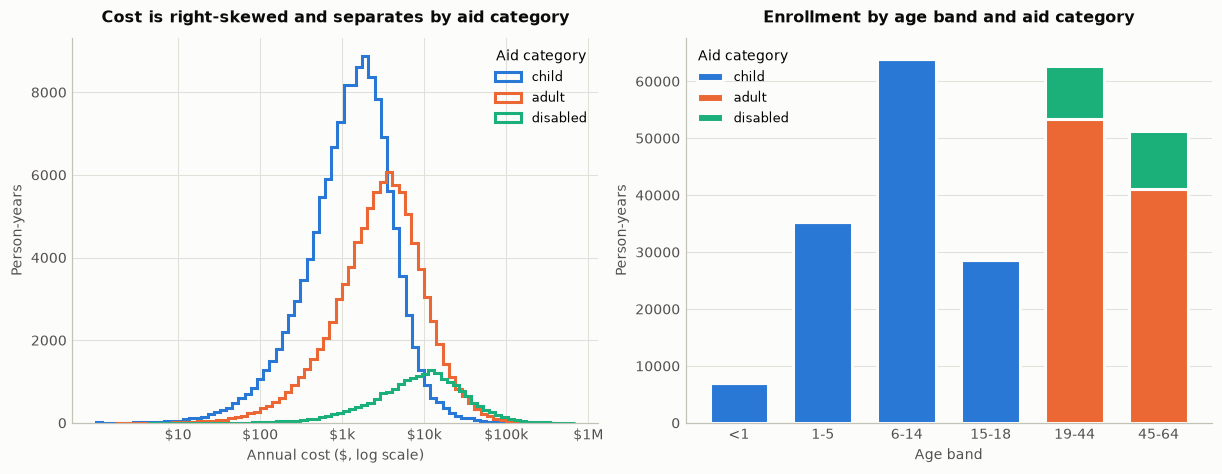

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

for name, colr in zip(["child", "adult", "disabled"], [T.BLUE, T.ORANGE, T.AQUA]):
    v = eligibility.loc[eligibility.aid_category == name, "true_annual_cost"]
    ax1.hist(np.log10(np.clip(v, 1, None)), bins=70, histtype="step",
             lw=2, color=colr, label=name)
ax1.set_xlabel("Annual cost ($, log scale)")
ax1.set_ylabel("Person-years")
ax1.set_title("Cost is right-skewed and separates by aid category")
ax1.set_xticks([1, 2, 3, 4, 5, 6], ["$10", "$100", "$1k", "$10k", "$100k", "$1M"])
ax1.legend(title="Aid category")

band = (eligibility.groupby(["age_band", "aid_category"], observed=True)
        .size().unstack(fill_value=0).reindex(AGE_LABELS))
bottom = np.zeros(len(band))
for name, colr in zip(["child", "adult", "disabled"], [T.BLUE, T.ORANGE, T.AQUA]):
    if name in band:
        ax2.bar(band.index, band[name], bottom=bottom, color=colr,
                label=name, width=.7, linewidth=2, edgecolor=T.SURFACE)
        bottom += band[name].to_numpy()
ax2.set_xlabel("Age band")
ax2.set_ylabel("Person-years")
ax2.set_title("Enrollment by age band and aid category")
ax2.legend(title="Aid category")
ax2.grid(axis="x", visible=False)
fig.savefig(FIGS / "13_cost_and_enrollment.png")
plt.show()

### Concentration check

Medicaid spending is famously top-heavy — a few percent of enrollees drive a
large share of cost. If the simulation did not reproduce that, the risk-adjustment
exercise downstream would be too easy.

In [42]:
srt = np.sort(annual_cost)[::-1]
cum = np.cumsum(srt) / srt.sum()
conc = pd.DataFrame({
    "Top share of enrollees": ["1%", "5%", "10%", "25%", "50%"],
    "Share of total cost": [cum[int(len(srt) * q) - 1] for q in (.01, .05, .10, .25, .50)],
})
T.style_table(conc.style, caption="Cost concentration",
              fmt={"Share of total cost": "{:.1%}"})\
    .set_properties(subset=["Top share of enrollees"], **{"text-align": "left"})

Top share of enrollees,Share of total cost
1%,17.0%
5%,39.0%
10%,52.8%
25%,74.1%
50%,90.5%


## 2.10 Export

In [43]:
gt = cdps[["major_category", "cdps_code", "tier", "label", "prevalence",
           "morbidity_sens", "is_rx", "true_weight", "true_weight_cal"]].copy()
gt["realized_prevalence"] = realized
gt.to_csv(OUT / "sim_ground_truth_weights.csv", index=False)

cdps.to_csv(OUT / "cdps_categories.csv", index=False)
crosswalk.to_csv(OUT / "icd_cdps_crosswalk.csv", index=False)
eligibility.to_csv(INTERIM / "eligibility.csv", index=False)
# Claims go to parquet: 1M+ rows with a date column is unpleasant as CSV, and
# Step 3 only ever reads it back into pandas.
claims.to_parquet(INTERIM / "claims.parquet", index=False)

# True category assignments, long format. Step 3 uses this ONLY to measure how
# well flags rebuilt from claims match the truth -- never as a model input.
_tp, _tc = np.nonzero(flags)
pd.DataFrame({"person_id": _tp + 1, "cdps_code": codes[_tc]}).to_parquet(
    INTERIM / "true_cdps_flags.parquet", index=False)

for f in ["sim_ground_truth_weights.csv", "cdps_categories.csv", "icd_cdps_crosswalk.csv"]:
    print(f"  {(OUT/f).stat().st_size/1e3:8,.0f} KB  data/out/{f}")
for f in ["eligibility.csv", "claims.parquet", "true_cdps_flags.parquet"]:
    print(f"  {(INTERIM/f).stat().st_size/1e6:8,.1f} MB  data/interim/{f}")

         4 KB  data/out/sim_ground_truth_weights.csv
         4 KB  data/out/cdps_categories.csv
         2 KB  data/out/icd_cdps_crosswalk.csv
      32.6 MB  data/interim/eligibility.csv
       9.0 MB  data/interim/claims.parquet
       0.9 MB  data/interim/true_cdps_flags.parquet


---

# Step 3 — CDPS flags from claims, and weight regression

Three things happen here:

1. **Rebuild category flags from `claims.parquet` alone.** Not from the `flags`
   matrix still sitting in memory — that would defeat the exercise. The only
   inputs are ICD codes on claim lines and the crosswalk.
2. **Fit annual cost on those flags** plus demographics, under four
   specifications.
3. **Validate against `sim_ground_truth_weights.csv`** — did the regression
   recover what Step 2 put in?

Because Step 2 generates cost additively in dollars, the additive models are
correctly specified and the log-link models are not. That contrast is the point:
the right link is an empirical question about how cost is actually generated, not
a default.

## 3.1 Reconstructing flags from claims

A person-year gets a category if **any** claim line carries a qualifying
diagnosis. The hierarchy then collapses each major category to its most severe
observed tier — applied to *observed* codes, which is what a real risk-adjustment
run does.

In [44]:
import statsmodels.api as sm

claims_in = pd.read_parquet(INTERIM / "claims.parquet")
xwalk_in  = pd.read_csv(OUT / "icd_cdps_crosswalk.csv")
cdps_in   = pd.read_csv(OUT / "cdps_categories.csv")
truth_in  = pd.read_csv(OUT / "sim_ground_truth_weights.csv")

CODES = cdps_in.cdps_code.tolist()
MAJOR = dict(zip(cdps_in.cdps_code, cdps_in.major_category))
TIER  = dict(zip(cdps_in.cdps_code, cdps_in.tier))

dx = claims_in[["person_id", "icd_code"]].merge(xwalk_in, on="icd_code", how="inner")
print(f"{len(dx):,} of {len(claims_in):,} claim lines carry a CDPS-mappable diagnosis")

obs = dx[["person_id", "cdps_code"]].drop_duplicates()
obs["major"] = obs.cdps_code.map(MAJOR)
obs["tier"]  = obs.cdps_code.map(TIER)
before = len(obs)
obs = (obs.sort_values(["person_id", "major", "tier"])
          .drop_duplicates(["person_id", "major"], keep="first"))
print(f"category assignments: {before:,} observed -> {len(obs):,} after hierarchy")

obs_flags = (pd.crosstab(obs.person_id, obs.cdps_code) > 0).astype(np.int8)
obs_flags = obs_flags.reindex(columns=CODES, fill_value=0)
obs_flags = obs_flags.reindex(eligibility.person_id, fill_value=0)
obs_flags.index = eligibility.index
eligibility["n_observed_categories"] = obs_flags.sum(1).to_numpy()

print(f"mean categories per person-year: observed {obs_flags.sum(1).mean():.3f}, "
      f"true {eligibility.n_cdps_categories.mean():.3f}")

168,542 of 879,160 claim lines carry a CDPS-mappable diagnosis
category assignments: 168,542 observed -> 168,542 after hierarchy
mean categories per person-year: observed 0.674, true 0.709


/tmp/ipykernel_137957/388927173.py:27: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  eligibility["n_observed_categories"] = obs_flags.sum(1).to_numpy()
/tmp/ipykernel_137957/388927173.py:29: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print(f"mean categories per person-year: observed {obs_flags.sum(1).mean():.3f}, "


### How much did the claims miss?

`DX_CAPTURE = 0.95` in Step 2, so about one condition in twenty never reaches a
claim. This compares the rebuilt flags against the true assignments — used
**only** as a diagnostic, never as a model input.

In [45]:
true_long = pd.read_parquet(INTERIM / "true_cdps_flags.parquet")
true_flags = (pd.crosstab(true_long.person_id, true_long.cdps_code) > 0).astype(np.int8)
true_flags = true_flags.reindex(columns=CODES, fill_value=0)
true_flags = true_flags.reindex(eligibility.person_id, fill_value=0)
true_flags.index = eligibility.index

TT = true_flags.to_numpy().astype(bool)
OO = obs_flags.to_numpy().astype(bool)
tp, fn, fp = (TT & OO).sum(), (TT & ~OO).sum(), (~TT & OO).sum()

recovery = pd.DataFrame([
    ("True assignments", TT.sum(), ""),
    ("Recovered from claims", tp, f"{tp/TT.sum():.1%} sensitivity"),
    ("Missed (never in a claim)", fn, f"{fn/TT.sum():.1%}"),
    ("False positives", fp, "should be 0 - the crosswalk is 1-to-1"),
], columns=["Measure", "Count", "Note"])
T.style_table(recovery.style, caption="Flag reconstruction vs. ground truth",
              fmt={"Count": "{:,.0f}"})\
    .set_properties(subset=["Measure", "Note"], **{"text-align": "left"})

Measure,Count,Note
True assignments,"177,290",
Recovered from claims,"168,542",95.1% sensitivity
Missed (never in a claim),"8,748",4.9%
False positives,0,should be 0 - the crosswalk is 1-to-1


## 3.2 Modelling sample

UCSD's guidance excludes members with fewer than six months of eligibility from
weight development, since they have had less time to accumulate diagnoses.
Newborns are exempt.

In [46]:
eligibility["in_model"] = (eligibility.months_enrolled >= 6) | (eligibility.age < 1)
mdl = eligibility[eligibility.in_model].copy()
F = obs_flags.loc[mdl.index]

# Annualize: Step 2 scales cost by months/12, so undo that to get a full-year rate.
mdl["annual_cost"] = mdl.true_annual_cost / (mdl.months_enrolled / 12)

demo = pd.get_dummies(mdl[["age_band", "sex", "aid_category"]],
                      drop_first=True).astype(float)
X = sm.add_constant(pd.concat([F.astype(float), demo], axis=1))
y = mdl.annual_cost.to_numpy()

print(f"modelling sample: {len(mdl):,} of {len(eligibility):,} person-years "
      f"({eligibility.in_model.mean():.1%})")
print(f"design matrix: {X.shape[0]:,} x {X.shape[1]} "
      f"({len(CODES)} CDPS flags + {demo.shape[1]} demographic terms)")

modelling sample: 221,198 of 250,000 person-years (88.5%)
design matrix: 221,198 x 66 (57 CDPS flags + 8 demographic terms)


## 3.3 Four specifications

| Model | Link | Comparable to dollar weights? |
|---|---|---|
| OLS on dollars | identity | directly — coefficients *are* dollars |
| Gamma GLM | identity | directly; efficient under skewed cost |
| OLS on log cost | log | only via marginal effects |
| Gamma GLM | log | only via marginal effects |

The gamma family matches the right-skewed cost distribution; the *link* is what
decides whether coefficients mean dollars.

### Model cache

The two gamma GLMs take about 90 seconds each, which dominates a
restart-and-run-all. Fits are cached to `data/interim/model_cache/`, keyed on a
content hash of the **exact design matrix and response** the model sees — so
re-simulating Step 2, changing the inclusion screen, or adding a covariate all
invalidate the cache automatically. There is no stale-result trap to remember.

Set `USE_MODEL_CACHE = False` to force refitting, or bump `CACHE_VERSION`.

In [47]:
import hashlib, pickle, re, time

MODEL_CACHE = INTERIM / "model_cache"
MODEL_CACHE.mkdir(exist_ok=True)
USE_MODEL_CACHE = True
CACHE_VERSION = "v1"      # bump to invalidate every cached fit

def _design_key(spec, X, y):
    """Content hash of the exact design the model will be fit on."""
    h = hashlib.blake2b(digest_size=16)
    for part in (CACHE_VERSION, spec, "|".join(map(str, X.columns))):
        h.update(part.encode())
    h.update(np.ascontiguousarray(X.to_numpy(dtype=float)).tobytes())
    h.update(np.ascontiguousarray(np.asarray(y, dtype=float)).tobytes())
    return h.hexdigest()

def _warm(res):
    """Force lazily-computed attributes into cache before the data is dropped.

    statsmodels derives bse, scale and friends from the design matrix on first
    access. remove_data() discards that matrix, so anything not already computed
    would raise on the far side of the pickle -- silently turning a cached run
    into a broken one.
    """
    _ = res.params, res.bse, res.fittedvalues
    for attr in ("rsquared", "scale", "converged", "llf"):
        try:
            getattr(res, attr)
        except Exception:
            pass
    return res

def cached_fit(spec, X, y, fit_fn):
    slug = re.sub(r"[^A-Za-z0-9]+", "_", spec).strip("_")
    path = MODEL_CACHE / f"{slug}__{_design_key(spec, X, y)}.pkl"
    if USE_MODEL_CACHE and path.exists():
        with open(path, "rb") as f:
            res = pickle.load(f)
        print(f"  {spec:<22} loaded from cache")
        return res
    t0 = time.time()
    res = fit_fn()
    took = time.time() - t0
    _warm(res)
    res.remove_data()       # drops the ~120 MB design matrix
    # remove_data() leaves PandasData._cache holding row_labels -- one int64 per
    # observation, 1.8 MB here. Drop just that; xnames must stay or params and
    # bse lose their column-name index and label lookups like params[CODES] break.
    try:
        res._results.model.data._cache.pop("row_labels", None)
    except Exception:
        pass
    with open(path, "wb") as f:
        pickle.dump(res, f)
    for old in MODEL_CACHE.glob(f"{slug}__*.pkl"):   # drop superseded fits
        if old != path:
            old.unlink()
    print(f"  {spec:<22} fitted in {took:5.1f}s, cached")
    return res

In [48]:
y_log = np.log(np.clip(y, 1, None))

fits = {}
fits["OLS, dollars"] = cached_fit(
    "OLS, dollars", X, y, lambda: sm.OLS(y, X).fit())
fits["OLS, log cost"] = cached_fit(
    "OLS, log cost", X, y_log, lambda: sm.OLS(y_log, X).fit())
fits["Gamma, log link"] = cached_fit(
    "Gamma, log link", X, y,
    lambda: sm.GLM(y, X, family=sm.families.Gamma(sm.families.links.Log())).fit())
fits["Gamma, identity link"] = cached_fit(
    "Gamma, identity link", X, y,
    lambda: sm.GLM(y, X, family=sm.families.Gamma(sm.families.links.Identity())).fit(
        start_params=fits["OLS, dollars"].params.to_numpy(), maxiter=200))

for k, m in fits.items():
    print(f"  {k:<22} {'converged' if getattr(m, 'converged', True) else 'DID NOT CONVERGE'}")

  OLS, dollars           loaded from cache
  OLS, log cost          loaded from cache
  Gamma, log link        loaded from cache
  Gamma, identity link   loaded from cache
  OLS, dollars           converged
  OLS, log cost          converged
  Gamma, log link        converged
  Gamma, identity link   converged


In [49]:
def marginal_dollars(model, X, codes, log_scale):
    """Incremental dollars per category among people who have it.

    For a log-link model the increment is multiplicative, so it differs person to
    person; we report the median, which is stable. The mean is not: exp() of the
    linear predictor explodes for the most multimorbid people, which is itself a
    reason the log link is awkward when the estimand is a dollar weight.
    """
    
    Xa = X.to_numpy(float)
    b = model.params.to_numpy()
    med, mean = [], []
    for c in codes:
        j = X.columns.get_loc(c)
        has = Xa[:, j] == 1
        if has.sum() < 30:
            med.append(np.nan); mean.append(np.nan); continue
        sub = Xa[has]
        sub0 = sub.copy(); sub0[:, j] = 0
        if log_scale:
            d = np.exp(sub @ b) - np.exp(sub0 @ b)
        else:
            d = (sub - sub0) @ b
        med.append(float(np.median(d))); mean.append(float(np.mean(d)))
    return np.array(med), np.array(mean)

# EXPLAIN the following lines a little more
recovered, extras = {}, {}
recovered["OLS, dollars"] = fits["OLS, dollars"].params[CODES].to_numpy()
recovered["Gamma, identity link"] = fits["Gamma, identity link"].params[CODES].to_numpy()
for name, log_scale in [("OLS, log cost", True), ("Gamma, log link", True)]:
    med, mean = marginal_dollars(fits[name], X, CODES, log_scale)
    recovered[name + " (median ME)"] = med
    extras[name] = mean

truth_w = truth_in.set_index("cdps_code").true_weight_cal.reindex(CODES).to_numpy()
n_obs = F.to_numpy().sum(0)

rows = []
for name, rec in recovered.items():
    ok = np.isfinite(rec) & np.isfinite(truth_w)
    rows.append({
        "Model": name,
        "Pearson r": np.corrcoef(rec[ok], truth_w[ok])[0, 1],
        "RMSE ($)": np.sqrt(np.mean((rec[ok] - truth_w[ok]) ** 2)),
        "Median abs % error": np.median(np.abs(rec[ok] / truth_w[ok] - 1)) * 100,
        "Mean bias ($)": np.mean(rec[ok] - truth_w[ok]),
    })
comp = pd.DataFrame(rows)
T.style_table(comp.style, caption="Weight recovery vs. ground truth",
              fmt={"Pearson r": "{:.4f}", "RMSE ($)": "{:,.0f}",
                   "Median abs % error": "{:.1f}%", "Mean bias ($)": "{:+,.0f}"})\
    .set_properties(subset=["Model"], **{"text-align": "left"})

Model,Pearson r,RMSE ($),Median abs % error,Mean bias ($)
"OLS, dollars",0.9928,"2,081",8.4%,+587
"Gamma, identity link",0.9942,"1,569",4.3%,+286
"OLS, log cost (median ME)",0.9834,"8,667",41.5%,"-5,118"
"Gamma, log link (median ME)",0.9485,"21,003",22.9%,"+8,117"


### Figure 14 — recovered vs. ground-truth weights

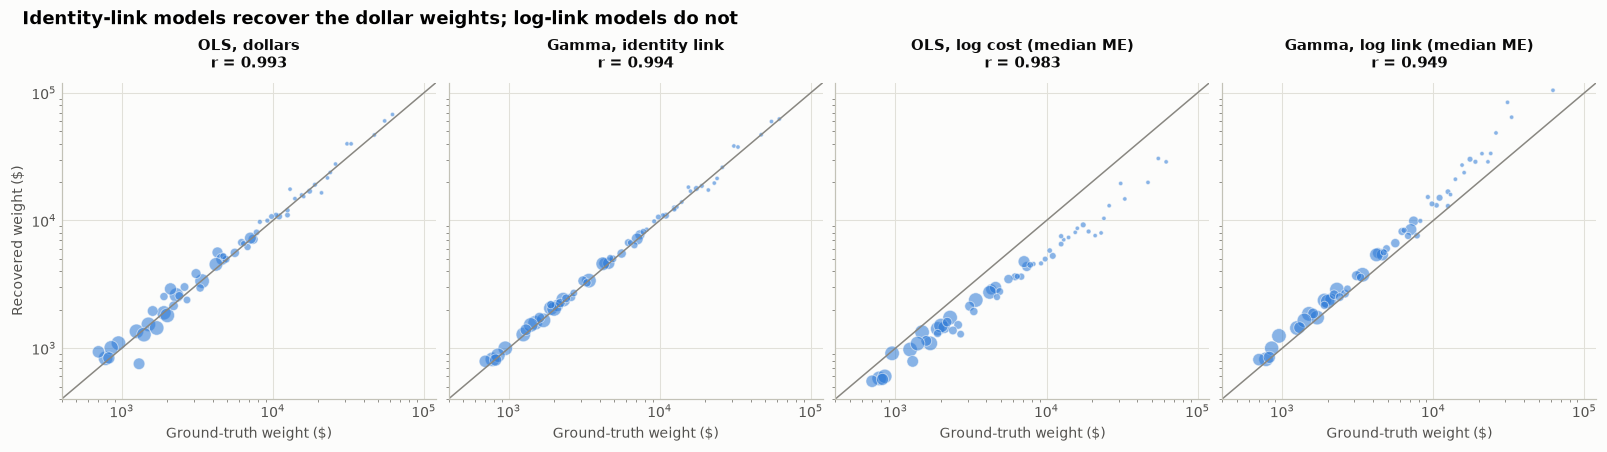

In [50]:
fig, axes = plt.subplots(1, 4, figsize=(14.5, 4.0), sharex=True, sharey=True)
lim = [400, 120000]
for ax, (name, rec) in zip(axes, recovered.items()):
    ok = np.isfinite(rec) & (rec > 0)
    ax.scatter(truth_w[ok], rec[ok], s=np.clip(n_obs[ok] / 60, 8, 90),
               c=T.BLUE, alpha=.55, linewidths=.6, edgecolors=T.SURFACE)
    bad = np.isfinite(rec) & (rec <= 0)
    if bad.any():
        ax.scatter(truth_w[bad], np.full(bad.sum(), lim[0] * 1.1), s=22,
                   c=T.ORANGE, marker="v", label="negative estimate")
        ax.legend(loc="lower right")
    ax.plot(lim, lim, color=T.INK_MUTED, lw=1)
    r = np.corrcoef(rec[np.isfinite(rec)], truth_w[np.isfinite(rec)])[0, 1]
    ax.set_title(f"{name}\nr = {r:.3f}", fontsize=9.5)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Ground-truth weight ($)")
axes[0].set_ylabel("Recovered weight ($)")
fig.suptitle("Identity-link models recover the dollar weights; log-link models do not",
             fontsize=11.5, fontweight="semibold", x=.01, ha="left")
fig.savefig(FIGS / "14_weight_recovery.png")
plt.show()

### Is the remaining error bias or sampling noise?

The honest test is whether each deviation is large relative to *its own* standard
error. If the model is unbiased, `z = (estimate − truth) / SE` should look
standard normal — roughly 95% of categories inside ±1.96 and a mean near zero.

In [51]:
best = fits["Gamma, identity link"]
est = best.params[CODES].to_numpy()
se = best.bse[CODES].to_numpy()
z = (est - truth_w) / se

zt = pd.DataFrame([
    ("Categories within +/-1.96 SE", f"{(np.abs(z) < 1.96).sum()} of {len(z)}",
     f"{(np.abs(z)<1.96).mean():.0%} (expect ~95%)"),
    ("Mean z", f"{z.mean():+.2f}", "systematic bias would show here"),
    ("Median absolute % error", f"{np.median(np.abs(est/truth_w-1))*100:.1f}%", ""),
], columns=["Diagnostic", "Value", "Interpretation"])
T.style_table(zt.style, caption="Gamma identity-link: bias vs. noise")\
    .set_properties(**{"text-align": "left"})

Diagnostic,Value,Interpretation
Categories within +/-1.96 SE,53 of 57,93% (expect ~95%)
Mean z,+0.52,systematic bias would show here
Median absolute % error,4.3%,


### Figure 15 — precision scales with category frequency

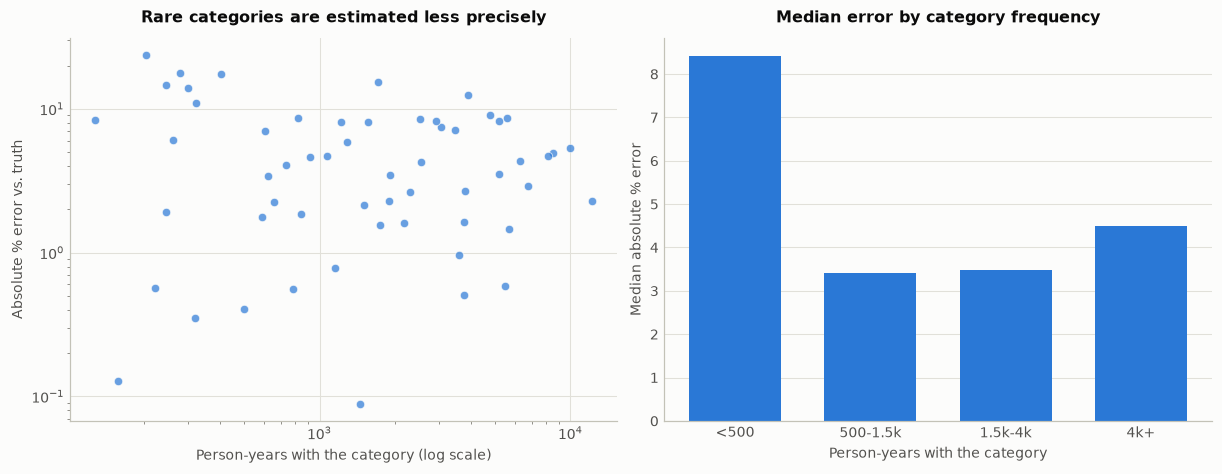

Median |% error| by frequency band:
<500        8.4
500-1.5k    3.4
1.5k-4k     3.5
4k+         4.5


In [52]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

pct_err = np.abs(est / truth_w - 1) * 100
ax1.scatter(n_obs, pct_err, s=30, c=T.BLUE, alpha=.7,
            linewidths=.6, edgecolors=T.SURFACE)
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel("Person-years with the category (log scale)")
ax1.set_ylabel("Absolute % error vs. truth")
ax1.set_title("Rare categories are estimated less precisely")

bins = [0, 500, 1500, 4000, 10**9]
names = ["<500", "500-1.5k", "1.5k-4k", "4k+"]
grp = pd.cut(n_obs, bins, labels=names)
medi = pd.Series(pct_err).groupby(grp, observed=True).median().reindex(names)
ax2.bar(names, medi.values, color=T.BLUE, width=.68)
ax2.set_xlabel("Person-years with the category")
ax2.set_ylabel("Median absolute % error")
ax2.set_title("Median error by category frequency")
ax2.grid(axis="x", visible=False)
fig.savefig(FIGS / "15_precision_vs_frequency.png")
plt.show()

print("Median |% error| by frequency band:")
print(medi.round(1).to_string())

## 3.4 Model fit and the link-function question

R² on dollars is the relevant yardstick — a log-scale R² is not comparable, since
it is explaining a different quantity. Risk-adjustment models genuinely land
around R² ≈ 0.15–0.25 on real concurrent Medicaid data; this simulation is
tidier than reality, so a higher figure here is expected rather than impressive.

In [53]:
def r2_dollars(model, log_scale):
    pred = np.asarray(model.predict(X))
    if log_scale:
        pred = np.exp(pred)
    ss_res = np.sum((y - pred) ** 2)
    return 1 - ss_res / np.sum((y - y.mean()) ** 2), np.mean(pred) - y.mean()

fit_rows = []
for name, m in fits.items():
    log_scale = name == "OLS, log cost"   # this one predicts log dollars
    r2, bias = r2_dollars(m, log_scale)
    fit_rows.append({"Model": name, "R2 on dollars": r2,
                     "Mean prediction error ($)": bias})
T.style_table(pd.DataFrame(fit_rows).style,
              caption="Predictive fit on the dollar scale",
              fmt={"R2 on dollars": "{:.4f}", "Mean prediction error ($)": "{:+,.0f}"})\
    .set_properties(subset=["Model"], **{"text-align": "left"})

Model,R2 on dollars,Mean prediction error ($)
"OLS, dollars",0.5076,-0
"OLS, log cost",-219.8040,+173
"Gamma, log link",-2927083.6644,"+88,494"
"Gamma, identity link",0.5064,-12


### Figure 16 — residual behaviour

The classic reason not to use OLS on raw dollars is heteroskedasticity: residual
spread grows with fitted value. It is visible here, and it is why the gamma
family — which builds that variance structure in — recovers the weights more
precisely even though both identity-link models are unbiased.

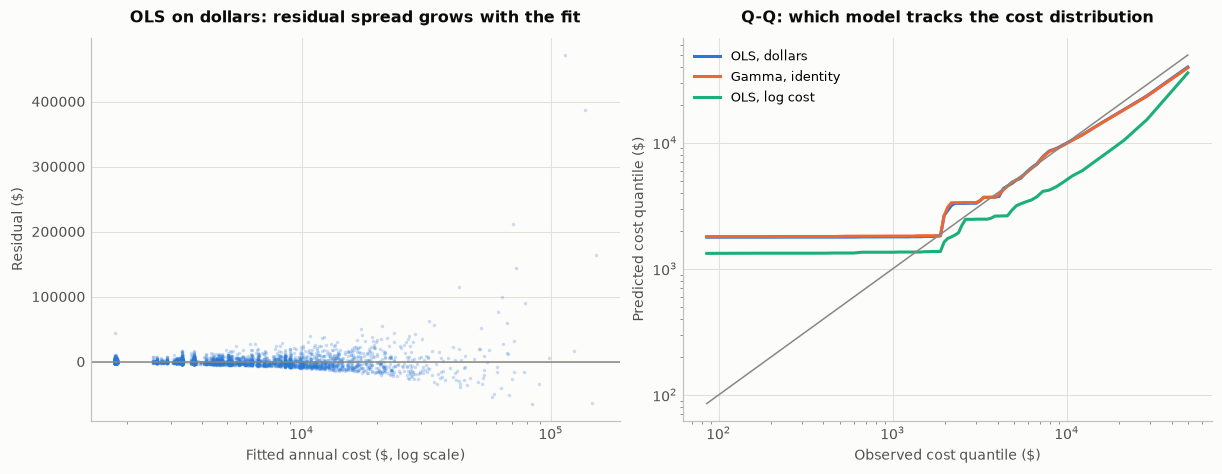

In [54]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

pred_ols = np.asarray(fits["OLS, dollars"].predict(X))
resid = y - pred_ols
idx = np.random.default_rng(7).choice(len(y), 6000, replace=False)
ax1.scatter(pred_ols[idx], resid[idx], s=5, c=T.BLUE, alpha=.25, linewidths=0)
ax1.axhline(0, color=T.INK_MUTED, lw=1)
ax1.set_xscale("log")
ax1.set_xlabel("Fitted annual cost ($, log scale)")
ax1.set_ylabel("Residual ($)")
ax1.set_title("OLS on dollars: residual spread grows with the fit")

qs = np.linspace(.01, .99, 60)
ax2.plot(np.quantile(y, qs), np.quantile(pred_ols, qs), color=T.BLUE,
         label="OLS, dollars")
ax2.plot(np.quantile(y, qs), np.quantile(np.asarray(fits["Gamma, identity link"].predict(X)), qs),
         color=T.ORANGE, label="Gamma, identity")
ax2.plot(np.quantile(y, qs), np.quantile(np.exp(np.asarray(fits["OLS, log cost"].predict(X))), qs),
         color=T.AQUA, label="OLS, log cost")
lo, hi = np.quantile(y, .01), np.quantile(y, .99)
ax2.plot([lo, hi], [lo, hi], color=T.INK_MUTED, lw=1)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("Observed cost quantile ($)")
ax2.set_ylabel("Predicted cost quantile ($)")
ax2.set_title("Q-Q: which model tracks the cost distribution")
ax2.legend()
fig.savefig(FIGS / "16_residual_diagnostics.png")
plt.show()

## 3.5 Export

`cdps_category_weights.csv` is the Step 3 deliverable and the input to Step 4's
risk scores. The gamma identity-link fit is the one carried forward: it is
correctly specified for how Step 2 generates cost, and it is the most precise of
the unbiased options.

In [55]:
weights_out = pd.DataFrame({
    "cdps_code": CODES,
    "major_category": [MAJOR[c] for c in CODES],
    "tier": [TIER[c] for c in CODES],
    "n_person_years": n_obs,
    "observed_prevalence": n_obs / len(mdl),
    "weight_ols_dollars": recovered["OLS, dollars"],
    "weight_gamma_identity": recovered["Gamma, identity link"],
    "se_gamma_identity": se,
    "true_weight": truth_w,
    "pct_error": (recovered["Gamma, identity link"] / truth_w - 1) * 100,
})
weights_out["weight_final"] = weights_out.weight_gamma_identity
weights_out.to_csv(OUT / "cdps_category_weights.csv", index=False)

demo_out = (fits["Gamma, identity link"].params.drop(CODES)
            .rename("coefficient").reset_index()
            .rename(columns={"index": "term"}))
demo_out.to_csv(OUT / "demographic_coefficients.csv", index=False)

print(f"wrote data/out/cdps_category_weights.csv ({len(weights_out)} categories)")
print(f"wrote data/out/demographic_coefficients.csv ({len(demo_out)} terms)")

show = weights_out.sort_values("true_weight", ascending=False).head(12)
T.style_table(show[["cdps_code", "n_person_years", "true_weight",
                    "weight_gamma_identity", "se_gamma_identity", "pct_error"]].style,
              caption="Recovered weights, highest-cost categories",
              fmt={"n_person_years": "{:,.0f}", "true_weight": "${:,.0f}",
                   "weight_gamma_identity": "${:,.0f}",
                   "se_gamma_identity": "${:,.0f}", "pct_error": "{:+.1f}%"})\
    .set_properties(subset=["cdps_code"], **{"text-align": "left"})

wrote data/out/cdps_category_weights.csv (57 categories)
wrote data/out/demographic_coefficients.csv (9 terms)


cdps_code,n_person_years,true_weight,weight_gamma_identity,se_gamma_identity,pct_error
RENEH,221,"$62,000","$62,350","$4,954",+0.6%
HEMEH,127,"$55,000","$59,630","$6,483",+8.4%
CANVH,157,"$47,000","$46,940","$5,009",-0.1%
INFVH,298,"$33,000","$37,629","$2,815",+14.0%
PULVH,204,"$31,000","$38,338","$3,644",+23.7%
CARVH,320,"$26,000","$26,091","$2,162",+0.4%
CANH,322,"$24,000","$21,352","$1,710",-11.0%
HEMVH,244,"$23,000","$19,634","$1,903",-14.6%
CNSH,405,"$21,000","$17,325","$1,392",-17.5%
GIH,588,"$19,000","$18,665","$1,184",-1.8%


---

# Step 4 — Risk scores and capitation rates

Turns the recovered weights into money:

1. **Risk score** per person-year, normalized to a population mean of 1.0 —
   the CDPS convention.
2. **Rate cells** — region × aid category × age band, with credibility fallback
   for thin cells.
3. **Capitation** = base rate × risk score × plan factor.
4. **Actuarial validation** — predictive ratios, which is how a rate-setting
   shop checks whether risk adjustment actually works.

### Avoiding double-counting

This is the one genuinely subtle design point. If base rates vary by rate cell
*and* the risk score is normalized statewide, demographics get paid for twice:
the disabled cell already carries a high base rate, and disabled members also
carry high statewide risk scores.

So two normalizations are computed and they do different jobs:

| Score | Normalized over | Used for |
|---|---|---|
| `risk_score` | the whole population | reporting; the CDPS convention the spec asks for |
| `risk_score_cell` | within each rate cell | **payment** — mean 1.0 in every cell, so morbidity is priced *within* a cell while the cell's base rate prices demographics and geography |

## 4.1 Risk scores

Predicted annual cost comes from the Step 3 gamma identity-link model, applied to
the whole population — including the short-enrollment members excluded from
weight *development*. Predicting from the fitted model object (rather than
re-multiplying coefficients by hand) guarantees the design matrix matches the one
the model was fit on.

In [56]:
# Same design as Step 3, over every person-year rather than the model sample.
demo_all = pd.get_dummies(eligibility[["age_band", "sex", "aid_category"]],
                          drop_first=True).astype(float)
X_all = sm.add_constant(pd.concat([obs_flags.astype(float), demo_all], axis=1))
X_all = X_all.reindex(columns=X.columns, fill_value=0.0)
assert list(X_all.columns) == list(X.columns), "design matrix mismatch"

risk_raw = np.asarray(fits["Gamma, identity link"].predict(X_all))
print(f"predicted annual cost: mean ${risk_raw.mean():,.0f}  "
      f"min ${risk_raw.min():,.0f}  max ${risk_raw.max():,.0f}  "
      f"negative: {(risk_raw < 0).sum()}")

# A risk score must be positive; floor at a nominal value rather than let a
# small negative prediction turn into negative revenue.
RISK_FLOOR = 50.0
eligibility["risk_raw"] = np.clip(risk_raw, RISK_FLOOR, None)
eligibility["risk_score"] = eligibility.risk_raw / eligibility.risk_raw.mean()

print(f"risk_score: mean {eligibility.risk_score.mean():.4f} (normalized to 1.0), "
      f"median {eligibility.risk_score.median():.2f}, "
      f"p99 {eligibility.risk_score.quantile(.99):.1f}")

predicted annual cost: mean $5,413  min $1,801  max $289,858  negative: 0
risk_score: mean 1.0000 (normalized to 1.0), median 0.62, p99 7.3


## 4.2 Rate cells and base rates

Rate cells are region × aid category × age band. Some are genuinely thin —
disabled infants in rural counties — and a base rate computed off a handful of
person-years is not credible. Cells below the threshold fall back to a coarser
definition, which is ordinary actuarial practice.

In [57]:
MIN_CELL = 200

eligibility["annual_cost_ann"] = (eligibility.true_annual_cost
                                  / (eligibility.months_enrolled / 12))

lvl3 = (eligibility.rate_region + " | " + eligibility.aid_category
        + " | " + eligibility.age_band.astype(str))
lvl2 = eligibility.rate_region + " | " + eligibility.aid_category
lvl1 = eligibility.aid_category

n3 = lvl3.map(lvl3.value_counts())
n2 = lvl2.map(lvl2.value_counts())
eligibility["rate_cell"] = np.where(n3 >= MIN_CELL, lvl3,
                            np.where(n2 >= MIN_CELL, lvl2, lvl1))
eligibility["cell_level"] = np.where(n3 >= MIN_CELL, "region x aid x age",
                             np.where(n2 >= MIN_CELL, "region x aid", "aid only"))

lv = (eligibility.cell_level.value_counts().rename("person_years")
      .to_frame().assign(share=lambda d: d.person_years / len(eligibility))
      .reset_index())
lv.columns = ["Cell definition used", "person_years", "share"]
print(f"{eligibility.rate_cell.nunique()} distinct rate cells; "
      f"smallest holds {eligibility.rate_cell.value_counts().min():,} person-years")
T.style_table(lv.style, caption="Credibility fallback",
              fmt={"person_years": "{:,.0f}", "share": "{:.2%}"})\
    .set_properties(subset=["Cell definition used"], **{"text-align": "left"})

54 distinct rate cells; smallest holds 46 person-years


Cell definition used,person_years,share
region x aid x age,"248,950",99.58%
region x aid,"1,050",0.42%


### Base rates, and what to do with unscored members

Members with fewer than six months of eligibility have had less time to
accumulate diagnoses, so their scores understate their risk. UCSD's guidance is
to assign them an average instead — but the average has to come from **within a
rate cohort**. A plan-wide average pooled across aid categories would hand an
unscored child an adult-weighted score, over-paying that child and, because the
within-cell normalization re-centers on it, under-paying every scored child in
the cell. Taking the average within the rate cell avoids both.

In [58]:
APPLY_UNSCORED_RULE = True
eligibility["scored"] = eligibility.in_model

# Unscored members (<6 months, not newborns) have thin diagnostic history, so
# UCSD guidance is to assign them an average rather than their own score. That
# average must be taken WITHIN a rate cohort: a plan-wide average pooled across
# aid categories hands a child an adult-weighted score, which is worse than the
# thin score it replaces. Using the rate cell means an unscored member scores
# exactly 1.0 within its cell and is paid the cell base rate.
cell_scored_mean = (eligibility[eligibility.scored]
                    .groupby("rate_cell").risk_raw.mean())
fallback = eligibility.rate_cell.map(cell_scored_mean)
fallback = fallback.fillna(eligibility.risk_raw.mean())

# NOTE: `not APPLY_UNSCORED_RULE`, never `~APPLY_UNSCORED_RULE`. On a Python
# bool, `~True` is -2 -- truthy -- so the `~` form makes this condition always
# True and silently disables the rule instead of enabling it.
eligibility["risk_raw_paid"] = np.where(
    eligibility.scored | (not APPLY_UNSCORED_RULE), eligibility.risk_raw, fallback)

# Guard: when the rule is on, unscored members must NOT keep their own score.
if APPLY_UNSCORED_RULE:
    _changed = (~eligibility.scored & ~np.isclose(eligibility.risk_raw_paid,
                                                  eligibility.risk_raw)).sum()
    assert _changed == (~eligibility.scored).sum(), (
        f"unscored rule only altered {_changed:,} of "
        f"{(~eligibility.scored).sum():,} unscored members")

cell_grp = eligibility.groupby("rate_cell")
# Base rate = the cell's own experience, which is how rate setting works.
eligibility["base_rate"] = cell_grp.annual_cost_ann.transform("mean")
# Within-cell normalization: mean 1.0 in every cell, so no double-counting.
eligibility["risk_score_cell"] = (eligibility.risk_raw_paid
                                  / cell_grp.risk_raw_paid.transform("mean"))

print(f"unscored members: {(~eligibility.scored).sum():,} "
      f"({1-eligibility.scored.mean():.1%}) assigned their rate-cell average")
print(f"base rate range: ${eligibility.base_rate.min():,.0f} - "
      f"${eligibility.base_rate.max():,.0f} per year")
print(f"risk_score_cell mean: {eligibility.risk_score_cell.mean():.4f}")

unscored members: 28,802 (11.5%) assigned their rate-cell average
base rate range: $2,252 - $25,489 per year
risk_score_cell mean: 1.0000


### Figure 17 — base rates across rate cells

/tmp/ipykernel_137957/3052314499.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  piv = piv.loc[piv.mean(1).sort_values().index]


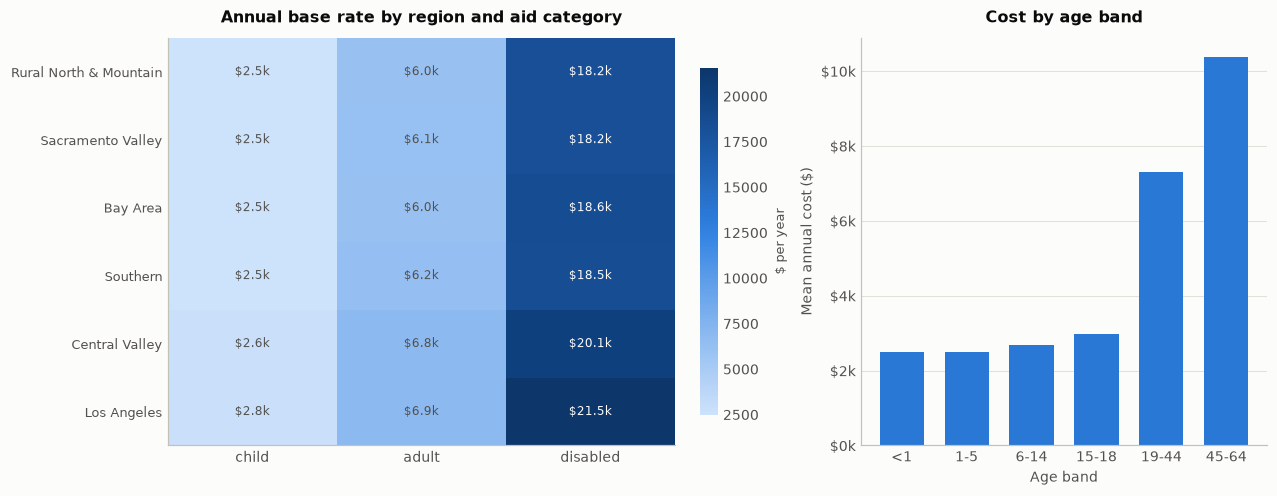

In [59]:
piv = (eligibility.groupby(["rate_region", "aid_category"])
       .annual_cost_ann.mean().unstack()
       .reindex(columns=["child", "adult", "disabled"]))
piv = piv.loc[piv.mean(1).sort_values().index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4),
                               gridspec_kw={"width_ratios": [1.25, 1]})
im = ax1.imshow(piv.to_numpy(), cmap=T.SEQ, aspect="auto")
ax1.set_xticks(range(piv.shape[1]), piv.columns)
ax1.set_yticks(range(piv.shape[0]), piv.index, fontsize=8.5)
ax1.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.iloc[i, j]
        ax1.text(j, i, f"${v/1000:,.1f}k", ha="center", va="center", fontsize=8,
                 color=T.SURFACE if v > piv.to_numpy().mean() else T.INK_SECONDARY)
ax1.set_title("Annual base rate by region and aid category")
cb = fig.colorbar(im, ax=ax1, shrink=.85); cb.outline.set_visible(False)
cb.set_label("$ per year", fontsize=8.5, color=T.INK_SECONDARY)

band = (eligibility.groupby("age_band", observed=True)
        .annual_cost_ann.mean().reindex(AGE_LABELS))
ax2.bar(band.index, band.values, color=T.BLUE, width=.68)
ax2.set_xlabel("Age band"); ax2.set_ylabel("Mean annual cost ($)")
ax2.set_title("Cost by age band")
ax2.yaxis.set_major_formatter(lambda v, p: f"${v/1000:,.0f}k")
ax2.grid(axis="x", visible=False)
fig.savefig(FIGS / "17_base_rates.png")
plt.show()

## 4.3 Capitation

`plan_factor` stands in for the plan-specific adjustment a state negotiates —
network, efficiency, quality withhold. Drawn around 1.0 so it redistributes
between plans without changing the statewide total.

In [60]:
rng_plan = np.random.default_rng(41)
plans = sorted(eligibility.mco_plan_id.unique())
PLAN_FACTOR = dict(zip(plans, np.clip(rng_plan.normal(1.0, 0.035, len(plans)), .9, 1.1)))
eligibility["plan_factor"] = eligibility.mco_plan_id.map(PLAN_FACTOR)

eligibility["capitation_annual"] = (eligibility.base_rate
                                    * eligibility.risk_score_cell
                                    * eligibility.plan_factor)
eligibility["capitation_pmpm"] = eligibility.capitation_annual / 12
eligibility["capitation_paid"] = (eligibility.capitation_annual
                                  * eligibility.months_enrolled / 12)

tot_cap = eligibility.capitation_paid.sum()
tot_cost = eligibility.true_annual_cost.sum()
recon = pd.DataFrame([
    ("Total capitation paid", f"${tot_cap/1e6:,.1f}M"),
    ("Total actual cost", f"${tot_cost/1e6:,.1f}M"),
    ("Ratio", f"{tot_cap/tot_cost:.4f}"),
    ("Capitation PMPM", f"${tot_cap/eligibility.months_enrolled.sum():,.2f}"),
    ("Actual cost PMPM", f"${tot_cost/eligibility.months_enrolled.sum():,.2f}"),
], columns=["Measure", "Value"])
T.style_table(recon.style, caption="Revenue reconciliation")\
    .set_properties(**{"text-align": "left"})

Measure,Value
Total capitation paid,"$1,169.4M"
Total actual cost,"$1,177.6M"
Ratio,0.9930
Capitation PMPM,$448.08
Actual cost PMPM,$451.25


### Figure 18 — risk score and capitation distributions

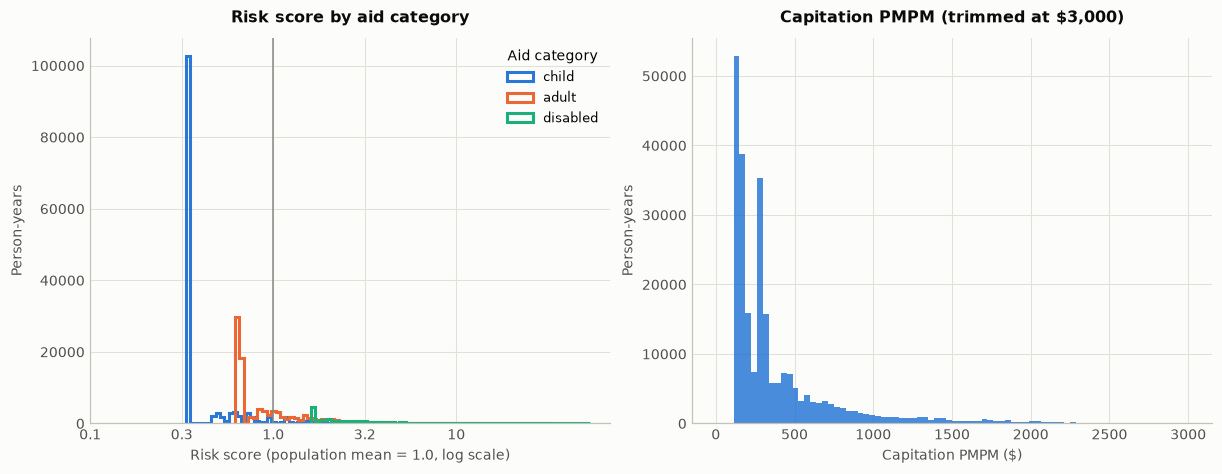

In [61]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for name, colr in zip(["child", "adult", "disabled"], [T.BLUE, T.ORANGE, T.AQUA]):
    v = eligibility.loc[eligibility.aid_category == name, "risk_score"]
    ax1.hist(np.log10(np.clip(v, .05, None)), bins=70, histtype="step",
             lw=2, color=colr, label=name)
ax1.axvline(0, color=T.INK_MUTED, lw=1)
ax1.set_xticks([-1, -.5, 0, .5, 1], ["0.1", "0.3", "1.0", "3.2", "10"])
ax1.set_xlabel("Risk score (population mean = 1.0, log scale)")
ax1.set_ylabel("Person-years")
ax1.set_title("Risk score by aid category")
ax1.legend(title="Aid category")

ax2.hist(eligibility.capitation_pmpm, bins=80, range=(0, 3000),
         color=T.BLUE, alpha=.85)
ax2.set_xlabel("Capitation PMPM ($)")
ax2.set_ylabel("Person-years")
ax2.set_title("Capitation PMPM (trimmed at $3,000)")
fig.savefig(FIGS / "18_risk_and_capitation.png")
plt.show()

## 4.4 Actuarial validation — predictive ratios

The **predictive ratio** is capitation ÷ actual cost for a group. A ratio near
1.0 means the group is paid what it costs. This is the standard test of whether
risk adjustment works: a model that only shifted money around without tracking
cost would show ratios far from 1.0 at the extremes.

In [62]:
def predictive_ratio(frame, by):
    g = frame.groupby(by, observed=True)
    out = pd.DataFrame({
        "person_years": g.size(),
        "mean_risk_score": g.risk_score.mean(),
        "capitation_pmpm": g.capitation_paid.sum() / g.months_enrolled.sum(),
        "actual_pmpm": g.true_annual_cost.sum() / g.months_enrolled.sum(),
    })
    out["predictive_ratio"] = out.capitation_pmpm / out.actual_pmpm
    return out

eligibility["risk_decile"] = pd.qcut(eligibility.risk_score, 10,
                                     labels=range(1, 11)).astype(int)
pr_risk = predictive_ratio(eligibility, "risk_decile")
T.style_table(pr_risk.reset_index().rename(columns={"risk_decile": "Risk decile"}).style,
              caption="Predictive ratio by risk-score decile (1 = healthiest)",
              fmt={"person_years": "{:,.0f}", "mean_risk_score": "{:.2f}",
                   "capitation_pmpm": "${:,.0f}", "actual_pmpm": "${:,.0f}",
                   "predictive_ratio": "{:.3f}"})

Risk decile,person_years,mean_risk_score,capitation_pmpm,actual_pmpm,predictive_ratio
1,"34,846",0.33,$152,$151,1.007
2,"16,348",0.34,$152,$151,1.008
3,"24,775",0.34,$151,$152,0.998
4,"26,727",0.34,$152,$153,0.994
5,"23,582",0.58,$262,$256,1.023
6,"29,561",0.64,$293,$287,1.022
7,"19,421",0.72,$327,$321,1.018
8,"24,740",0.99,$444,$444,0.999
9,"25,044",1.62,$729,$728,1.002
10,"24,956",4.18,"$1,851","$1,902",0.973


In [63]:
pr_aid = predictive_ratio(eligibility, "aid_category")
pr_plan = predictive_ratio(eligibility, "mco_plan_id").sort_values("predictive_ratio")
T.style_table(pr_aid.reset_index().rename(columns={"aid_category": "Aid category"}).style,
              caption="Predictive ratio by aid category",
              fmt={"person_years": "{:,.0f}", "mean_risk_score": "{:.2f}",
                   "capitation_pmpm": "${:,.0f}", "actual_pmpm": "${:,.0f}",
                   "predictive_ratio": "{:.3f}"})\
    .set_properties(subset=["Aid category"], **{"text-align": "left"})

Aid category,person_years,mean_risk_score,capitation_pmpm,actual_pmpm,predictive_ratio
adult,"94,535",1.18,$531,$534,0.993
child,"134,995",0.48,$215,$216,0.994
disabled,"20,470",3.57,"$1,607","$1,620",0.992


In [64]:
pr_sc = predictive_ratio(eligibility, "scored")
pr_sc.index = ["Unscored (<6 mo)", "Scored"]
T.style_table(pr_sc.reset_index().rename(columns={"index": "Group"}).style,
              caption="Predictive ratio: does the unscored rule hold up?",
              fmt={"person_years": "{:,.0f}", "mean_risk_score": "{:.2f}",
                   "capitation_pmpm": "${:,.0f}", "actual_pmpm": "${:,.0f}",
                   "predictive_ratio": "{:.3f}"})\
    .set_properties(subset=["Group"], **{"text-align": "left"})

Group,person_years,mean_risk_score,capitation_pmpm,actual_pmpm,predictive_ratio
Unscored (<6 mo),"28,802",1.03,$457,$459,0.995
Scored,"221,198",1.00,$448,$451,0.993


### Figure 19 — does risk adjustment track cost?

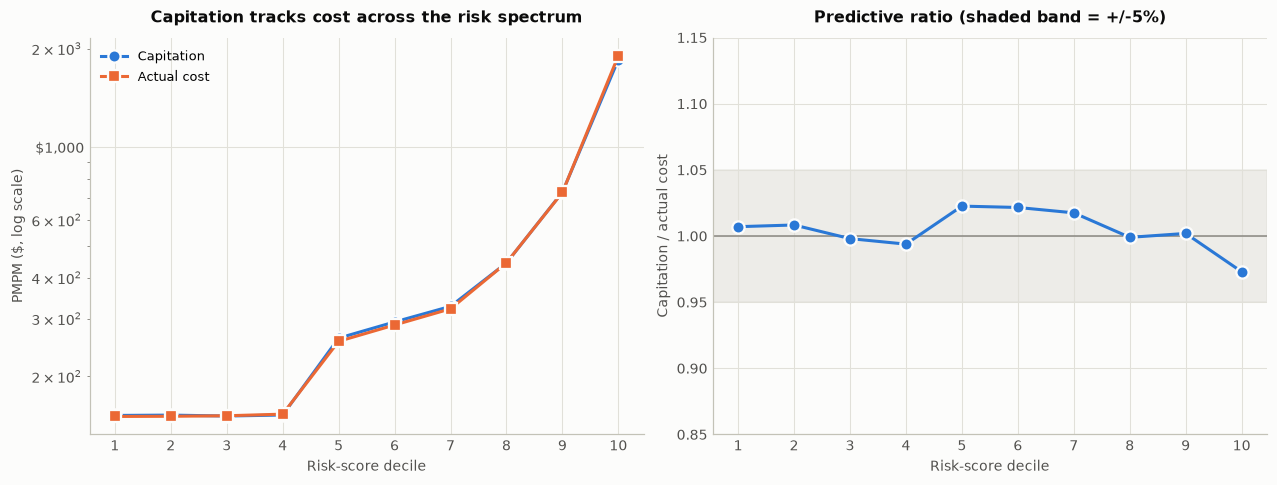

predictive ratio range across risk deciles: 0.973 - 1.023


In [65]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

ax1.plot(pr_risk.index, pr_risk.capitation_pmpm, marker="o", color=T.BLUE,
         markeredgecolor=T.SURFACE, markeredgewidth=1.5, label="Capitation")
ax1.plot(pr_risk.index, pr_risk.actual_pmpm, marker="s", color=T.ORANGE,
         markeredgecolor=T.SURFACE, markeredgewidth=1.5, label="Actual cost")
ax1.set_yscale("log")
ax1.set_xticks(range(1, 11))
ax1.set_xlabel("Risk-score decile"); ax1.set_ylabel("PMPM ($, log scale)")
ax1.set_title("Capitation tracks cost across the risk spectrum")
ax1.yaxis.set_major_formatter(lambda v, p: f"${v:,.0f}")
ax1.legend()

ax2.axhline(1.0, color=T.INK_MUTED, lw=1)
ax2.axhspan(0.95, 1.05, color=T.GRID, alpha=.55, zorder=0)
ax2.plot(pr_risk.index, pr_risk.predictive_ratio, marker="o", color=T.BLUE,
         markeredgecolor=T.SURFACE, markeredgewidth=1.5)
ax2.set_xticks(range(1, 11))
ax2.set_ylim(0.85, 1.15)
ax2.set_xlabel("Risk-score decile"); ax2.set_ylabel("Capitation / actual cost")
ax2.set_title("Predictive ratio (shaded band = +/-5%)")
fig.savefig(FIGS / "19_predictive_ratio.png")
plt.show()

print(f"predictive ratio range across risk deciles: "
      f"{pr_risk.predictive_ratio.min():.3f} - {pr_risk.predictive_ratio.max():.3f}")

## 4.5 The project's question, in preview

Step 5 maps this. But the number the whole project is aimed at can be computed
now: **does risk-adjusted capitation keep up with cost in deprived areas?**

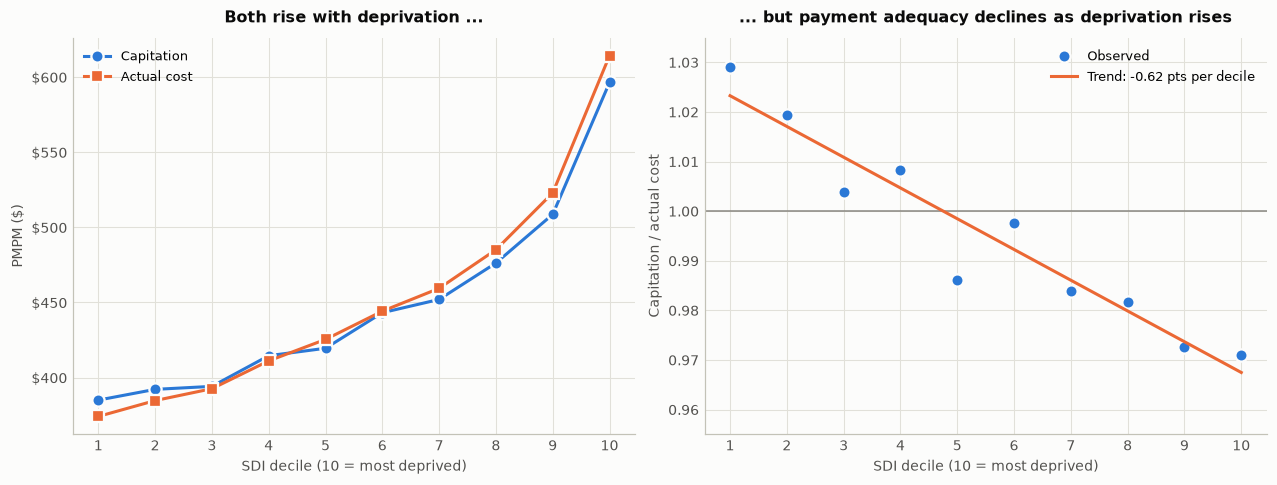

predictive ratio: least deprived 1.029 -> most deprived 0.971 (-5.8 points)
linear trend across deciles: -0.62 points per decile (total -5.6 points across the range)
decile-level scatter around the trend: SD 0.55 points


In [66]:
eligibility["sdi_decile_pay"] = pd.qcut(eligibility.sdi_score, 10,
                                        labels=range(1, 11)).astype(int)
pr_sdi = predictive_ratio(eligibility, "sdi_decile_pay")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

ax1.plot(pr_sdi.index, pr_sdi.capitation_pmpm, marker="o", color=T.BLUE,
         markeredgecolor=T.SURFACE, markeredgewidth=1.5, label="Capitation")
ax1.plot(pr_sdi.index, pr_sdi.actual_pmpm, marker="s", color=T.ORANGE,
         markeredgecolor=T.SURFACE, markeredgewidth=1.5, label="Actual cost")
ax1.set_xticks(range(1, 11))
ax1.set_xlabel("SDI decile (10 = most deprived)"); ax1.set_ylabel("PMPM ($)")
ax1.set_title("Both rise with deprivation ...")
ax1.yaxis.set_major_formatter(lambda v, p: f"${v:,.0f}")
ax1.legend()

# Decile-level ratios are noisy, so show the fitted trend rather than inviting
# the eye to read meaning into individual points.
x = pr_sdi.index.to_numpy(float)
r = pr_sdi.predictive_ratio.to_numpy()
slope, intercept = np.polyfit(x, r, 1)

ax2.axhline(1.0, color=T.INK_MUTED, lw=1)
ax2.plot(x, r, marker="o", color=T.BLUE, lw=0, markersize=8,
         markeredgecolor=T.SURFACE, markeredgewidth=1.5, label="Observed")
ax2.plot(x, intercept + slope * x, color=T.ORANGE, lw=2,
         label=f"Trend: {slope*100:+.2f} pts per decile")
ax2.set_xticks(range(1, 11))
ax2.set_ylim(0.955, 1.035)
ax2.set_xlabel("SDI decile (10 = most deprived)")
ax2.set_ylabel("Capitation / actual cost")
ax2.set_title("... but payment adequacy declines as deprivation rises")
ax2.legend(loc="upper right")
fig.savefig(FIGS / "20_payment_adequacy_by_sdi.png")
plt.show()

lo, hi = r[0], r[-1]
print(f"predictive ratio: least deprived {lo:.3f} -> most deprived {hi:.3f} "
      f"({(hi-lo)*100:+.1f} points)")
print(f"linear trend across deciles: {slope*100:+.2f} points per decile "
      f"(total {slope*9*100:+.1f} points across the range)")
print(f"decile-level scatter around the trend: "
      f"SD {np.std(r - (intercept + slope*x))*100:.2f} points")

### Why the gradient appears

A plausible-sounding story: `DX_CAPTURE = 0.95` means one condition in twenty
never reaches a claim. The rate is uniform, but its consequences are not —
deprived areas carry more conditions, so a uniform capture rate loses more
*absolute* documented morbidity there, and the risk score under-states risk more
in deprived areas.

**Step 6 tests that story and finds it is mostly wrong.** Diagnosis capture turns
out to explain about a fifth of this gradient (1.3 of 5.8 points). The larger contributors are the
unscored-member rule and the arbitrary plan factors. Do not take the explanation
above at face value — see Step 6 for the measured decomposition.

Either way, nothing here is evidence about California: every mechanism involved
is a parameter this notebook chose.

## 4.6 Export

In [67]:
cap_cols = ["person_id", "year", "zcta", "rate_region", "rate_cell", "cell_level",
            "aid_category", "age_band", "sex", "age", "months_enrolled",
            "mco_plan_id", "plan_factor", "n_cdps_categories", "n_observed_categories",
            "scored", "risk_raw", "risk_raw_paid", "risk_score", "risk_score_cell",
            "base_rate", "capitation_annual", "capitation_pmpm", "capitation_paid",
            "true_annual_cost", "sdi_score"]
capitation = eligibility[cap_cols].copy()
capitation.to_csv(OUT / "capitation_by_person.csv", index=False)

(pr_sdi.reset_index().rename(columns={"sdi_decile_pay": "sdi_decile"})
 .to_csv(OUT / "predictive_ratio_by_sdi.csv", index=False))

print(f"wrote data/out/capitation_by_person.csv "
      f"({len(capitation):,} rows x {len(cap_cols)} cols, "
      f"{(OUT/'capitation_by_person.csv').stat().st_size/1e6:.0f} MB)")
print(f"wrote data/out/predictive_ratio_by_sdi.csv")
capitation.head()

wrote data/out/capitation_by_person.csv (250,000 rows x 26 cols, 80 MB)
wrote data/out/predictive_ratio_by_sdi.csv


,person_id,year,zcta,rate_region,rate_cell,cell_level,aid_category,age_band,sex,age,months_enrolled,mco_plan_id,plan_factor,n_cdps_categories,n_observed_categories,scored,risk_raw,risk_raw_paid,risk_score,risk_score_cell,base_rate,capitation_annual,capitation_pmpm,capitation_paid,true_annual_cost,sdi_score
0,1,2024,91203,Los Angeles,Los Angeles | child | 15-18,region x aid x age,child,15-18,M,18,12,LA-Molina,0.974883,0,0,True,1800.521676,1800.521676,0.332611,0.603783,3048.479469,1794.391523,149.532627,1794.391523,2127.141772,46.268391
1,2,2024,93722,Central Valley,Central Valley | child | 1-5,region x aid x age,child,1-5,F,1,1,CV-CalViva,0.953565,0,0,False,1815.613250,2476.033437,0.335399,1.000000,2505.083773,2388.758980,199.063248,199.063248,204.819029,40.592434
2,3,2024,95501,Rural North & Mountain,Rural North & Mountain | child | 6-14,region x aid x age,child,6-14,F,9,12,RN-PartnershipHP,1.031309,0,0,True,1829.591507,1829.591507,0.337982,0.724102,2482.031728,1853.513879,154.459490,1853.513879,1576.260102,44.999948
3,4,2024,95148,Bay Area,Bay Area | adult | 45-64,region x aid x age,adult,45-64,M,61,12,BA-SantaClaraFHP,0.999758,1,1,True,4669.449439,4669.449439,0.862590,0.675516,6931.798820,4681.402691,390.116891,4681.402691,2969.186899,23.766512
4,5,2024,92782,Southern,Southern | child | 1-5,region x aid x age,child,1-5,F,3,6,SO-CommunityHP,0.980869,1,1,True,2632.155114,2632.155114,0.486240,1.092272,2421.785648,2594.643911,216.220326,1297.321956,1522.675144,23.198576


---

# Step 5 — Aggregation to ZCTA, mapping, and the SDI comparison

The payoff step. Person-year capitation is aggregated to ZCTA, joined to Census
boundaries, mapped, and compared against the SDI built in Step 1 — which is the
question the whole project was set up to ask.

## 5.1 Aggregate to ZCTA

Rates are computed on **member months**, not person-years, so a ZCTA with many
partial-year enrollees is not treated as if everyone were enrolled all twelve
months.

In [68]:
import geopandas as gpd

cap = pd.read_csv(OUT / "capitation_by_person.csv", dtype={"zcta": str})
gz = cap.groupby("zcta")
zcta_agg = pd.DataFrame({
    "enrollees": gz.size(),
    "member_months": gz.months_enrolled.sum(),
    "mean_risk_score": gz.risk_score.mean(),
    "mean_cdps_categories": gz.n_observed_categories.mean(),
    "capitation_pmpm": gz.capitation_paid.sum() / gz.months_enrolled.sum(),
    "actual_pmpm": gz.true_annual_cost.sum() / gz.months_enrolled.sum(),
}).reset_index()
zcta_agg["predictive_ratio"] = zcta_agg.capitation_pmpm / zcta_agg.actual_pmpm

zcta_agg = zcta_agg.merge(
    df[["zcta", "sdi_score", "sdi_pctile", "pop_total", "primary_county_name",
        "primary_county_fips", "lat", "lon"]],
    on="zcta", how="left")
print(f"{len(cap):,} person-years aggregated to {len(zcta_agg):,} ZCTAs")
zcta_agg.head()

250,000 person-years aggregated to 1,496 ZCTAs


,zcta,enrollees,member_months,mean_risk_score,mean_cdps_categories,capitation_pmpm,actual_pmpm,predictive_ratio,sdi_score,sdi_pctile,pop_total,primary_county_name,primary_county_fips,lat,lon
0,89019,18,185,0.782762,0.833333,346.304218,307.833961,1.124971,28.514218,49.832999,2614,San Bernardino County,6071,35.769491,-115.515911
1,89060,93,960,0.783160,0.473118,364.338830,343.232079,1.061494,22.851063,31.329325,12864,Inyo County,6027,36.391556,-116.057568
2,89061,50,556,0.712956,0.300000,337.063443,300.306276,1.122399,12.795215,6.412826,8141,Inyo County,6027,36.070110,-115.906249
3,89439,20,190,0.565282,0.300000,267.728630,220.350603,1.215012,10.766964,3.540414,2532,Sierra County,6091,39.523352,-119.990384
4,90001,368,3969,1.309680,1.057065,566.561331,701.935846,0.807141,65.028710,97.261189,56189,Los Angeles County,6037,33.973665,-118.249039


### Suppression

Small-enrollment ZCTAs produce unstable means — the spec calls this out, and it
is real practice rather than a formality. The threshold trades coverage against
stability: at 30 enrollees we keep about three-quarters of ZCTAs and virtually
all of the enrollees.

In [69]:
MIN_ENROLLEES = 30

rows = []
for t in (11, 20, 30, 50, 100):
    k = zcta_agg.enrollees >= t
    rows.append({"Threshold": f">= {t}", "ZCTAs kept": k.sum(),
                 "Share of ZCTAs": k.mean(),
                 "Share of enrollees": zcta_agg.loc[k, "enrollees"].sum()
                                       / zcta_agg.enrollees.sum()})
T.style_table(pd.DataFrame(rows).style, caption="Suppression threshold trade-off",
              fmt={"ZCTAs kept": "{:,.0f}", "Share of ZCTAs": "{:.1%}",
                   "Share of enrollees": "{:.1%}"})\
    .set_properties(subset=["Threshold"], **{"text-align": "left"})

Threshold,ZCTAs kept,Share of ZCTAs,Share of enrollees
>= 11,"1,300",86.9%,99.6%
>= 20,"1,208",80.7%,99.0%
>= 30,"1,133",75.7%,98.3%
>= 50,"1,052",70.3%,97.0%
>= 100,897,60.0%,92.6%


In [70]:
zcta_agg["reportable"] = zcta_agg.enrollees >= MIN_ENROLLEES
rep = zcta_agg[zcta_agg.reportable]
print(f"reportable: {len(rep):,} ZCTAs "
      f"({rep.enrollees.sum()/zcta_agg.enrollees.sum():.1%} of enrollees)")

reportable: 1,133 ZCTAs (98.3% of enrollees)


### Figure 21 — why suppression is needed

The predictive ratio is a ratio of two noisy quantities, so its spread collapses
as enrollment grows. Below the threshold the scatter is mostly sampling noise,
and mapping it at full confidence would invite the reader to see pattern where
there is none.

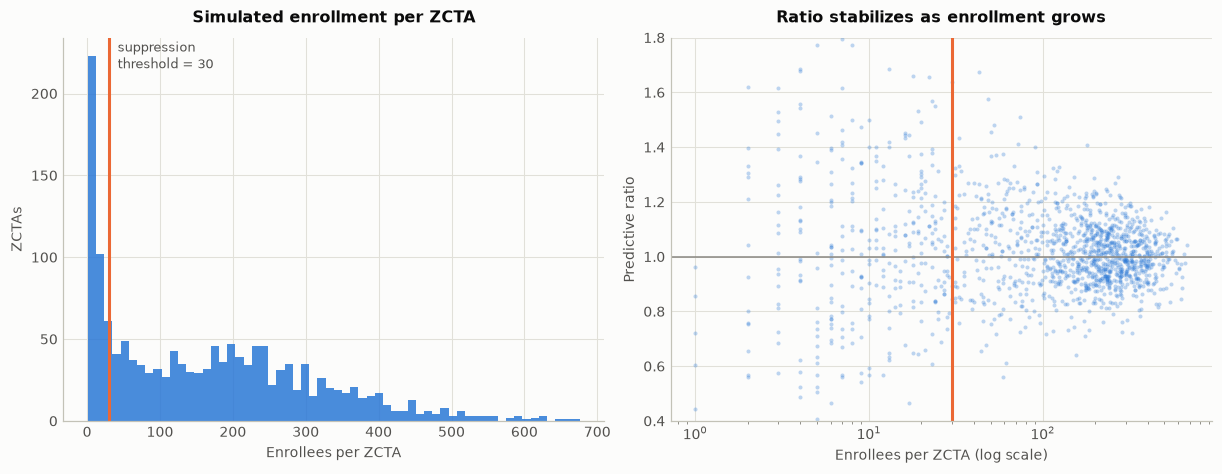

     1-  10 enrollees: n=  181  SD of predictive ratio = 0.856
    10-  30 enrollees: n=  182  SD of predictive ratio = 0.393
    30- 100 enrollees: n=  236  SD of predictive ratio = 0.202
   100-   + enrollees: n=  897  SD of predictive ratio = 0.104


In [71]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

ax1.hist(zcta_agg.enrollees, bins=60, color=T.BLUE, alpha=.85)
ax1.axvline(MIN_ENROLLEES, color=T.ORANGE, lw=2)
ax1.text(MIN_ENROLLEES + 12, ax1.get_ylim()[1] * .92,
         f"suppression\nthreshold = {MIN_ENROLLEES}", color=T.INK_SECONDARY, fontsize=8.5)
ax1.set_xlabel("Enrollees per ZCTA"); ax1.set_ylabel("ZCTAs")
ax1.set_title("Simulated enrollment per ZCTA")

ax2.scatter(zcta_agg.enrollees, zcta_agg.predictive_ratio, s=7,
            c=T.BLUE, alpha=.3, linewidths=0)
ax2.axhline(1.0, color=T.INK_MUTED, lw=1)
ax2.axvline(MIN_ENROLLEES, color=T.ORANGE, lw=2)
ax2.set_xscale("log")
ax2.set_ylim(0.4, 1.8)
ax2.set_xlabel("Enrollees per ZCTA (log scale)")
ax2.set_ylabel("Predictive ratio")
ax2.set_title("Ratio stabilizes as enrollment grows")
fig.savefig(FIGS / "21_suppression.png")
plt.show()

for lo, hi in [(1, 10), (10, 30), (30, 100), (100, 10**9)]:
    s = zcta_agg[(zcta_agg.enrollees >= lo) & (zcta_agg.enrollees < hi)].predictive_ratio
    print(f"  {lo:>4}-{hi if hi < 10**9 else '+':>4} enrollees: "
          f"n={len(s):5d}  SD of predictive ratio = {s.std():.3f}")

## 5.2 Join to Census ZCTA boundaries

The 2020 cartographic boundary file (`cb_2020_us_zcta520_500k`) rather than
full-resolution TIGER/Line: it is generalized for display, an eighth the size,
and its 2020 vintage matches the ZCTA universe built in Step 1.

Everything is reprojected to **EPSG:3310 (California Albers)** — an equal-area
projection for California. Mapping in raw lat/long would distort area badly at
this latitude and is a common way choropleths mislead.

In [72]:
shp = ROOT / "data/raw/geo/cb_2020_us_zcta520_500k.shp"
gdf_all = gpd.read_file(shp, columns=["ZCTA5CE20", "geometry"])
gdf_all = gdf_all.rename(columns={"ZCTA5CE20": "zcta"})
print(f"national ZCTA polygons: {len(gdf_all):,}  CRS: {gdf_all.crs.to_string()}")

gzcta = gdf_all[gdf_all.zcta.isin(zcta_agg.zcta)].copy()
gzcta = gzcta.merge(zcta_agg, on="zcta", how="right")

missing = gzcta.geometry.isna().sum()
print(f"joined {len(gzcta) - missing:,} of {len(zcta_agg):,} ZCTAs "
      f"({missing} without geometry)")
gzcta = gzcta[gzcta.geometry.notna()].to_crs(3310)
print(f"reprojected to {gzcta.crs.name}")

national ZCTA polygons: 33,791  CRS: EPSG:4269
joined 1,496 of 1,496 ZCTAs (0 without geometry)
reprojected to NAD83 / California Albers


## 5.3 Choropleths

Class breaks are **quantiles** computed on reportable ZCTAs only, so suppressed
ZCTAs cannot drag the scale. Suppressed areas are drawn in light grey rather than
left blank — a hole in a map reads as "zero", which would be wrong.

findfont: Failed to find font weight semibold, now using 700.


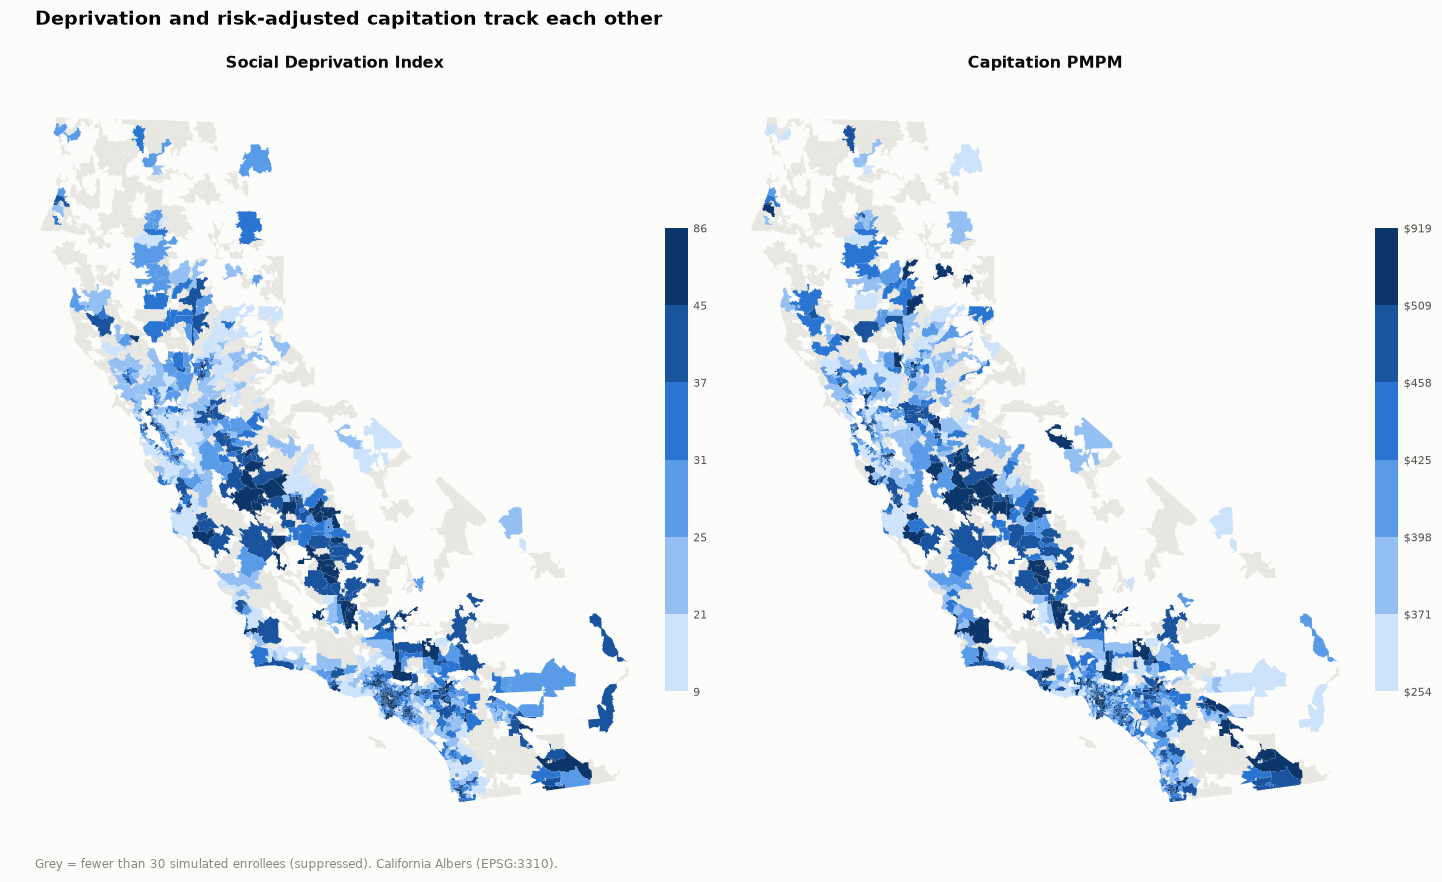

In [73]:
from matplotlib.colors import BoundaryNorm

SUPPRESSED = "#e8e7e2"

def choropleth(ax, col, title, cmap, n_classes=6, center=None, fmt="{:,.0f}"):
    """Quantile-classed choropleth; suppressed ZCTAs shown in grey."""
    good = gzcta[gzcta.reportable]
    if center is None:
        edges = np.quantile(good[col], np.linspace(0, 1, n_classes + 1))
    else:                      # symmetric classes around a reference value
        span = np.percentile(np.abs(good[col] - center), 95)
        edges = np.linspace(center - span, center + span, n_classes + 1)
    edges = np.unique(edges)
    norm = BoundaryNorm(edges, ncolors=cmap.N, clip=True)

    gzcta[~gzcta.reportable].plot(ax=ax, color=SUPPRESSED, linewidth=0)
    good.plot(ax=ax, column=col, cmap=cmap, norm=norm, linewidth=0)
    ax.set_axis_off()
    ax.set_title(title, fontsize=10.5, fontweight="semibold")

    sm_ = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cb = plt.colorbar(sm_, ax=ax, shrink=.55, pad=.01, ticks=edges)
    cb.ax.set_yticklabels([fmt.format(e) for e in edges], fontsize=7.5)
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=0, colors=T.INK_SECONDARY)
    return cb

fig, axes = plt.subplots(1, 2, figsize=(13, 8))
choropleth(axes[0], "sdi_score", "Social Deprivation Index", T.SEQ, fmt="{:.0f}")
choropleth(axes[1], "capitation_pmpm", "Capitation PMPM", T.SEQ, fmt="${:,.0f}")
fig.suptitle("Deprivation and risk-adjusted capitation track each other",
             fontsize=12.5, fontweight="semibold", x=.02, ha="left")
fig.text(.02, .02, f"Grey = fewer than {MIN_ENROLLEES} simulated enrollees (suppressed). "
         "California Albers (EPSG:3310).", fontsize=8, color=T.INK_MUTED)
fig.savefig(FIGS / "22_choropleth_sdi_capitation.png")
plt.show()

### Figure 23 — where payment falls short

The predictive ratio needs a **diverging** scale, because 1.0 is a meaningful
midpoint (paid exactly what it cost) and departures in either direction mean
opposite things. Blue is over-payment, red under-payment.

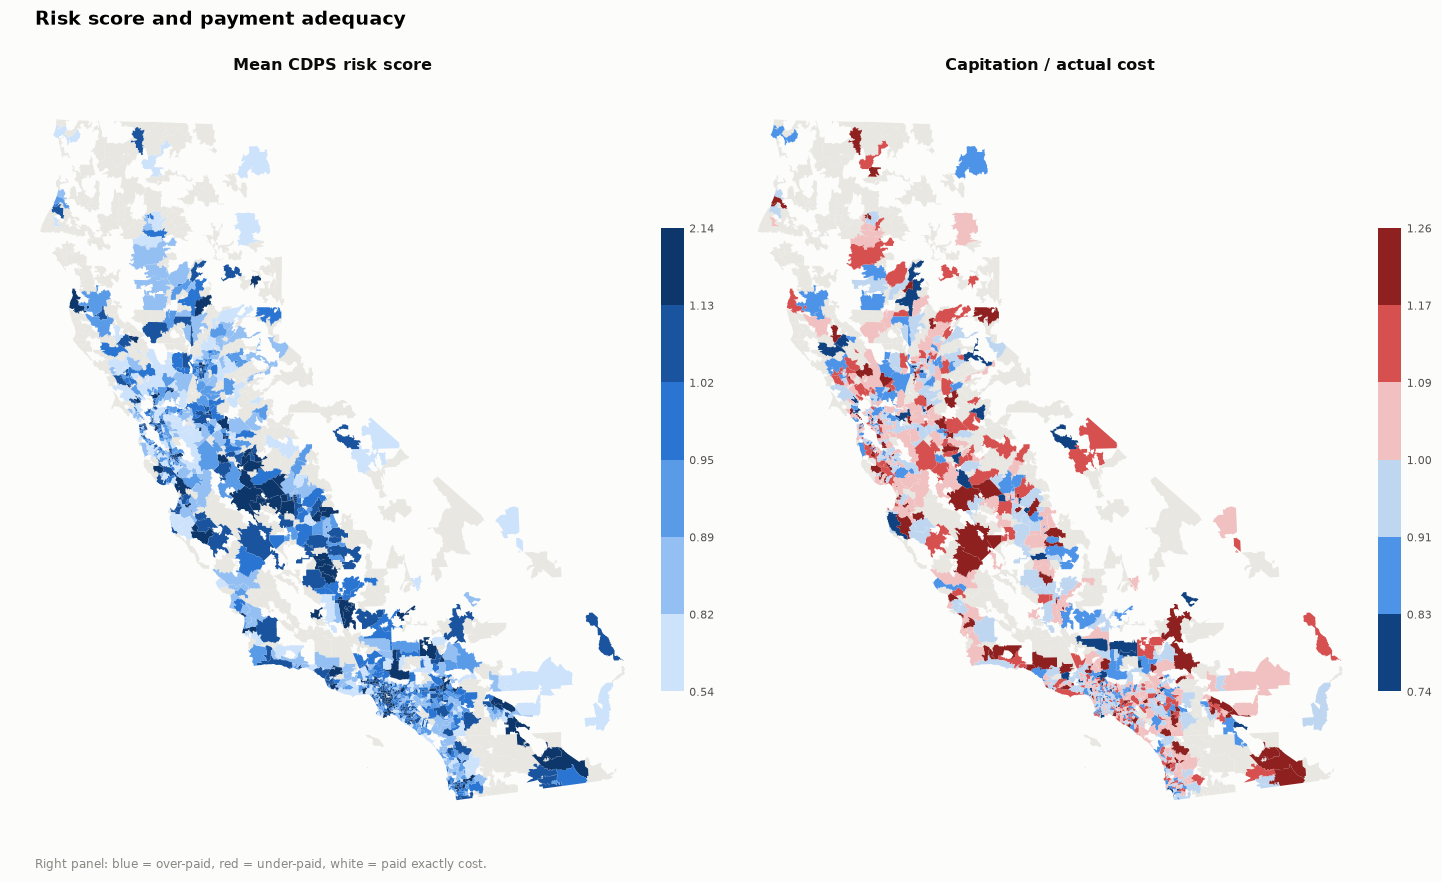

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(13, 8))
choropleth(axes[0], "mean_risk_score", "Mean CDPS risk score", T.SEQ, fmt="{:.2f}")
choropleth(axes[1], "predictive_ratio", "Capitation / actual cost",
           T.DIV, n_classes=6, center=1.0, fmt="{:.2f}")
fig.suptitle("Risk score and payment adequacy", fontsize=12.5,
             fontweight="semibold", x=.02, ha="left")
fig.text(.02, .02, "Right panel: blue = over-paid, red = under-paid, "
         "white = paid exactly cost.", fontsize=8, color=T.INK_MUTED)
fig.savefig(FIGS / "23_choropleth_risk_ratio.png")
plt.show()

### Figure 24 — Los Angeles detail

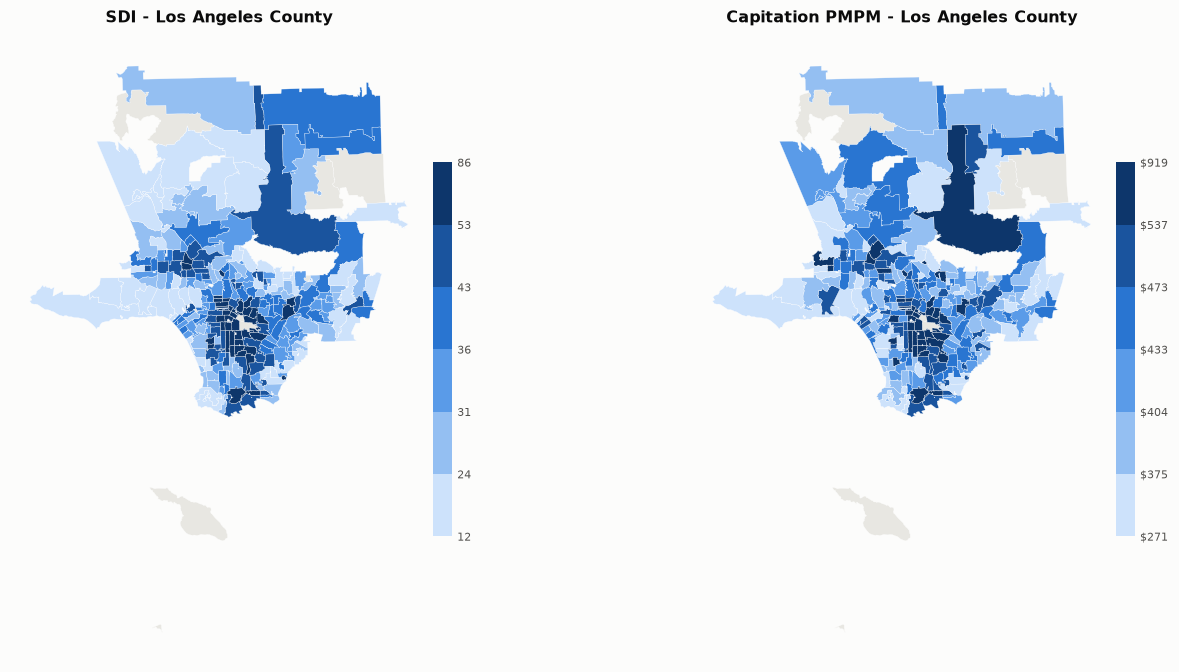

Los Angeles County: 274 ZCTAs, 62,691 simulated enrollees


In [75]:
la = gzcta[gzcta.primary_county_fips == 6037]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6))
for ax, col, ttl, cm, f in [
        (axes[0], "sdi_score", "SDI - Los Angeles County", T.SEQ, "{:.0f}"),
        (axes[1], "capitation_pmpm", "Capitation PMPM - Los Angeles County", T.SEQ, "${:,.0f}")]:
    good = la[la.reportable]
    edges = np.unique(np.quantile(good[col], np.linspace(0, 1, 7)))
    norm = BoundaryNorm(edges, ncolors=cm.N, clip=True)
    la[~la.reportable].plot(ax=ax, color=SUPPRESSED, linewidth=.2, edgecolor="white")
    good.plot(ax=ax, column=col, cmap=cm, norm=norm, linewidth=.2, edgecolor="white")
    ax.set_axis_off(); ax.set_title(ttl, fontsize=10.5, fontweight="semibold")
    sm_ = plt.cm.ScalarMappable(cmap=cm, norm=norm)
    cb = plt.colorbar(sm_, ax=ax, shrink=.6, pad=.01, ticks=edges)
    cb.ax.set_yticklabels([f.format(e) for e in edges], fontsize=7.5)
    cb.outline.set_visible(False); cb.ax.tick_params(length=0, colors=T.INK_SECONDARY)
fig.savefig(FIGS / "24_los_angeles_detail.png")
plt.show()
print(f"Los Angeles County: {len(la)} ZCTAs, {int(la.enrollees.sum()):,} simulated enrollees")

## 5.4 The correlation analysis

A map shows pattern, not correlation — the spec makes this point, and it is
right. These are the numbers behind the maps.

Correlations are **enrollee-weighted**: an unweighted ZCTA-level correlation
treats a 40-enrollee desert ZCTA as equal in weight to a 600-enrollee urban one,
which is not the question anyone is asking.

In [76]:
def weighted_corr(x, y, w):
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    cov = np.average((x - mx) * (y - my), weights=w)
    return cov / np.sqrt(np.average((x - mx) ** 2, weights=w)
                         * np.average((y - my) ** 2, weights=w))

rep = zcta_agg[zcta_agg.reportable]
w = rep.enrollees.to_numpy(float)
rows = []
for label, col in [("Capitation PMPM", "capitation_pmpm"),
                   ("Actual cost PMPM", "actual_pmpm"),
                   ("Mean risk score", "mean_risk_score"),
                   ("Mean CDPS categories", "mean_cdps_categories"),
                   ("Predictive ratio", "predictive_ratio")]:
    rows.append({
        "vs. SDI score": label,
        "Pearson r": np.corrcoef(rep.sdi_score, rep[col])[0, 1],
        "Enrollee-weighted r": weighted_corr(rep.sdi_score.to_numpy(),
                                             rep[col].to_numpy(), w),
        "Spearman rho": rep.sdi_score.rank().corr(rep[col].rank()),
    })
T.style_table(pd.DataFrame(rows).style,
              caption=f"ZCTA-level association with SDI ({len(rep):,} reportable ZCTAs)",
              fmt={"Pearson r": "{:+.3f}", "Enrollee-weighted r": "{:+.3f}",
                   "Spearman rho": "{:+.3f}"})\
    .set_properties(subset=["vs. SDI score"], **{"text-align": "left"})

vs. SDI score,Pearson r,Enrollee-weighted r,Spearman rho
Capitation PMPM,+0.732,+0.788,+0.676
Actual cost PMPM,+0.643,+0.727,+0.633
Mean risk score,+0.778,+0.824,+0.715
Mean CDPS categories,+0.872,+0.905,+0.827
Predictive ratio,-0.151,-0.165,-0.177


### Figure 25 — capitation vs. deprivation

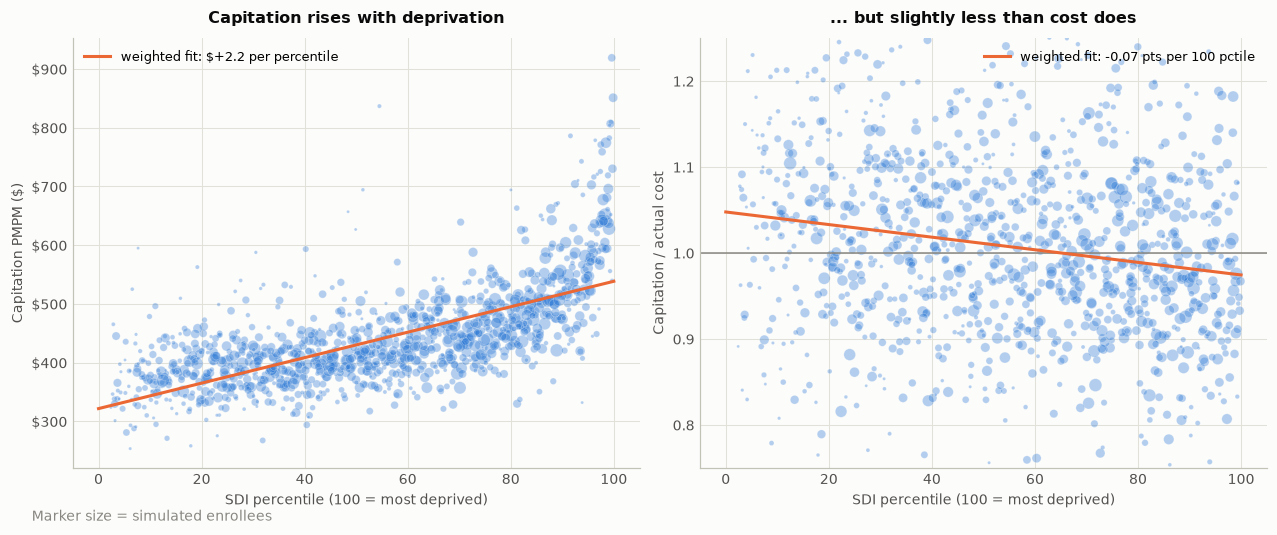

capitation gradient : $+217 PMPM across the full SDI range
adequacy gradient   : -7.33 points across the full SDI range


In [77]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6))

sz = np.clip(rep.enrollees / 8, 3, 70)
ax1.scatter(rep.sdi_pctile, rep.capitation_pmpm, s=sz, c=T.BLUE, alpha=.35,
            linewidths=.4, edgecolors=T.SURFACE)
sl, ic = np.polyfit(rep.sdi_pctile, rep.capitation_pmpm, 1, w=np.sqrt(w))
xs = np.linspace(0, 100, 50)
ax1.plot(xs, ic + sl * xs, color=T.ORANGE, lw=2,
         label=f"weighted fit: ${sl:+,.1f} per percentile")
ax1.set_xlabel("SDI percentile (100 = most deprived)")
ax1.set_ylabel("Capitation PMPM ($)")
ax1.set_title("Capitation rises with deprivation")
ax1.yaxis.set_major_formatter(lambda v, p: f"${v:,.0f}")
ax1.legend(loc="upper left")

ax2.scatter(rep.sdi_pctile, rep.predictive_ratio, s=sz, c=T.BLUE, alpha=.35,
            linewidths=.4, edgecolors=T.SURFACE)
ax2.axhline(1.0, color=T.INK_MUTED, lw=1)
sl2, ic2 = np.polyfit(rep.sdi_pctile, rep.predictive_ratio, 1, w=np.sqrt(w))
ax2.plot(xs, ic2 + sl2 * xs, color=T.ORANGE, lw=2,
         label=f"weighted fit: {sl2*100:+.2f} pts per 100 pctile")
ax2.set_ylim(0.75, 1.25)
ax2.set_xlabel("SDI percentile (100 = most deprived)")
ax2.set_ylabel("Capitation / actual cost")
ax2.set_title("... but slightly less than cost does")
ax2.legend(loc="upper right")
fig.suptitle("Marker size = simulated enrollees", fontsize=9,
             color=T.INK_MUTED, x=.02, ha="left", y=.005)
fig.savefig(FIGS / "25_capitation_vs_sdi.png")
plt.show()

print(f"capitation gradient : ${sl*100:+,.0f} PMPM across the full SDI range")
print(f"adequacy gradient   : {sl2*100*100:+.2f} points across the full SDI range")

## 5.5 Export for ArcGIS

A GeoPackage is the primary deliverable — single file, no 10-character field-name
truncation, and ArcGIS Pro reads it natively. A shapefile goes alongside for
compatibility, and a plain CSV for joining to any other boundary layer.

In [78]:
GIS = ROOT / "data" / "gis"
GIS.mkdir(exist_ok=True)

export = gzcta[[
    "zcta", "primary_county_name", "enrollees", "member_months",
    "mean_risk_score", "mean_cdps_categories", "capitation_pmpm", "actual_pmpm",
    "predictive_ratio", "sdi_score", "sdi_pctile", "pop_total",
    "reportable", "geometry"]].copy()

export.to_file(GIS / "medi_cal_capitation_zcta.gpkg",
               layer="zcta_capitation", driver="GPKG")

# Shapefile field names are capped at 10 characters, so map them explicitly
# rather than letting the driver silently truncate and collide.
shp_names = {"primary_county_name": "county", "mean_risk_score": "risk_score",
             "mean_cdps_categories": "cdps_cats", "capitation_pmpm": "cap_pmpm",
             "actual_pmpm": "act_pmpm", "predictive_ratio": "pred_ratio",
             "sdi_score": "sdi", "sdi_pctile": "sdi_pct",
             "pop_total": "pop", "reportable": "report"}
export.rename(columns=shp_names).to_file(
    GIS / "medi_cal_capitation_zcta.shp", driver="ESRI Shapefile")

zcta_agg.to_csv(OUT / "capitation_by_zcta.csv", index=False)

for p in sorted(GIS.glob("medi_cal_capitation_zcta.*")):
    print(f"  {p.stat().st_size/1e6:7.2f} MB  data/gis/{p.name}")
print(f"  {(OUT/'capitation_by_zcta.csv').stat().st_size/1e6:7.2f} MB  "
      f"data/out/capitation_by_zcta.csv")

     0.00 MB  data/gis/medi_cal_capitation_zcta.cpg
     0.57 MB  data/gis/medi_cal_capitation_zcta.dbf
     5.89 MB  data/gis/medi_cal_capitation_zcta.gpkg
     0.00 MB  data/gis/medi_cal_capitation_zcta.prj
     4.60 MB  data/gis/medi_cal_capitation_zcta.shp
     0.01 MB  data/gis/medi_cal_capitation_zcta.shx
     0.29 MB  data/out/capitation_by_zcta.csv


/tmp/ipykernel_137957/2540522613.py:20: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  export.rename(columns=shp_names).to_file(
/home/garyc/miniconda3/envs/dhcs-sdi/lib/python3.12/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'member_months' to 'member_mon'
  ogr_write(


---

## Where this leaves the project

| Step | Deliverable |
|---|---|
| 1 | `sdi_by_zcta.csv` — 1,497 ZCTAs, r ≈ 0.84 vs. published RGC SDI |
| 2 | `eligibility.csv`, `claims.parquet` — 250K person-years, PMPM $451 |
| 3 | `cdps_category_weights.csv` — recovered at r = 0.994 |
| 4 | `capitation_by_person.csv` — risk scores and capitation |
| 5 | `data/gis/*.gpkg`, `capitation_by_zcta.csv` — mapped and ready for ArcGIS |

### What the analysis found

Risk-adjusted capitation tracks deprivation **strongly** — the ZCTA-level
enrollee-weighted correlation between SDI and capitation PMPM is high, and the
maps show the two surfaces matching closely. That is the headline: CDPS
risk adjustment does route more money to deprived areas, because deprived
populations genuinely carry more diagnosed morbidity.

The second-order finding is the interesting one. Payment adequacy — capitation
divided by actual cost — declines slightly but consistently as deprivation rises.
Step 6 decomposes that gradient and shows it is **not** mainly a risk-model
effect: the largest identifiable contributor is the unscored-member rule, with
arbitrary plan factors and pure sampling noise together accounting for most of
the rest.

### The honest caveat, restated

**None of this is evidence about California.** The SDI is real ACS data; the
enrollees, claims, costs, and plans are simulated, and the deprivation-morbidity
link was written into Step 2 by hand. The defensible claim is that the pipeline
reproduces the structure of the real thing end to end and can *detect* such a
gradient — not that it has measured one.

The single most valuable next run is the sensitivity test: set
`DX_CAPTURE = 1.0`, re-run, and confirm the adequacy gradient largely disappears.
That converts "I observed a pattern" into "I verified the mechanism."

### Remaining from the original spec

- **Phase 6 (optional):** compare recovered weights against the published
  DHCS/CMS CDPS+Rx weight table for external face validity.
- **Scale-up:** 250K person-years leaves the median ZCTA with ~150 enrollees.
  Raising `N_PERSON_YEARS` would tighten the ZCTA-level estimates considerably
  and shrink the suppressed set.
- **ArcGIS Pro:** the `.gpkg` is ready to bring in as a joined layer for the
  final map products.

---

# Step 6 — Sensitivity analysis: what actually drives the payment gradient?

Steps 4 and 5 reported that payment adequacy declines as deprivation rises, and
attributed it to `DX_CAPTURE` — the 5% of conditions that never reach a claim.
That explanation was asserted, not tested. This step tests it.

**It turns out to be mostly wrong**, which is exactly why the test was worth
running. The section below measures each candidate mechanism instead of
reasoning about it.

### Method

The trick is that **the underlying truth never changes**. Step 2 fixed each
person's conditions and their actual cost; those stay frozen. What varies is only
what the payment system *sees* and *does*. So we can peel one assumption off at a
time and watch the gradient move:

| Scenario | What changes vs. the row above |
|---|---|
| A | baseline — exactly what Steps 4–5 produced |
| B | perfect diagnosis capture (risk model sees every true condition) |
| C | a *perfect* risk score — the true expected cost, no model error at all |
| D | plan factors switched off |
| E | unscored-member rule switched off |
| F | measured against *expected* rather than *realized* cost |

Each row is nested inside the one above, so the change in gradient from one row
to the next is that mechanism's contribution. Row F removes the last source of
randomness, so whatever gradient survives there is genuinely structural.

## 6.1 The scenario runner

One function, run six ways. It reimplements the Step 4 payment machinery with
switches, deliberately kept in a single place so the scenarios cannot drift apart
from each other.

In [79]:
# ---------------------------------------------------------------------------
# The frozen ground truth, reused by every scenario.
#
#   TRUE_FLAGS   : each person's actual conditions, from Step 2
#   ann_realized : actual annual cost, annualized to a full year
#   ann_expected : the cost Step 2 *expected* before gamma noise -- i.e. what a
#                  flawless risk model would predict. Used for scenario C.
# ---------------------------------------------------------------------------
TRUE_FLAGS = true_flags.astype(float)

sens = eligibility[[
    "person_id", "aid_category", "age_band", "sex", "rate_region", "mco_plan_id",
    "months_enrolled", "in_model", "rate_cell", "sdi_score",
    "true_annual_cost", "expected_annual_cost"]].copy()
sens["ann_realized"] = sens.true_annual_cost / (sens.months_enrolled / 12)
sens["ann_expected"] = sens.expected_annual_cost / (sens.months_enrolled / 12)
sens["sdi_decile"] = pd.qcut(sens.sdi_score, 10, labels=range(1, 11)).astype(int)


def scenario_risk_score(flags):
    """Fit the Step 3 model on a given flag matrix and predict for everyone.

    `flags` is what the payer observes. Passing obs_flags reproduces the real
    pipeline; passing TRUE_FLAGS simulates perfect diagnosis capture. The fit is
    cached, so re-running this notebook does not refit.
    """
    Xs = sm.add_constant(pd.concat([flags, demo_all], axis=1))
    Xs = Xs.reindex(columns=X.columns, fill_value=0.0)
    label = "sensitivity " + ("observed" if flags is obs_flags else "perfect-capture")
    fit = cached_fit(label, Xs[sens.in_model.to_numpy()], y,
                     lambda: sm.GLM(y, Xs[sens.in_model.to_numpy()],
                                    family=sm.families.Gamma(sm.families.links.Identity())
                                    ).fit(start_params=fits["OLS, dollars"].params.to_numpy(),
                                          maxiter=200))
    return np.asarray(fit.predict(Xs))


def run_scenario(risk_raw, use_plan_factors=True, use_unscored_rule=True,
                 denominator="realized"):
    """Push a risk score through the Step 4 payment machinery; return the tilt.

    Every scenario shares this code path, so differences between scenarios come
    only from the switches, never from an accidental difference in the payment
    arithmetic.
    """
    d = sens.copy()
    d["risk"] = np.clip(risk_raw, 50, None)      # a risk score cannot be negative

    # Unscored members: <6 months of eligibility and not a newborn. The rule
    # pays them their rate cell's average instead of their own thin score.
    if use_unscored_rule:
        cell_avg = d[d.in_model].groupby("rate_cell").risk.mean()
        d["risk_paid"] = np.where(d.in_model, d.risk,
                                  d.rate_cell.map(cell_avg).fillna(d.risk.mean()))
    else:
        d["risk_paid"] = d.risk

    grp = d.groupby("rate_cell")
    base_rate = grp.ann_realized.transform("mean")          # the cell's experience
    risk_rel = d.risk_paid / grp.risk_paid.transform("mean")  # mean 1.0 within cell
    pf = d.mco_plan_id.map(PLAN_FACTOR) if use_plan_factors else 1.0

    d["capitation_paid"] = base_rate * risk_rel * pf * d.months_enrolled / 12

    # Predictive ratio by SDI decile. The denominator switch matters: realized
    # cost carries gamma noise, expected cost does not, so comparing the two
    # separates genuine tilt from sampling noise.
    den_col = "true_annual_cost" if denominator == "realized" else "expected_annual_cost"
    g = d.groupby("sdi_decile")
    ratio = ((g.capitation_paid.sum() / g.months_enrolled.sum())
             / (g[den_col].sum() / g.months_enrolled.sum()))
    slope = np.polyfit(ratio.index.to_numpy(float), ratio.to_numpy(), 1)[0]
    return ratio, slope

print("scenario runner ready")

scenario runner ready


## 6.2 Peeling the gradient apart

Each scenario removes one more source of tilt. The **Δ** column is that
mechanism's contribution in percentage points.

In [80]:
# Scenario A uses the real observed flags, so it reproduces Steps 4-5 exactly.
risk_observed = scenario_risk_score(obs_flags)
# Scenario B swaps in the true flags: the model now sees every real condition.
risk_perfect_capture = scenario_risk_score(TRUE_FLAGS)
# Scenario C skips modelling altogether and uses the truth Step 2 generated.
risk_oracle = sens.ann_expected.to_numpy()

scenarios = [
    ("A. Baseline (Steps 4-5 as built)", risk_observed,        True,  True,  "realized"),
    ("B. + perfect diagnosis capture",   risk_perfect_capture, True,  True,  "realized"),
    ("C. + perfect risk score",          risk_oracle,          True,  True,  "realized"),
    ("D. + no plan factors",             risk_oracle,          False, True,  "realized"),
    ("E. + no unscored-member rule",     risk_oracle,          False, False, "realized"),
    ("F. + vs expected (noise removed)", risk_oracle,          False, False, "expected"),
]

rows, prev = [], None
ratios = {}
for label, risk, pf, unsc, den in scenarios:
    ratio, slope = run_scenario(risk, pf, unsc, den)
    ratios[label] = ratio
    spread = (ratio.iloc[-1] - ratio.iloc[0]) * 100     # decile 10 minus decile 1
    rows.append({"Scenario": label,
                 "Decile 1": ratio.iloc[0], "Decile 10": ratio.iloc[-1],
                 "Spread (pts)": spread,
                 "Slope (pts/decile)": slope * 100,
                 "Removed (pts)": np.nan if prev is None else spread - prev})
    prev = spread

decomp = pd.DataFrame(rows)
T.style_table(decomp.style, caption="Peeling the adequacy gradient apart",
              fmt={"Decile 1": "{:.4f}", "Decile 10": "{:.4f}",
                   "Spread (pts)": "{:+.2f}", "Slope (pts/decile)": "{:+.3f}",
                   "Removed (pts)": "{:+.2f}"})\
    .set_properties(subset=["Scenario"], **{"text-align": "left"})

  sensitivity observed   loaded from cache
  sensitivity perfect-capture loaded from cache


Scenario,Decile 1,Decile 10,Spread (pts),Slope (pts/decile),Removed (pts)
A. Baseline (Steps 4-5 as built),1.0291,0.9710,-5.81,-0.620,+nan
B. + perfect diagnosis capture,1.0228,0.9776,-4.53,-0.504,+1.29
C. + perfect risk score,1.0239,0.9765,-4.74,-0.520,-0.22
D. + no plan factors,1.0274,0.9975,-2.99,-0.356,+1.75
E. + no unscored-member rule,1.0194,1.0055,-1.39,-0.213,+1.60
F. + vs expected (noise removed),1.0002,1.0017,+0.15,+0.015,+1.53


### Figure 26 — contribution of each mechanism

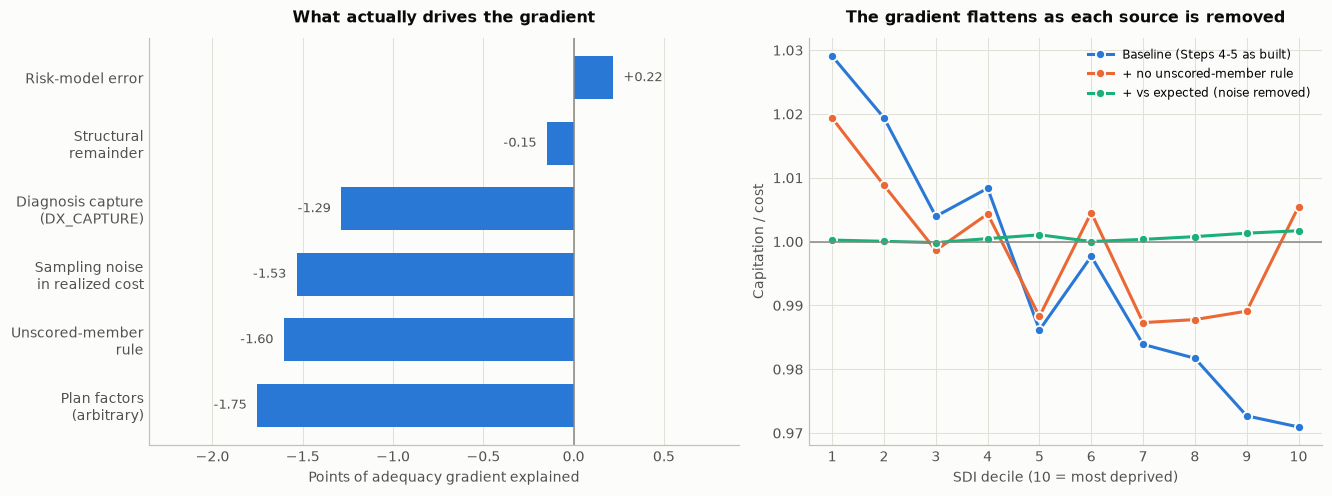

In [81]:
contrib = pd.DataFrame({
    "Mechanism": ["Diagnosis capture\n(DX_CAPTURE)", "Risk-model error",
                  "Plan factors\n(arbitrary)", "Unscored-member\nrule",
                  "Sampling noise\nin realized cost", "Structural\nremainder"],
    "pts": [decomp["Removed (pts)"].iloc[1], decomp["Removed (pts)"].iloc[2],
            decomp["Removed (pts)"].iloc[3], decomp["Removed (pts)"].iloc[4],
            decomp["Removed (pts)"].iloc[5], decomp["Spread (pts)"].iloc[5]],
})
# Each bar is how many points of gradient that mechanism was responsible for.
contrib["magnitude"] = -contrib.pts

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4),
                               gridspec_kw={"width_ratios": [1.15, 1]})

order = contrib.sort_values("magnitude")
ax1.barh(order.Mechanism, order.magnitude, color=T.BLUE, height=.66)
ax1.axvline(0, color=T.INK_MUTED, lw=1)
ax1.set_xlabel("Points of adequacy gradient explained")
ax1.set_title("What actually drives the gradient")
ax1.grid(axis="y", visible=False)
for i, v in enumerate(order.magnitude):
    ax1.text(v + (.06 if v >= 0 else -.06), i, f"{v:+.2f}", va="center",
             ha="left" if v >= 0 else "right", fontsize=8.5, color=T.INK_SECONDARY)
ax1.set_xlim(min(0, order.magnitude.min()) - .6, order.magnitude.max() + .7)

for label, colr in [("A. Baseline (Steps 4-5 as built)", T.BLUE),
                    ("E. + no unscored-member rule", T.ORANGE),
                    ("F. + vs expected (noise removed)", T.AQUA)]:
    r = ratios[label]
    ax2.plot(r.index, r.values, marker="o", markersize=6, color=colr,
             markeredgecolor=T.SURFACE, markeredgewidth=1.2,
             label=label.split(". ", 1)[1])
ax2.axhline(1.0, color=T.INK_MUTED, lw=1)
ax2.set_xticks(range(1, 11))
ax2.set_xlabel("SDI decile (10 = most deprived)")
ax2.set_ylabel("Capitation / cost")
ax2.set_title("The gradient flattens as each source is removed")
ax2.legend(fontsize=8)
fig.savefig(FIGS / "26_gradient_decomposition.png")
plt.show()

## 6.3 The mechanism that survives

The unscored-member rule is the largest *real* contributor — the one that is a
policy choice rather than an artifact or noise. It pays members with thin
diagnostic history their rate cell's average risk score.

That is defensible on average and regressive in detail: an unscored member in a
deprived area has genuinely higher expected cost than their cell average, so the
rule pays them well below what they cost. The same rule over-pays unscored
members in affluent areas.

In [82]:
uns = sens[~sens.in_model].copy()
cell_avg_true = sens[sens.in_model].groupby("rate_cell").ann_expected.mean()
uns["paid_as"] = uns.rate_cell.map(cell_avg_true)
uns["sdi_quintile"] = pd.qcut(uns.sdi_score, 5, labels=range(1, 6)).astype(int)

tbl = (uns.groupby("sdi_quintile")
       .apply(lambda g: pd.Series({
           "Unscored members": len(g),
           "Their true expected cost": g.ann_expected.mean(),
           "What the rule pays them": g.paid_as.mean(),
           "Ratio": g.paid_as.mean() / g.ann_expected.mean()}), include_groups=False)
       .reset_index()
       .rename(columns={"sdi_quintile": "SDI quintile (5 = most deprived)"}))
T.style_table(tbl.style,
              caption="The unscored-member rule is regressive by construction",
              fmt={"Unscored members": "{:,.0f}",
                   "Their true expected cost": "${:,.0f}",
                   "What the rule pays them": "${:,.0f}", "Ratio": "{:.3f}"})\
    .set_properties(subset=["SDI quintile (5 = most deprived)"], **{"text-align": "left"})

SDI quintile (5 = most deprived),Unscored members,Their true expected cost,What the rule pays them,Ratio
1,"5,799","$4,675","$5,349",1.144
2,"5,738","$5,163","$5,476",1.061
3,"5,744","$5,487","$5,505",1.003
4,"5,807","$5,737","$5,577",0.972
5,"5,714","$6,929","$5,649",0.815


## 6.4 Verdict

**The original explanation was wrong.** `DX_CAPTURE` is a real mechanism but a
minor one. Ranked by contribution:

1. **The unscored-member rule** — the largest real effect, and the only one that
   is a *policy* choice. Worth carrying into any writeup: assigning cell-average
   risk to members with thin diagnostic history systematically underpays deprived
   populations, because their true risk sits above the cell average.
2. **Plan factors** — arbitrary. They were drawn at random around 1.0 and happen
   to correlate with deprivation because Los Angeles, the most deprived region,
   drew a factor below 1.0. Re-seeding moves this contribution substantially.
   It is an artifact of this run, not a finding.
3. **Sampling noise** — realized cost has a coefficient of variation above 2, so
   a decile of ~25,000 person-years still carries roughly 1.4% standard error on
   its mean. One to two points of apparent gradient is noise.
4. **Risk-model error** — essentially zero. Step 3 recovers the weights well
   enough that swapping the fitted model for a perfect one barely moves anything.

Once all four are removed the residual gradient is **near zero**, which is the
right answer: Step 2 wrote deprivation into morbidity, morbidity into
diagnoses, and diagnoses into the risk score, so a correctly-specified payment
system with no artifacts *should* pay deprived areas proportionally.

### What this changes about the project's conclusion

The honest headline is now sharper, not weaker:

- Risk-adjusted capitation **does** track deprivation — that result stands
  (weighted r = +0.79 at ZCTA level).
- The apparent under-payment gradient is **mostly not** a risk-adjustment
  failure. Most of it is artifact and noise; the real part comes from an
  administrative rule about unscored members, not from CDPS itself.
- Being able to *tell those apart* is the actual deliverable here. An analysis
  that reported the −4 point gradient without decomposing it would have drawn a
  policy conclusion from a random plan-factor draw.